In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install torch torchvision timm albumentations
!pip install segmentation-models-pytorch  transformers datasets evaluate accelerate
!pip install wandb
!pip install nibabel monai -q
!pip install medpy
!pip install yacs
!pip install fvcore thop

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [segmentation-models-pytorch]
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 MB 122.6 MB/s  0:00:00
  Created wheel for medpy: filename=medpy-0.5.2-py3-none-any.whl size=224807 sha256=58e7b8d1bae271e2d702519bdbba3c180f326534a0456a596c4fe6b8dcd32aa9
  Stored in directory: /root/.cache/pip/wheels/c6/bb/54/dd8ad5c6158ef5912afb166e11ed95aa16b341fcc74ff1016d
Successfully built medpy
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [medpy]
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for fvcore: filename=fvcore-0.1.5.post20221221-py3-none-any.whl size=61447 sha256=533e1

In [ ]:
!pip install ml_collections

In [ ]:
# create project repository
import os

PROJECT_PATH = "/content/drive/MyDrive/Optimizing VITs/code_v2/"

folders = [
    "data/raw",
    "data/processed",
    "data/splits",
    "configs",
    "models/backbones",
    "models/modules",
    "models/hybrid",
    "training",
    "evaluation",
    "utils",
    "experiments",
    "logs",
    "outputs/checkpoints",
    "outputs/predictions",
    "outputs/figures",
    "notebooks"
]

for f in folders:
    os.makedirs(os.path.join(PROJECT_PATH, f), exist_ok=True)

print("Folder structure created!")

Folder structure created!


In [ ]:
files = {
    "configs/config.yaml": "",
    "models/hybrid/proposed_model.py": "",
    "models/modules/attention.py": "",
    "training/train.py": "",
    "training/trainer.py": "",
    "evaluation/metrics.py": "",
    "evaluation/evaluate.py": "",
    "utils/dataloader.py": "",
    "utils/losses.py": "",
}

for path, content in files.items():
    full_path = os.path.join(PROJECT_PATH, path)
    with open(full_path, "w") as f:
        f.write(content)

print("python files created!")

python files created!


In [ ]:
"""
Copy the official Swin-Unet and TransUNet code into the project and download the
ImageNet-pretrained encoder weights used by every model.

Run once per fresh runtime (notebook cell or `!python setup_repos.py`). Safe to re-run.
Requires: pip install timm einops yacs ml_collections transformers
"""
import os
import subprocess
import urllib.request
from pathlib import Path

PROJECT_PATH = os.environ.get("PROJECT_PATH", "/content/drive/MyDrive/Optimizing VITs/code_v2")
CLONE_ROOT = os.environ.get("CLONE_ROOT", "/content")
SWIN_CLONE_DIR = os.path.join(CLONE_ROOT, "Swin-Unet")
TRANSUNET_CLONE_DIR = os.path.join(CLONE_ROOT, "TransUNet_Official")
PRETRAINED_DIR = os.path.join(PROJECT_PATH, "pretrained")

PRETRAINED_URLS = {
    # Swin-T, ImageNet-1k (official Microsoft release; used by Swin-Unet)
    "swin_tiny_patch4_window7_224.pth":
        "https://github.com/SwinTransformer/storage/releases/download/v1.0.0/swin_tiny_patch4_window7_224.pth",
    # R50+ViT-B/16, ImageNet-21k (official TransUNet initialisation)
    "R50+ViT-B_16.npz":
        "https://storage.googleapis.com/vit_models/imagenet21k/R50%2BViT-B_16.npz",
}


def clone_clean(url, path):
    if os.path.isdir(path):
        # Undo any earlier in-place edits so we always copy pristine upstream code.
        subprocess.run(["git", "-C", path, "checkout", "--", "."], check=True)
        print(f"Using existing clone (reset to upstream): {path}")
    else:
        subprocess.run(["git", "clone", "--depth", "1", url, path], check=True)


def migrate(src_root, dst_dir, plan):
    """plan: {src_relpath: (dst_name, [(old, new), ...])}. Every `old` must be present."""
    os.makedirs(dst_dir, exist_ok=True)
    for src_rel, (dst_name, replacements) in plan.items():
        code = Path(src_root, src_rel).read_text(encoding="utf-8")
        for old, new in replacements:
            if old not in code:
                raise RuntimeError(f"{src_rel}: expected text not found, upstream changed: {old!r}")
            code = code.replace(old, new)
        dst_p = Path(dst_dir, dst_name)
        dst_p.write_text(code, encoding="utf-8")
        print(f"   {src_rel} -> {dst_p}")


def ensure_packages(*rel_dirs):
    for rel in rel_dirs:
        init = Path(PROJECT_PATH, rel, "__init__.py")
        init.parent.mkdir(parents=True, exist_ok=True)
        init.touch(exist_ok=True)


def download_weights():
    os.makedirs(PRETRAINED_DIR, exist_ok=True)
    for name, url in PRETRAINED_URLS.items():
        dst = os.path.join(PRETRAINED_DIR, name)
        if os.path.isfile(dst) and os.path.getsize(dst) > 0:
            print(f"   cached: {dst}")
            continue
        print(f"   downloading {name} ...")
        tmp = dst + ".part"
        urllib.request.urlretrieve(url, tmp)
        os.replace(tmp, dst)


def main():
    # 1. Swin-Unet
    clone_clean("https://github.com/HuCaoFighting/Swin-Unet.git", SWIN_CLONE_DIR)
    print("\nMigrating Swin-Unet...")
    migrate(SWIN_CLONE_DIR, os.path.join(PROJECT_PATH, "models/backbones/swin"), {
        "networks/vision_transformer.py": ("vision_transformer.py", [
            ("from .swin_transformer_unet_skip_expand_decoder_sys import SwinTransformerSys",
             "from .swin_unet import SwinTransformerSys"),
            # torch>=2.6 defaults to weights_only=True; the official checkpoint is a plain dict.
            ("torch.load(pretrained_path, map_location=device)",
             "torch.load(pretrained_path, map_location=device, weights_only=False)"),
        ]),
        "networks/swin_transformer_unet_skip_expand_decoder_sys.py": ("swin_unet.py", []),
        "config.py": ("swin_config.py", []),
        "configs/swin_tiny_patch4_window7_224_lite.yaml": ("swin_tiny_patch4_window7_224_lite.yaml", []),
    })

    # 2. TransUNet
    clone_clean("https://github.com/Beckschen/TransUNet.git", TRANSUNET_CLONE_DIR)
    print("\nMigrating TransUNet...")
    migrate(TRANSUNET_CLONE_DIR, os.path.join(PROJECT_PATH, "models/baselines/transunet"), {
        "networks/vit_seg_configs.py": ("transunet_configs.py", []),
        "networks/vit_seg_modeling_resnet_skip.py": ("transunet_resnet_skip.py", []),
        "networks/vit_seg_modeling.py": ("transunet.py", [
            ("from . import vit_seg_configs as configs", "from . import transunet_configs as configs"),
            ("from .vit_seg_modeling_resnet_skip import ResNetV2", "from .transunet_resnet_skip import ResNetV2"),
        ]),
        "LICENSE": ("LICENSE", []),
    })

    ensure_packages("models", "models/backbones", "models/backbones/swin",
                    "models/baselines", "models/baselines/transunet", "utils")

    # 3. Pretrained encoder weights (ImageNet only; no model has seen ADE20K or BraTS)
    print("\nPretrained weights...")
    download_weights()
    print("\n[Setup completed]")


if __name__ == "__main__":
    main()



Migrating Swin-Unet...
   networks/vision_transformer.py -> /content/drive/MyDrive/Optimizing VITs/code_v2/models/backbones/swin/vision_transformer.py
   networks/swin_transformer_unet_skip_expand_decoder_sys.py -> /content/drive/MyDrive/Optimizing VITs/code_v2/models/backbones/swin/swin_unet.py
   config.py -> /content/drive/MyDrive/Optimizing VITs/code_v2/models/backbones/swin/swin_config.py
   configs/swin_tiny_patch4_window7_224_lite.yaml -> /content/drive/MyDrive/Optimizing VITs/code_v2/models/backbones/swin/swin_tiny_patch4_window7_224_lite.yaml

Migrating TransUNet...
   networks/vit_seg_configs.py -> /content/drive/MyDrive/Optimizing VITs/code_v2/models/baselines/transunet/transunet_configs.py
   networks/vit_seg_modeling_resnet_skip.py -> /content/drive/MyDrive/Optimizing VITs/code_v2/models/baselines/transunet/transunet_resnet_skip.py
   networks/vit_seg_modeling.py -> /content/drive/MyDrive/Optimizing VITs/code_v2/models/baselines/transunet/transunet.py
   LICENSE -> /conte

In [ ]:
%%writefile "/content/drive/MyDrive/Optimizing VITs/code_v2/models/baselines/segformer.py"
"""SegFormer baseline (HF transformers): ImageNet-1k MiT encoder, randomly initialised decode head."""
import torch.nn as nn
import torch.nn.functional as F
from transformers import SegformerConfig, SegformerForSemanticSegmentation

from models.utils import fp32_depthwise_convs, inflate_conv_in_channels


class SegFormerBaseline(nn.Module):
    def __init__(self, in_channels=3, num_classes=150, variant="b2", pretrained=True):
        super().__init__()
        name = f"nvidia/mit-{variant.lower()}"  # ImageNet-1k encoder only, no ADE20K fine-tuning
        if pretrained:
            self.model = SegformerForSemanticSegmentation.from_pretrained(name, num_labels=num_classes)
        else:
            self.model = SegformerForSemanticSegmentation(
                SegformerConfig.from_pretrained(name, num_labels=num_classes))

        if in_channels != 3:
            seg = self.model.segformer
            # transformers 4.x: segformer.encoder.patch_embeddings[0]; 5.x: segformer.stages[0].patch_embeddings
            pe = seg.encoder.patch_embeddings[0] if hasattr(seg, "encoder") else seg.stages[0].patch_embeddings
            pe.proj = inflate_conv_in_channels(pe.proj, in_channels)
            self.model.config.num_channels = in_channels

        fp32_depthwise_convs(self.model)  # Mix-FFN depthwise convs: avoid cuDNN bf16 failure

    def forward(self, x):
        logits = self.model(pixel_values=x).logits  # 1/4 resolution
        return F.interpolate(logits, size=x.shape[2:], mode="bilinear", align_corners=False)


Overwriting /content/drive/MyDrive/Optimizing VITs/code_v2/models/baselines/segformer.py


In [ ]:
%%writefile "/content/drive/MyDrive/Optimizing VITs/code_v2/models/utils.py"
import torch
import torch.nn as nn


def inflate_conv_in_channels(conv: nn.Conv2d, in_ch: int) -> nn.Conv2d:
    """Expand a pretrained RGB conv to `in_ch` inputs: copy RGB filters,
    fill extra channels with their mean, rescale to keep activation magnitude.
    Applied identically to every model so no baseline gets a different input handicap."""
    if conv.in_channels == in_ch:
        return conv
    new = type(conv)(  # keeps subclasses such as TransUNet's StdConv2d
        in_ch, conv.out_channels, kernel_size=conv.kernel_size,
        stride=conv.stride, padding=conv.padding, bias=conv.bias is not None,
    )
    with torch.no_grad():
        w = conv.weight
        new.weight.copy_(w.mean(1, keepdim=True).repeat(1, in_ch, 1, 1))
        k = min(3, in_ch)
        new.weight[:, :k] = w[:, :k]
        new.weight.mul_(3.0 / in_ch)
        if conv.bias is not None:
            new.bias.copy_(conv.bias)
    return new.to(device=w.device, dtype=w.dtype)


class FP32Conv(nn.Module):
    """Runs a depthwise conv outside autocast. cuDNN has no bf16 kernel for some depthwise
    shapes on some versions ('GET was unable to find an engine'); FP32 is always supported and
    depthwise convs are a negligible share of compute."""

    def __init__(self, conv):
        super().__init__()
        self.conv = conv

    def forward(self, x):
        with torch.autocast(device_type=x.device.type, enabled=False):
            return self.conv(x.to(self.conv.weight.dtype).contiguous())


def fp32_depthwise_convs(module: nn.Module) -> int:
    """Wrap every grouped/depthwise Conv2d in `module` with FP32Conv. Returns how many were wrapped."""
    n = 0
    for name, child in list(module.named_children()):
        if isinstance(child, nn.Conv2d) and child.groups > 1:
            setattr(module, name, FP32Conv(child))
            n += 1
        elif not isinstance(child, FP32Conv):
            n += fp32_depthwise_convs(child)
    return n


def count_params(model: nn.Module) -> float:
    """Trainable parameters in millions."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6


Overwriting /content/drive/MyDrive/Optimizing VITs/code_v2/models/utils.py


In [ ]:
import logging

logger = logging.getLogger(__name__)
logger.setLevel(logging.INFO)

In [ ]:
PROJECT_PATH = "/content/drive/MyDrive/Optimizing VITs/code_v2/"
%cd $PROJECT_PATH

/content/drive/MyDrive/Optimizing VITs/code_v2


In [ ]:
# @title
# Define your dataset project path
import os
DATA_PATH ="/content/drive/MyDrive/Optimizing VITs/code/"
BRATS_PATH = os.path.join(DATA_PATH, "data/raw/BraTS2020/")

os.makedirs(BRATS_PATH, exist_ok=True)
print("Dataset will be saved to:", BRATS_PATH)

ADE_PATH = os.path.join(DATA_PATH, "data/raw/ADE20K/")

os.makedirs(ADE_PATH, exist_ok=True)
print("ADE20K will be saved at:", ADE_PATH)

Dataset will be saved to: /content/drive/MyDrive/Optimizing VITs/code/data/raw/BraTS2020/
ADE20K will be saved at: /content/drive/MyDrive/Optimizing VITs/code/data/raw/ADE20K/


In [ ]:
"""
Dataset Verification Module
Verifies the presence and structure of BraTS2020 and ADE20K datasets
in the project directory on Google Drive.
"""

import os


def verify_brats2020(BRATS_PATH: str) -> None:
    """Verify BraTS2020 dataset structure and report status."""
    print("=" * 60)
    print("BRATS2020 DATASET VERIFICATION")
    print("=" * 60)

    training_data_path = os.path.join(BRATS_PATH, "BraTS2020_TrainingData", "MICCAI_BraTS2020_TrainingData")

    if os.path.exists(training_data_path):
        patient_folders = sorted([
            f for f in os.listdir(training_data_path)
            if f.startswith("BraTS20_Training_")
        ])

        print(f"BraTS2020: Found {len(patient_folders)} patient folders.")
        if patient_folders:
            print(f"   First 3 patients: {patient_folders[:3]}")

        # Check one sample patient
        if patient_folders:
            sample_patient = os.path.join(training_data_path, patient_folders[0])
            files = os.listdir(sample_patient)
            print(f"   Sample patient contains {len(files)} files ( {files[:3]})")

    else:
        print(f"BraTS2020 training data not found at: {training_data_path}")
        if os.path.exists(BRATS_PATH):
            print(f"   Content of BRATS_PATH: {os.listdir(BRATS_PATH)}")
        else:
            print(f"   Root directory does not exist: {BRATS_PATH}")


def verify_ade20k(ADE_PATH: str) -> None:
    """Verify ADE20K dataset structure and report status."""
    print("\n" + "=" * 60)
    print("ADE20K DATASET VERIFICATION")
    print("=" * 60)

    ade_challenge_path = os.path.join(ADE_PATH, "ADEChallengeData2016")
    train_images_path = os.path.join(ade_challenge_path,'ADEChallengeData2016', 'images', 'training')

    if os.path.exists(train_images_path):
        train_images = sorted(os.listdir(train_images_path))
        print(f"ADE20K: Found {len(train_images)} training images.")
        print(f"   First 3 images: {train_images[:3]}")

        # Check annotations
        train_ann_path = os.path.join(ade_challenge_path,"ADEChallengeData2016", "annotations", "training")
        if os.path.exists(train_ann_path):
            ann_count = len(os.listdir(train_ann_path))
            print(f"   Found {ann_count} training annotations.")
        else:
            print("   Warning: Training annotations folder not found.")

    else:
        print(f"ADE20K training images not found at: {train_images_path}")
        if os.path.exists(ade_challenge_path):
            print(f"   Found ADEChallengeData2016 folder. Content: {os.listdir(ade_challenge_path)}")
        elif os.path.exists(ADE_PATH):
            print(f"   Content of ADE_PATH: {os.listdir(ADE_PATH)}")
        else:
            print(f"   ADE20K root directory does not exist: {ADE_PATH}")


# ====================== MAIN EXECUTION ======================

if __name__ == "__main__":
    # Update these paths according to your project structure

    verify_brats2020(BRATS_PATH)
    verify_ade20k(ADE_PATH)

    print("\n")
    print("Dataset verification completed.")


NameError: name 'BRATS_PATH' is not defined

Saved patient split to /content/drive/MyDrive/Optimizing VITs/code_v2/outputs/splits/brats_patient_split.json
Split patients → train 243 | val 53 | test 53


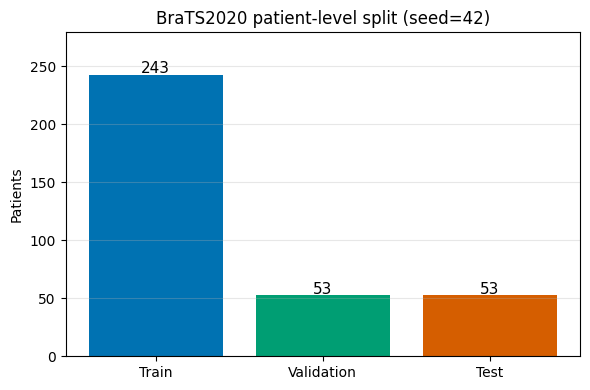

Saved /content/drive/MyDrive/Optimizing VITs/code_v2/outputs/figures/methodology/fig_brats_split.png


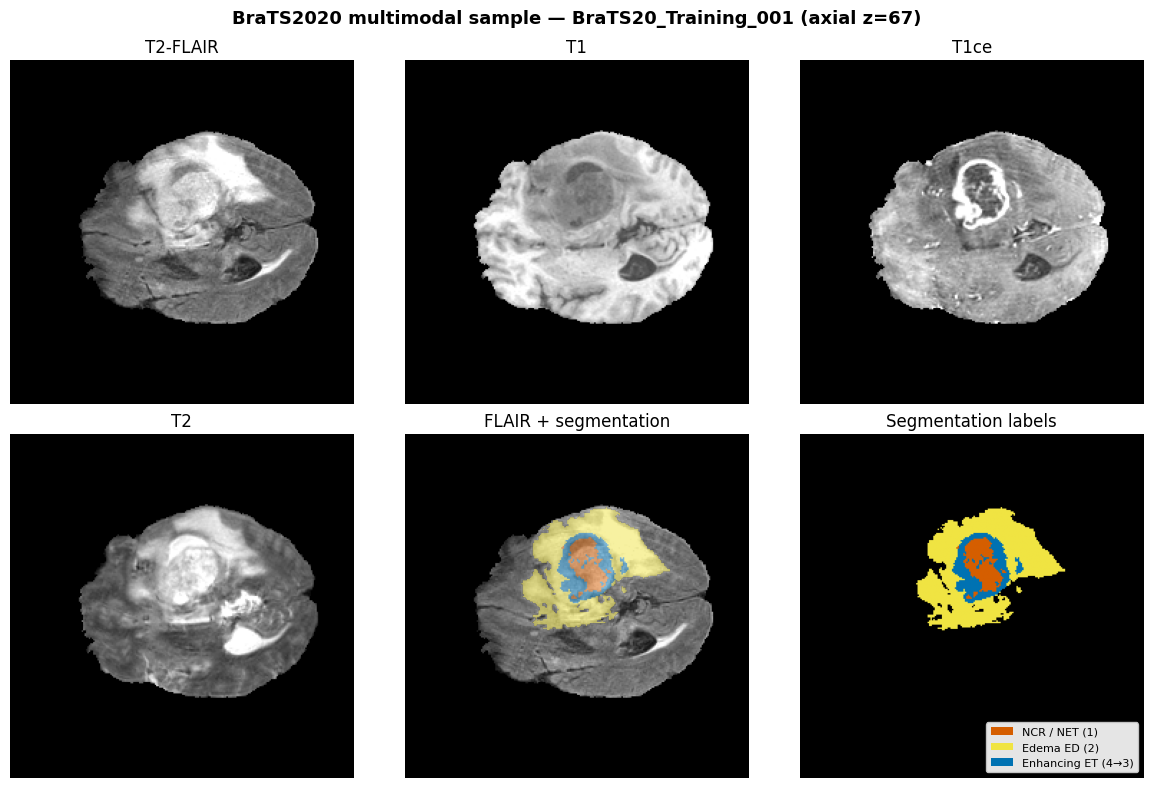

Saved /content/drive/MyDrive/Optimizing VITs/code_v2/outputs/figures/methodology/fig_brats_modalities.png


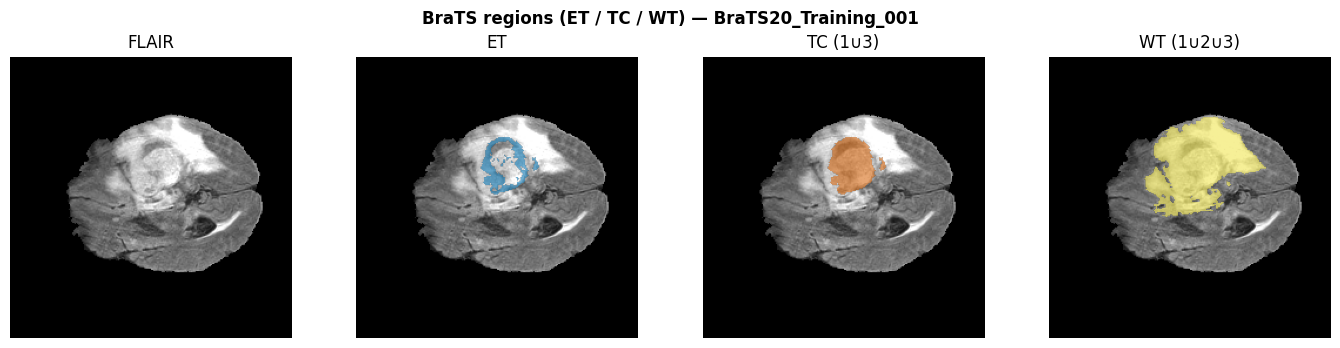

Saved /content/drive/MyDrive/Optimizing VITs/code_v2/outputs/figures/methodology/fig_brats_regions_et_tc_wt.png


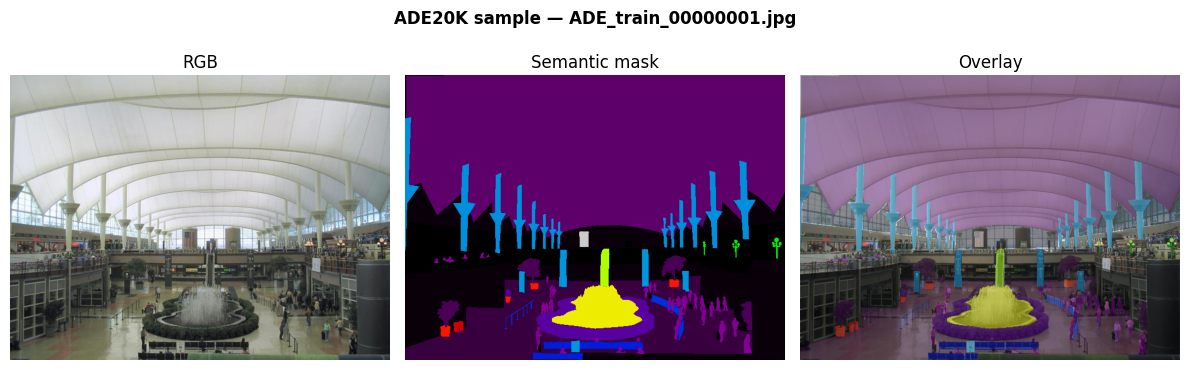

Saved /content/drive/MyDrive/Optimizing VITs/code_v2/outputs/figures/methodology/fig_ade20k_sample.png
All figures in: /content/drive/MyDrive/Optimizing VITs/code_v2/outputs/figures/methodology


In [ ]:
# @title Methodology dataset figures (BraTS2020 + ADE20K)
#
# Dataset citations (cite in methodology / references):
#   BraTS2020: Menze et al. (2015), IEEE TMI; Bakas et al. (2017), Nature Sci. Data
#   ADE20K:    Zhou et al. (2017/2019), CVPR / IJCV
#
# NOTE: normalization in this script (_norm) is per-slice and used ONLY for
# display. Training-time preprocessing normalizes per-volume and lives in
# preprocessing.py — nothing here affects that pipeline.

import os
import json
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from PIL import Image
from sklearn.model_selection import train_test_split

PROJECT_PATH = "/content/drive/MyDrive/Optimizing VITs/code_v2"
# BRATS_PATH = f"{PROJECT_PATH}/data/raw/BraTS2020"
# ADE_PATH = f"{PROJECT_PATH}/data/raw/ADE20K"
FIG_DIR = f"{PROJECT_PATH}/outputs/figures/methodology"
SPLITS_PATH = f"{PROJECT_PATH}/outputs/splits/brats_patient_split.json"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(os.path.dirname(SPLITS_PATH), exist_ok=True)

# Colorblind-safe palette (Okabe–Ito derived) — avoids red/green confusion
BRATS_CMAP = ListedColormap(["#000000", "#D55E00", "#F0E442", "#0072B2"])
BRATS_LEGEND = [
    Patch(facecolor="#D55E00", label="NCR / NET (1)"),
    Patch(facecolor="#F0E442", label="Edema ED (2)"),
    Patch(facecolor="#0072B2", label="Enhancing ET (4→3)"),
]

def _norm(x):
    """Percentile-clip normalization for DISPLAY only (not the training pipeline)."""
    x = x.astype(np.float32)
    mn, mx = np.percentile(x, (1, 99))
    x = np.clip(x, mn, mx)
    return (x - x.min()) / (x.max() - x.min() + 1e-8)

def _load_mod(pdir, pid, name):
    for ext in (".nii", ".nii.gz"):
        p = os.path.join(pdir, f"{pid}_{name}{ext}")
        if os.path.isfile(p):
            return nib.load(p).get_fdata()
    raise FileNotFoundError(f"Modality '{name}' not found for patient {pid} in {pdir}")

def _seg_vis(seg):
    """Remap raw BraTS labels {0,1,2,4} -> {0,1,2,3} for display.
    Standard BraTS2020 raw masks only contain {0,1,2,4}; the seg==3 branch
    is defensive only, in case an already-remapped mask is passed in."""
    v = np.zeros_like(seg, dtype=np.uint8)
    v[seg == 1] = 1
    v[seg == 2] = 2
    v[seg == 4] = 3
    v[seg == 3] = 3  # defensive: no-op on raw BraTS2020 data
    return v

def patient_split(train_root, seed=42, save_path=None):
    pts = sorted(
        d for d in os.listdir(train_root)
        if d.startswith("BraTS20_Training_") and os.path.isdir(os.path.join(train_root, d))
    )
    tv, te = train_test_split(pts, test_size=0.15, random_state=seed)
    tr, va = train_test_split(tv, test_size=0.15 / 0.85, random_state=seed)
    tr, va, te = sorted(tr), sorted(va), sorted(te)
    if save_path:
        with open(save_path, "w") as f:
            json.dump({"seed": seed, "train": tr, "val": va, "test": te}, f, indent=2)
        print("Saved patient split to", save_path)
    return tr, va, te

def fig_brats_modalities(train_root, patient_id, out_path, z=None):
    """4 modalities + overlay + mask (one axial slice)."""
    pdir = os.path.join(train_root, patient_id)
    mods = {m: _load_mod(pdir, patient_id, m) for m in ("flair", "t1", "t1ce", "t2")}
    seg = _load_mod(pdir, patient_id, "seg").astype(np.uint8)
    if z is None:
        counts = [(seg[:, :, i] > 0).sum() for i in range(seg.shape[2])]
        z = int(np.argmax(counts)) if max(counts) > 0 else seg.shape[2] // 2
    sv = _seg_vis(seg[:, :, z])

    fig, axes = plt.subplots(2, 3, figsize=(12, 8))
    fig.suptitle(f"BraTS2020 multimodal sample — {patient_id} (axial z={z})", fontsize=13, fontweight="bold")

    order = [("flair", "T2-FLAIR"), ("t1", "T1"), ("t1ce", "T1ce"), ("t2", "T2")]
    for ax, (k, title) in zip(axes.ravel()[:4], order):
        ax.imshow(_norm(mods[k][:, :, z]), cmap="gray")
        ax.set_title(title)
        ax.axis("off")

    fl = _norm(mods["flair"][:, :, z])
    axes[1, 1].imshow(fl, cmap="gray")
    axes[1, 1].imshow(np.ma.masked_where(sv == 0, sv), cmap=BRATS_CMAP, alpha=0.5, vmin=0, vmax=3)
    axes[1, 1].set_title("FLAIR + segmentation")
    axes[1, 1].axis("off")

    axes[1, 2].imshow(sv, cmap=BRATS_CMAP, vmin=0, vmax=3)
    axes[1, 2].set_title("Segmentation labels")
    axes[1, 2].axis("off")
    axes[1, 2].legend(handles=BRATS_LEGEND, loc="lower right", fontsize=8, framealpha=0.9)

    fig.tight_layout()
    fig.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print("Saved", out_path)

def matplotlib_color(hex_color):
    h = hex_color.lstrip("#")
    return tuple(int(h[i:i+2], 16) / 255 for i in (0, 2, 4))

def fig_brats_regions(train_root, patient_id, out_path, z=None):
    """ET / TC / WT binary maps (methodology evaluation regions)."""
    pdir = os.path.join(train_root, patient_id)
    flair = _load_mod(pdir, patient_id, "flair")
    seg = _load_mod(pdir, patient_id, "seg").astype(np.uint8)
    if z is None:
        counts = [(seg[:, :, i] > 0).sum() for i in range(seg.shape[2])]
        z = int(np.argmax(counts)) if max(counts) > 0 else seg.shape[2] // 2
    s = seg[:, :, z]
    s = np.where(s == 4, 3, s)
    fl = _norm(flair[:, :, z])
    et, tc, wt = (s == 3), np.isin(s, [1, 3]), np.isin(s, [1, 2, 3])

    fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
    fig.suptitle(f"BraTS regions (ET / TC / WT) — {patient_id}", fontsize=12, fontweight="bold")
    axes[0].imshow(fl, cmap="gray"); axes[0].set_title("FLAIR")
    for ax, m, t, c in zip(
        axes[1:], [et, tc, wt], ["ET", "TC (1∪3)", "WT (1∪2∪3)"],
        ["#0072B2", "#D55E00", "#F0E442"]
    ):
        ax.imshow(fl, cmap="gray")
        overlay = np.zeros((*m.shape, 4))
        overlay[m, :3] = matplotlib_color(c)
        overlay[m, 3] = 0.55
        ax.imshow(overlay)
        ax.set_title(t)
    for ax in axes:
        ax.axis("off")
    fig.tight_layout()
    fig.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print("Saved", out_path)

def fig_split_summary(n_train, n_val, n_test, out_path):
    fig, ax = plt.subplots(figsize=(6, 4))
    labels = ["Train", "Validation", "Test"]
    vals = [n_train, n_val, n_test]
    bars = ax.bar(labels, vals, color=["#0072B2", "#009E73", "#D55E00"])
    ax.set_ylabel("Patients")
    ax.set_title("BraTS2020 patient-level split (seed=42)")
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 1, str(v), ha="center", fontsize=11)
    ax.set_ylim(0, max(vals) * 1.15)
    ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()
    fig.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print("Saved", out_path)

def fig_ade_sample(ade_root, out_path):
    root = os.path.join(ade_root, "ADEChallengeData2016", "ADEChallengeData2016")
    img_dir = os.path.join(root, "images", "training")
    ann_dir = os.path.join(root, "annotations", "training")
    if not os.path.isdir(img_dir):
        print("ADE path missing:", img_dir)
        return
    name = sorted(os.listdir(img_dir))[0]
    mask_name = name.replace(".jpg", ".png")
    img = np.array(Image.open(os.path.join(img_dir, name)).convert("RGB"))
    mask = np.array(Image.open(os.path.join(ann_dir, mask_name)))
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    fig.suptitle(f"ADE20K sample — {name}", fontsize=12, fontweight="bold")
    axes[0].imshow(img); axes[0].set_title("RGB")
    axes[1].imshow(mask, cmap="nipy_spectral"); axes[1].set_title("Semantic mask")
    axes[2].imshow(img)
    axes[2].imshow(np.ma.masked_where(mask == 0, mask), cmap="nipy_spectral", alpha=0.45)
    axes[2].set_title("Overlay")
    for ax in axes:
        ax.axis("off")
    fig.tight_layout()
    fig.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print("Saved", out_path)

# ----- run -----
train_root = os.path.join(BRATS_PATH, "BraTS2020_TrainingData", "MICCAI_BraTS2020_TrainingData")
tr, va, te = patient_split(train_root, seed=42, save_path=SPLITS_PATH)
print(f"Split patients → train {len(tr)} | val {len(va)} | test {len(te)}")

fig_split_summary(len(tr), len(va), len(te), os.path.join(FIG_DIR, "fig_brats_split.png"))
fig_brats_modalities(train_root, tr[0], os.path.join(FIG_DIR, "fig_brats_modalities.png"))
fig_brats_regions(train_root, tr[0], os.path.join(FIG_DIR, "fig_brats_regions_et_tc_wt.png"))
fig_ade_sample(ADE_PATH, os.path.join(FIG_DIR, "fig_ade20k_sample.png"))
print("All figures in:", FIG_DIR)

preprocessing dataset

In [ ]:
%%writefile "/content/drive/MyDrive/Optimizing VITs/code_v2/utils/preprocess.py"
"""
Offline preprocessing.

BraTS2020 -> one .npz per axial slice: image (224, 224, 4) float16, mask (224, 224) uint8.
    - patient-level split (70/15/15), stratified by tumour grade (HGG/LGG)
    - per-volume z-score normalisation over brain voxels, per modality
    - 240 -> 224 centre crop (reversed by zero-padding at evaluation, so metrics are on the native grid)
    - labels: 0 background, 1 NCR/NET, 2 ED, 3 ET (original label 4)
    - train keeps every slice containing brain; val/test keep all 155 slices for 3D reconstruction

ADE20K (ADEChallengeData2016) -> one .npz per image: image (H, W, 3) uint8, mask (H, W) uint8.
    - labels 1..150 -> 0..149, "other" (0) -> 255 (ignore)
    - train: aspect ratio kept, short side resized to 256 (random scale + 224 crop happen in the dataloader)
    - val: original resolution, so mIoU is computed at original resolution

Usage:
    python utils/preprocess.py --dataset brats  --out /content/brats_slices
    python utils/preprocess.py --dataset ade20k --out /content/ade_npz
Pass --raw to use an existing extracted copy instead of downloading via kagglehub.
"""
import argparse
import glob
import json
import os
from concurrent.futures import ProcessPoolExecutor, as_completed

import nibabel as nib
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

MODALITIES = ["flair", "t1", "t1ce", "t2"]
BRATS_LABEL_MAP = {1: 1, 2: 2, 4: 3}  # NCR/NET, ED, ET
BRATS_CROP = (8, 232)                 # 240 -> 224 centre crop on both in-plane axes
ADE_NUM_CLASSES = 150
ADE_IGNORE_INDEX = 255
ADE_TRAIN_SHORT_SIDE = 256


def find_dir(root, name):
    """Locate a directory called `name` anywhere under `root` (Kaggle archives nest differently)."""
    if os.path.basename(os.path.normpath(root)) == name:
        return root
    for dirpath, dirnames, _ in os.walk(root):
        if name in dirnames:
            return os.path.join(dirpath, name)
    raise FileNotFoundError(f"'{name}' not found under {root}")


# --------------------------------------------------------------------------- #
# BraTS2020
# --------------------------------------------------------------------------- #

def load_nii(patient_dir, pid, suffix):
    for ext in (".nii", ".nii.gz"):
        p = os.path.join(patient_dir, f"{pid}_{suffix}{ext}")
        if os.path.exists(p):
            return nib.load(p).get_fdata()
    if suffix == "seg":  # BraTS20_Training_355 ships a misnamed segmentation file
        for f in os.listdir(patient_dir):
            if "seg" in f.lower() and f.endswith((".nii", ".nii.gz")):
                return nib.load(os.path.join(patient_dir, f)).get_fdata()
    raise FileNotFoundError(f"{pid}: missing {suffix}")


def patient_ok(d):
    pid = os.path.basename(d)
    for s in MODALITIES:
        if not any(os.path.exists(os.path.join(d, f"{pid}_{s}{e}")) for e in (".nii", ".nii.gz")):
            return False
    return any("seg" in f.lower() and f.endswith((".nii", ".nii.gz")) for f in os.listdir(d))


def norm_volume(vol):
    """Per-volume z-score over brain voxels (> 0) after percentile clipping; background stays 0."""
    vol = vol.astype(np.float32)
    m = vol > 0
    if not m.any():
        return vol
    lo, hi = np.percentile(vol[m], (0.5, 99.5))
    vol = np.clip(vol, lo, hi)
    v = vol[m]  # statistics AFTER clipping
    vol = (vol - v.mean()) / max(float(v.std()), 1e-5)
    vol[~m] = 0.0
    return vol


def process_brats_patient(pid, pdir, out_dir, brain_slices_only):
    image = np.stack([norm_volume(load_nii(pdir, pid, m)) for m in MODALITIES], axis=-1)  # H, W, D, 4
    seg = np.rint(load_nii(pdir, pid, "seg")).astype(np.uint8)
    mask = np.zeros_like(seg)
    for src, dst in BRATS_LABEL_MAP.items():
        mask[seg == src] = dst

    lo, hi = BRATS_CROP
    lost = int((mask > 0).sum() - (mask[lo:hi, lo:hi] > 0).sum())
    image = image[lo:hi, lo:hi]
    mask = mask[lo:hi, lo:hi]
    brain = np.any(image != 0, axis=-1)  # H, W, D

    files = []
    for z in range(mask.shape[2]):
        if brain_slices_only and not brain[:, :, z].any():
            continue
        fname = f"{pid}_slice_{z:03d}.npz"
        np.savez_compressed(os.path.join(out_dir, fname),
                            image=image[:, :, z].astype(np.float16), mask=mask[:, :, z])
        files.append(fname)
    return pid, files, lost, int(mask.shape[2])


def split_patients(pids, grades, seed, train_ratio, val_ratio):
    test_ratio = 1.0 - train_ratio - val_ratio
    strat = [grades[p] for p in pids] if grades else None
    trainval, test = train_test_split(pids, test_size=test_ratio, random_state=seed, stratify=strat)
    strat = [grades[p] for p in trainval] if grades else None
    train, val = train_test_split(trainval, test_size=val_ratio / (train_ratio + val_ratio),
                                  random_state=seed, stratify=strat)
    return {"train": sorted(train), "val": sorted(val), "test": sorted(test)}


def preprocess_brats(raw_dir, out_dir, seed=42, train_ratio=0.70, val_ratio=0.15, workers=None, force=False):
    split_json = os.path.join(out_dir, "splits.json")
    if os.path.isfile(split_json) and not force:
        print(f"Cache found at {split_json}; skipping (use --force to rebuild).")
        return

    raw_dir = find_dir(raw_dir, "MICCAI_BraTS2020_TrainingData")
    pid_to_dir = {
        f: os.path.join(raw_dir, f) for f in sorted(os.listdir(raw_dir))
        if f.startswith("BraTS20_Training_") and os.path.isdir(os.path.join(raw_dir, f))
        and patient_ok(os.path.join(raw_dir, f))
    }
    pids = list(pid_to_dir)
    print(f"Patients found: {len(pids)}")
    assert len(pids) > 0, f"No BraTS patients under {raw_dir}"

    grades = None
    nm_path = os.path.join(raw_dir, "name_mapping.csv")
    if os.path.isfile(nm_path):
        nm = pd.read_csv(nm_path)
        grades = dict(zip(nm["BraTS_2020_subject_ID"], nm["Grade"]))
        missing = [p for p in pids if p not in grades]
        assert not missing, f"No grade for {missing[:5]}"
    else:
        print("WARNING: name_mapping.csv not found; split is NOT stratified by grade.")

    split_map = split_patients(pids, grades, seed, train_ratio, val_ratio)
    for k, v in split_map.items():
        g = f" (HGG {sum(grades[p] == 'HGG' for p in v)}, LGG {sum(grades[p] == 'LGG' for p in v)})" if grades else ""
        print(f"  {k}: {len(v)} patients{g}")

    slices = {k: [] for k in split_map}
    depth = {}
    lost_total = 0
    with ProcessPoolExecutor(max_workers=workers or os.cpu_count()) as ex:
        futures = {}
        for split, plist in split_map.items():
            sdir = os.path.join(out_dir, split)
            os.makedirs(sdir, exist_ok=True)
            for pid in plist:
                fut = ex.submit(process_brats_patient, pid, pid_to_dir[pid], sdir, split == "train")
                futures[fut] = split
        for fut in tqdm(as_completed(futures), total=len(futures), desc="BraTS"):
            split = futures[fut]
            pid, files, lost, d = fut.result()
            slices[split].extend(os.path.join(split, f) for f in files)
            depth[pid] = d
            if lost:
                lost_total += lost
                print(f"WARNING {pid}: {lost} tumour voxels outside the 224 crop")

    for k in slices:
        slices[k].sort()
    manifest = {
        **slices,  # top-level "train"/"val"/"test" slice lists
        "patients": split_map,
        "meta": {
            "seed": seed, "ratios": [train_ratio, val_ratio, 1 - train_ratio - val_ratio],
            "modalities": MODALITIES, "labels": {"0": "background", "1": "NCR/NET", "2": "ED", "3": "ET"},
            "crop": {"axis0": list(BRATS_CROP), "axis1": list(BRATS_CROP), "original_shape": [240, 240]},
            "depth": depth, "tumour_voxels_lost_to_crop": lost_total,
            "train_filter": "slices containing brain", "eval_filter": "none (all slices)",
        },
    }
    with open(split_json, "w") as f:
        json.dump(manifest, f, indent=2)
    print({k: len(v) for k, v in slices.items()}, "slices written. Done.")


# --------------------------------------------------------------------------- #
# ADE20K
# --------------------------------------------------------------------------- #

def process_ade_image(img_path, mask_path, out_path, short_side):
    img = Image.open(img_path).convert("RGB")
    mask = Image.open(mask_path)
    if short_side:
        w, h = img.size
        s = short_side / min(w, h)
        size = (max(1, round(w * s)), max(1, round(h * s)))
        img = img.resize(size, Image.Resampling.BILINEAR)
        mask = mask.resize(size, Image.Resampling.NEAREST)

    m = np.array(mask, dtype=np.int16)
    assert m.ndim == 2 and m.max() <= ADE_NUM_CLASSES, f"unexpected mask in {mask_path}"
    m -= 1
    m[m < 0] = ADE_IGNORE_INDEX
    np.savez_compressed(out_path, image=np.array(img, dtype=np.uint8), mask=m.astype(np.uint8))
    return os.path.basename(out_path)


def preprocess_ade20k(raw_dir, out_dir, workers=None, force=False):
    split_json = os.path.join(out_dir, "splits.json")
    if os.path.isfile(split_json) and not force:
        print(f"Cache found at {split_json}; skipping (use --force to rebuild).")
        return

    raw_dir = find_dir(raw_dir, "ADEChallengeData2016")
    manifest = {}
    with ProcessPoolExecutor(max_workers=workers or os.cpu_count()) as ex:
        for split, folder, short_side in (("train", "training", ADE_TRAIN_SHORT_SIDE), ("val", "validation", None)):
            img_dir = os.path.join(raw_dir, "images", folder)
            mask_dir = os.path.join(raw_dir, "annotations", folder)
            sdir = os.path.join(out_dir, split)
            os.makedirs(sdir, exist_ok=True)

            images = sorted(glob.glob(os.path.join(img_dir, "*.jpg")))
            assert images, f"No images in {img_dir}"
            futures = []
            for p in images:
                base = os.path.splitext(os.path.basename(p))[0]
                mp = os.path.join(mask_dir, f"{base}.png")
                if not os.path.exists(mp):
                    print(f"WARNING: no annotation for {base}")
                    continue
                futures.append(ex.submit(process_ade_image, p, mp, os.path.join(sdir, f"{base}.npz"), short_side))
            files = [f.result() for f in tqdm(as_completed(futures), total=len(futures), desc=f"ADE20K {split}")]
            manifest[split] = sorted(os.path.join(split, f) for f in files)
            print(f"  {split}: {len(files)} images")

    manifest["meta"] = {
        "num_classes": ADE_NUM_CLASSES, "ignore_index": ADE_IGNORE_INDEX,
        "train": f"short side {ADE_TRAIN_SHORT_SIDE}, aspect ratio kept",
        "val": "original resolution",
    }
    with open(split_json, "w") as f:
        json.dump(manifest, f, indent=2)
    print("ADE20K done.")


# --------------------------------------------------------------------------- #
# Entry point
# --------------------------------------------------------------------------- #

KAGGLE_IDS = {"brats": "awsaf49/brats20-dataset-training-validation", "ade20k": "awsaf49/ade20k-dataset"}


def main(argv=None):
    p = argparse.ArgumentParser(description="Offline preprocessing for BraTS2020 / ADE20K")
    p.add_argument("--dataset", required=True, choices=["brats", "ade20k"])
    p.add_argument("--raw", default=None, help="extracted dataset root (default: download via kagglehub)")
    p.add_argument("--out", default=None, help="output dir (default: /content/brats_slices or /content/ade_npz)")
    p.add_argument("--seed", type=int, default=42)
    p.add_argument("--workers", type=int, default=None)
    p.add_argument("--force", action="store_true")
    args = p.parse_args(argv)

    raw = args.raw
    if raw is None:
        import kagglehub
        raw = kagglehub.dataset_download(KAGGLE_IDS[args.dataset])

    if args.dataset == "brats":
        preprocess_brats(raw, args.out or "/content/brats_slices", seed=args.seed,
                         workers=args.workers, force=args.force)
    else:
        preprocess_ade20k(raw, args.out or "/content/ade_npz", workers=args.workers, force=args.force)


if __name__ == "__main__":
    main()


Overwriting /content/drive/MyDrive/Optimizing VITs/code_v2/utils/preprocess.py


In [ ]:
!python "/content/drive/MyDrive/Optimizing VITs/code_v2/utils/preprocess.py" --dataset brats


Using Colab cache for faster access to the 'brats20-dataset-training-validation' dataset.
Patients found: 369
  train: 257 patients (HGG 204, LGG 53)
  val: 56 patients (HGG 45, LGG 11)
  test: 56 patients (HGG 44, LGG 12)
BraTS:  84% 311/369 [02:17<00:22,  2.60it/s]WARNING BraTS20_Training_344: 18 tumour voxels outside the 224 crop
BraTS: 100% 369/369 [02:42<00:00,  2.28it/s]
{'train': 35472, 'val': 8680, 'test': 8680} slices written. Done.


In [ ]:
# @title Preprocess ADE20K
!python "/content/drive/MyDrive/Optimizing VITs/code_v2/utils/preprocess.py" \
  --dataset ade20k --out /content/ade_npz

Using Colab cache for faster access to the 'ade20k-dataset' dataset.
ADE20K train: 100% 20210/20210 [00:00<00:00, 30784.72it/s] 
  train: 20210 images
ADE20K val: 100% 2000/2000 [00:03<00:00, 532.26it/s]  
  val: 2000 images
ADE20K done.


In [ ]:
%%writefile "/content/drive/MyDrive/Optimizing VITs/code_v2/utils/dataloader.py"
"""
Datasets and loaders for the .npz files written by utils/preprocess.py.

Every loader yields (image, mask, name):
    image  float32 (B, C, H, W)   BraTS: per-volume z-scored, 4 ch | ADE20K: ImageNet-normalised RGB
    mask   int64   (B, H, W)      BraTS: 0..3 | ADE20K: 0..149, 255 = ignore
    name   list[str]              file stem, e.g. "BraTS20_Training_001_slice_077" (for 3D reconstruction)

Shapes:
    BraTS  train/val/test: 224 x 224 (centre-cropped in preprocessing)
    ADE20K train: random scale + 224 x 224 crop
    ADE20K val:   ORIGINAL resolution, batch size 1 -> use utils.inference.slide_inference
ADE20K has no labelled test split; its val split is the reported test set (no model selection on it).
"""
import json
import os
import random

import albumentations as A
import cv2
import numpy as np
import torch
from albumentations.pytorch import ToTensorV2
from torch.utils.data import DataLoader, Dataset

DATA_ROOTS = {
    "brats": ["/content/brats_slices",
              "/content/drive/MyDrive/Optimizing VITs/code_v2/data/processed/brats_slices"],
    "ade20k": ["/content/ade_npz",
               "/content/drive/MyDrive/Optimizing VITs/code_v2/data/processed/ade_npz"],
}
DATASET_ALIASES = {"brats": "brats", "brats2020": "brats", "ade20k": "ade20k", "ade": "ade20k"}

ADE20K_IGNORE_INDEX = 255
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)


def _resolve_root(candidates):
    for p in candidates:
        if os.path.isfile(os.path.join(p, "splits.json")):
            return p
    raise FileNotFoundError(f"No splits.json found in any of: {candidates}. Run utils/preprocess.py first.")


def _load_splits(root):
    with open(os.path.join(root, "splits.json")) as f:
        manifest = json.load(f)
    # Only slice/image lists; "patients" and "meta" are metadata.
    return {k: [os.path.join(root, p) for p in manifest[k]] for k in ("train", "val", "test") if k in manifest}


# albumentations 2.x uses fill/fill_mask; 1.x uses value/mask_value
def _with_fill(cls, fill, fill_mask, **kw):
    try:
        return cls(fill=fill, fill_mask=fill_mask, **kw)
    except TypeError:
        return cls(value=fill, mask_value=fill_mask, **kw)


def get_transform(dataset, is_train, img_size=224):
    if dataset == "brats":
        if not is_train:
            return A.Compose([ToTensorV2()])
        return A.Compose([
            A.HorizontalFlip(p=0.5),
            A.VerticalFlip(p=0.2),
            _with_fill(A.Rotate, 0, 0, limit=15, p=0.5, border_mode=cv2.BORDER_CONSTANT),
            ToTensorV2(),
        ])

    normalize = A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD, max_pixel_value=255.0)
    if not is_train:
        return A.Compose([normalize, ToTensorV2()])
    # mmseg-style: random scale 0.5-2.0 (aspect kept) on short-side-256 images, pad, random crop, flip, colour
    return A.Compose([
        A.RandomScale(scale_limit=(-0.5, 1.0), p=1.0),
        _with_fill(A.PadIfNeeded, 0, ADE20K_IGNORE_INDEX, min_height=img_size, min_width=img_size,
                   border_mode=cv2.BORDER_CONSTANT),
        A.RandomCrop(height=img_size, width=img_size),
        A.HorizontalFlip(p=0.5),
        A.ColorJitter(brightness=0.125, contrast=0.5, saturation=0.5, hue=0.05, p=0.5),
        normalize,
        ToTensorV2(),
    ])


class SegmentationNpzDataset(Dataset):
    def __init__(self, files, transform):
        self.files = list(files)
        self.transform = transform

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        path = self.files[idx]
        with np.load(path) as data:
            image = data["image"]  # H, W, C (float16 BraTS / uint8 ADE20K)
            mask = data["mask"]    # H, W uint8
        if image.dtype == np.float16:
            image = image.astype(np.float32)
        out = self.transform(image=image, mask=mask)
        name = os.path.splitext(os.path.basename(path))[0]
        return out["image"].float(), out["mask"].long(), name


def _worker_init(worker_id):
    seed = torch.initial_seed() % 2**32
    np.random.seed(seed)
    random.seed(seed)


def get_dataloaders(config):
    dataset = DATASET_ALIASES[str(config.DATA.DATASET).lower().strip()]
    bs = int(config.DATA.BATCH_SIZE)
    img_size = int(config.DATA.IMG_SIZE)

    nw_val = getattr(config.DATA, "NUM_WORKERS", 8)
    if nw_val == "auto":
        nw = min(os.cpu_count() or 4, 8)
    else:
        nw = int(nw_val)

    seed = int(getattr(config, "SEED", 42))

    root = _resolve_root(DATA_ROOTS[dataset])
    splits = _load_splits(root)
    pin = torch.cuda.is_available()
    common = dict(num_workers=nw, pin_memory=pin, persistent_workers=nw > 0, worker_init_fn=_worker_init)

    g = torch.Generator()
    g.manual_seed(seed)
    train_loader = DataLoader(
        SegmentationNpzDataset(splits["train"], get_transform(dataset, True, img_size)),
        batch_size=bs, shuffle=True, drop_last=True, generator=g, **common)

    # ADE20K eval images keep their original (variable) size -> batch size 1
    eval_bs = bs if dataset == "brats" else 1
    eval_tf = get_transform(dataset, False, img_size)
    val_loader = DataLoader(SegmentationNpzDataset(splits["val"], eval_tf),
                            batch_size=eval_bs, shuffle=False, **common)
    test_loader = None
    if splits.get("test"):
        test_loader = DataLoader(SegmentationNpzDataset(splits["test"], eval_tf),
                                 batch_size=eval_bs, shuffle=False, **common)

    print(f"[Data] {dataset} from {root} | train {len(splits['train'])} | val {len(splits['val'])} | "
          f"test {len(splits.get('test', []))} | workers {nw}")
    return train_loader, val_loader, test_loader

Overwriting /content/drive/MyDrive/Optimizing VITs/code_v2/utils/dataloader.py


In [ ]:
%%writefile "/content/drive/MyDrive/Optimizing VITs/code_v2/models/factory.py"

"""
Model factory: builds every model from ImageNet-pretrained encoder weights only, sets the class
count, and adapts 4-channel BraTS input identically for every model (inflate_conv_in_channels
after the weights are loaded).

    from models.factory import model_factory, build_model
    net = model_factory(cfg)                         # config-driven (training/train.py)
    net = build_model("swin_unet", "brats")          # direct

Expected config attributes:
    config.MODEL.NAME      'swin_unet' | 'transunet' | 'segformer'
    config.DATA.DATASET    'brats' | 'ade20k'
    config.DATA.IMG_SIZE   e.g. 224
Optional:
    config.MODEL.PRETRAINED   (default True)
    config.MODEL.VARIANT      SegFormer variant (default 'b2')
    config.MODEL.SWIN_DEPTHS  Swin-UNet encoder depths (None = official lite [2, 2, 2, 2];
                              utils/config.py default = full Swin-T [2, 2, 6, 2])
"""
import os

import numpy as np

from models.utils import inflate_conv_in_channels

PROJECT_PATH = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))
PRETRAINED_DIR = os.path.join(PROJECT_PATH, "pretrained")
SWIN_CKPT = os.path.join(PRETRAINED_DIR, "swin_tiny_patch4_window7_224.pth")
R50_VIT_CKPT = os.path.join(PRETRAINED_DIR, "R50+ViT-B_16.npz")
SWIN_YAML = os.path.join(PROJECT_PATH, "models", "backbones", "swin", "swin_tiny_patch4_window7_224_lite.yaml")

# dataset -> (input channels, output classes)
DATASET_SPECS = {
    "brats": (4, 4),      # FLAIR/T1/T1ce/T2 -> background, NCR/NET, ED, ET
    "ade20k": (3, 150),   # RGB -> 150 classes (255 = ignore)
}


def build_swin_unet(in_channels, num_classes, img_size=224, pretrained=True, depths=None):
    """depths: encoder depths. None = official Swin-UNet 'lite' [2, 2, 2, 2];
    [2, 2, 6, 2] = the full Swin-T encoder (all pretrained Swin-T blocks used)."""
    from models.backbones.swin.swin_config import _C
    from models.backbones.swin.vision_transformer import SwinUnet

    cfg = _C.clone()
    cfg.defrost()
    cfg.merge_from_file(SWIN_YAML)
    cfg.DATA.IMG_SIZE = img_size
    cfg.MODEL.SWIN.IN_CHANS = 3  # load RGB weights first, inflate afterwards
    cfg.MODEL.PRETRAIN_CKPT = SWIN_CKPT
    if depths is not None:
        cfg.MODEL.SWIN.DEPTHS = list(depths)
    cfg.freeze()

    net = SwinUnet(cfg, img_size=img_size, num_classes=num_classes)
    if pretrained:
        net.load_from(cfg)
    pe = net.swin_unet.patch_embed
    pe.proj = inflate_conv_in_channels(pe.proj, in_channels)
    pe.in_chans = in_channels
    return net


def build_transunet(in_channels, num_classes, img_size=224, pretrained=True):
    from models.baselines.transunet.transunet import VisionTransformer
    from models.baselines.transunet.transunet_configs import get_r50_b16_config

    cfg = get_r50_b16_config()
    cfg.n_classes = num_classes
    cfg.n_skip = 3
    cfg.patches.grid = (img_size // 16, img_size // 16)  # as in official train.py

    net = VisionTransformer(cfg, img_size=img_size, num_classes=num_classes)
    if pretrained:
        net.load_from(weights=np.load(R50_VIT_CKPT))
    root = net.transformer.embeddings.hybrid_model.root
    root.conv = inflate_conv_in_channels(root.conv, in_channels)
    return net


def build_segformer(in_channels, num_classes, variant="b2", pretrained=True):
    from models.baselines.segformer import SegFormerBaseline
    return SegFormerBaseline(in_channels, num_classes, variant=variant, pretrained=pretrained)


BUILDERS = {
    "swin_unet": build_swin_unet,
    "transunet": build_transunet,
    "segformer": build_segformer,
}


def build_model(name, dataset, pretrained=True, **kwargs):
    in_channels, num_classes = DATASET_SPECS[dataset]
    return BUILDERS[name](in_channels, num_classes, pretrained=pretrained, **kwargs)


# --------------------------------------------------------------------------- #
# Config-driven entry point
# --------------------------------------------------------------------------- #

from models.utils import count_params  # noqa: E402

MODEL_ALIASES = {
    "swin_unet": "swin_unet", "swin": "swin_unet", "swin_tiny_patch4_window7_224": "swin_unet",
    "transunet": "transunet", "trans": "transunet",
    "segformer": "segformer",
}
DATASET_ALIASES = {"brats": "brats", "brats2020": "brats", "ade20k": "ade20k", "ade": "ade20k"}


def model_factory(config):
    name = MODEL_ALIASES[str(config.MODEL.NAME).lower().strip()]
    dataset = DATASET_ALIASES[str(config.DATA.DATASET).lower().strip()]
    pretrained = bool(getattr(config.MODEL, "PRETRAINED", True))

    if name == "segformer":
        kwargs = {"variant": str(getattr(config.MODEL, "VARIANT", "b2"))}
    else:
        kwargs = {"img_size": int(config.DATA.IMG_SIZE)}
        if name == "swin_unet":
            kwargs["depths"] = getattr(config.MODEL, "SWIN_DEPTHS", None)

    model = build_model(name, dataset, pretrained=pretrained, **kwargs)
    in_ch, n_cls = DATASET_SPECS[dataset]
    print(f"[Model Factory] {name} | {dataset} | {in_ch} ch -> {n_cls} classes | "
          f"{count_params(model):.1f}M params | pretrained={pretrained}")
    return model



Overwriting /content/drive/MyDrive/Optimizing VITs/code_v2/models/factory.py


In [ ]:
%%writefile "/content/drive/MyDrive/Optimizing VITs/code_v2/utils/config.py"
"""
Experiment configuration. One unified training recipe for every model (stated in the paper),
with per-dataset defaults. Build with get_config(); override any field via keyword paths:

    cfg = get_config("swin_unet", "brats")
    cfg = get_config("swin_unet", "brats", **{"PRUNING.ENABLED": True, "PRUNING.KEEP_RATIO": 0.75})
"""
import copy
import os


class SubConfig:
    def __init__(self, **kwargs):
        for k, v in kwargs.items():
            setattr(self, k, v)

    def to_dict(self):
        return {k: v.to_dict() if isinstance(v, SubConfig) else v for k, v in vars(self).items()}

    def __repr__(self):
        return repr(self.to_dict())


# Per-dataset defaults (everything else is shared across datasets and models)
DATASET_DEFAULTS = {
    "brats": dict(EPOCHS=30, DICE_WEIGHT=1.0, SELECT_ON="val_mean_dice"),
    # ADE20K: CE only (standard); val is the reported test set, so the LAST checkpoint is used
    "ade20k": dict(EPOCHS=40, DICE_WEIGHT=0.0, SELECT_ON="last", EVAL_EVERY=10),
}


class ThesisConfig(SubConfig):
    def __init__(self):
        self.SEED = 42

        self.DATA = SubConfig(
            DATASET="brats",          # 'brats' | 'ade20k'
            BATCH_SIZE=24,            # Swin-UNet's official batch size; same for all models
            IMG_SIZE=224,
            NUM_WORKERS="auto",       # one loader process per CPU core (max 8); T4 runtime = 2, A100 = 8
            IGNORE_INDEX=255,         # ADE20K "other"; BraTS has no ignore label
        )

        self.MODEL = SubConfig(
            NAME="swin_unet",         # 'swin_unet' | 'transunet' | 'segformer'
            VARIANT="b2",             # SegFormer only; B2 (27.5M) is size-matched to Swin-UNet-T (27.2M)
            SWIN_DEPTHS=[2, 2, 6, 2], # Swin-UNet encoder: full Swin-T. Official Swin-UNet 'lite' = [2, 2, 2, 2]
            PRETRAINED=True,          # ImageNet encoder weights from <project>/pretrained (models/factory.py)
        )

        # H1: Residual depthwise-separable adapter replacing Swin's patch embedding
        self.ADAPTER = SubConfig(
            ENABLED=False,
            TYPE="res_dw",
        )

        # H2: spatially compatible token reduction (SATP)
        self.PRUNING = SubConfig(
            ENABLED=False,
            METHOD="satp",
            KEEP_RATIO=1.0,           # r in the paper = fraction of tokens KEPT (Table 2: 1.00 / 0.75 / 0.50)
            TARGET_STAGES=[1, 2],     # encoder stages (0-based); stage 3 (7x7 = 1 window) gains little
            PRUNE_DECODER=False,      # also prune the mirrored decoder stages
            TOKEN_LOSS_WEIGHT=0.1,    # lambda_2 for L_token; tune on BraTS val
        )

        # H3: inference precision (applied after training; does not change training)
        self.QUANTIZATION = SubConfig(
            PRECISION="fp32",         # 'fp32' | 'fp16' | 'int8'
            MODE="ptq",               # 'ptq' | 'qat'
            BACKEND="tensorrt",
            CALIB_BATCHES=32,         # INT8 calibration batches drawn from the TRAIN split
            FP16_HEAD=True,           # keep the segmentation head at FP16 in INT8 mode (mixed precision)
        )

        self.TRAIN = SubConfig(
            EPOCHS=30,
            OPTIMIZER="adamw",
            LR=1e-4,
            WEIGHT_DECAY=1e-2,
            WARMUP_EPOCHS=1,          # linear warm-up, then poly decay (power 0.9) to 0
            POLY_POWER=0.9,
            GRAD_CLIP=1.0,
            AMP_DTYPE="bf16",         # A100: bf16 autocast, no GradScaler needed
            CE_WEIGHT=1.0,
            DICE_WEIGHT=1.0,          # lambda_1
            SELECT_ON="val_mean_dice",
            EVAL_EVERY=1,             # epochs
            OUTPUT_DIR="/content/drive/MyDrive/Optimizing VITs/code_v2/experiments",
        )

    @property
    def RUN_NAME(self):
        name = self.MODEL.NAME
        if name == "segformer":
            name += f"-{self.MODEL.VARIANT}"
        elif name == "swin_unet" and list(self.MODEL.SWIN_DEPTHS) != [2, 2, 2, 2]:
            name += "-d" + "".join(str(d) for d in self.MODEL.SWIN_DEPTHS)  # e.g. swin_unet-d2262
        parts = [name,
                 self.DATA.DATASET]
        if self.ADAPTER.ENABLED:
            parts.append("h1")
        if self.PRUNING.ENABLED:
            parts.append(f"h2r{self.PRUNING.KEEP_RATIO:.2f}")
        parts.append(f"s{self.SEED}")
        return "_".join(parts)

    @property
    def RUN_DIR(self):
        return os.path.join(self.TRAIN.OUTPUT_DIR, self.RUN_NAME)


def config_from_dict(d):
    """Rebuild a config saved with cfg.to_dict() (e.g. from a checkpoint)."""
    cfg = ThesisConfig()

    def fill(node, values):
        for k, v in values.items():
            if isinstance(v, dict) and isinstance(getattr(node, k, None), SubConfig):
                fill(getattr(node, k), v)
            else:
                setattr(node, k, copy.deepcopy(v))

    if "SWIN_DEPTHS" not in d.get("MODEL", {}):
        cfg.MODEL.SWIN_DEPTHS = [2, 2, 2, 2]  # checkpoints from before this option used the lite encoder
    fill(cfg, d)
    return cfg


def get_config(model="swin_unet", dataset="brats", **overrides):
    cfg = ThesisConfig()
    cfg.MODEL.NAME = model
    cfg.DATA.DATASET = dataset
    for k, v in DATASET_DEFAULTS[dataset].items():
        setattr(cfg.TRAIN, k, v)
    for path, value in overrides.items():
        *parents, leaf = path.split(".")
        node = cfg
        for p in parents:
            node = getattr(node, p)
        if not hasattr(node, leaf):
            raise KeyError(f"Unknown config field: {path}")
        setattr(node, leaf, copy.deepcopy(value))
    return cfg


Overwriting /content/drive/MyDrive/Optimizing VITs/code_v2/utils/config.py


In [ ]:
%%writefile "/content/drive/MyDrive/Optimizing VITs/code_v2/models/backbones/swin/pretrained.py"
"""
ImageNet Swin-T weights -> SwinTransformerSys (or a wrapper exposing .swin_unet).

Equivalent to the official SwinUnet.load_from() (encoder stage i is mirrored into decoder
stage n-1-i), plus a coverage check so a silently broken load raises instead of training
from random weights. Used for the H1 model, whose patch embedding is replaced by the
Res-DW-Adapter: every other tensor still loads; the adapter stays randomly initialised.
"""
import os

import torch


def _adapt_patch_embed(w, in_chans):
    """Same scheme as models.utils.inflate_conv_in_channels: copy RGB, fill extra
    channels with the RGB mean, rescale by 3/in_chans (in_chans=1 -> RGB sum)."""
    out = w.mean(1, keepdim=True).repeat(1, in_chans, 1, 1)
    k = min(3, in_chans)
    out[:, :k] = w[:, :k]
    return out * (3.0 / in_chans)


def load_swin_pretrained(model, ckpt_path, min_encoder_frac=0.9, verbose=True):
    if not ckpt_path or not os.path.isfile(ckpt_path):
        raise FileNotFoundError(f"Pretrained Swin checkpoint not found: {ckpt_path!r}")

    backbone = getattr(model, "swin_unet", model)
    ckpt = torch.load(ckpt_path, map_location="cpu", weights_only=False)
    src = ckpt["model"] if isinstance(ckpt, dict) and "model" in ckpt else ckpt
    target = backbone.state_dict()
    n_layers = backbone.num_layers

    enc = {k: v for k, v in src.items()
           if not k.startswith("head.") and "relative_position_index" not in k and "attn_mask" not in k}

    # Mirror encoder blocks into the decoder, as in the official Swin-Unet initialisation
    cand = dict(enc)
    for k, v in enc.items():
        if k.startswith("layers.") and ".blocks." in k:
            tokens = k.split(".")
            stage = int(tokens[1])
            rest = ".".join(tokens[2:])
            cand[f"layers_up.{n_layers - 1 - stage}.{rest}"] = v

    to_load, target_missing, shape_mismatch, adapted = {}, [], [], []
    for k, v in cand.items():
        if k not in target:
            target_missing.append(k)
            continue
        if target[k].shape == v.shape:
            to_load[k] = v
        elif (k == "patch_embed.proj.weight" and v.dim() == 4 and target[k].shape[1] <= 8
              and target[k].shape[0] == v.shape[0] and target[k].shape[2:] == v.shape[2:]):
            to_load[k] = _adapt_patch_embed(v, target[k].shape[1])
            adapted.append(k)
        else:
            shape_mismatch.append((k, tuple(v.shape), tuple(target[k].shape)))

    if any(s[0] == "patch_embed.proj.weight" for s in shape_mismatch):
        to_load.pop("patch_embed.proj.bias", None)

    backbone.load_state_dict(to_load, strict=False)

    enc_loadable = {k for k in enc if k in target}
    enc_loaded = sum(1 for k in enc_loadable if k in to_load)
    frac = enc_loaded / max(len(enc_loadable), 1)
    dec_loaded = sum(1 for k in to_load if k.startswith("layers_up."))

    if verbose:
        print(f"[pretrained] encoder tensors loaded {enc_loaded}/{len(enc_loadable)} loadable ({frac:.0%}) "
              f"| decoder tensors mirrored {dec_loaded} | adapted {adapted or 'none'}")
        if shape_mismatch:
            print(f"[pretrained] shape mismatches skipped: {shape_mismatch}")

    if frac < min_encoder_frac:
        raise RuntimeError(f"Pretrained load looks broken: only {frac:.0%} of loadable encoder tensors matched.")

    return {"encoder_frac": frac, "decoder_loaded": dec_loaded, "adapted": adapted,
            "shape_mismatch": shape_mismatch, "target_missing_count": len(target_missing)}

Overwriting /content/drive/MyDrive/Optimizing VITs/code_v2/models/backbones/swin/pretrained.py


In [ ]:
%%writefile "/content/drive/MyDrive/Optimizing VITs/code_v2/training/trainer.py"
"""
Trainer: one recipe for every model (AdamW, linear warm-up + poly decay per iteration,
bf16 autocast, grad clipping). Evaluation uses the paper-standard metrics in
evaluation/metrics.py.

H2 contract: a token-reduction model that wants L_token sets `model.token_loss` (a scalar
tensor) during forward; it is added with weight PRUNING.TOKEN_LOSS_WEIGHT.
"""
import contextlib
import logging
import os
import time
import sys
import numpy as np
import random

import torch
from torch.optim.lr_scheduler import LambdaLR
from tqdm.auto import tqdm

from evaluation.metrics import BratsVolumeAccumulator, MIoUAccumulator
from models.factory import DATASET_SPECS
from utils.losses import SegLoss
from utils.inference import slide_inference

AMP_DTYPES = {"bf16": torch.bfloat16, "fp16": torch.float16, "fp32": None}
NO_DECAY_KEYS = ("relative_position_bias_table", "absolute_pos_embed", "position_embeddings", "pos_embed")


def param_groups(model, weight_decay):
    """No weight decay on norms, biases and position tables (standard for Swin/ViT/SegFormer)."""
    decay, no_decay = [], []
    for name, p in model.named_parameters():
        if not p.requires_grad:
            continue
        (no_decay if p.ndim <= 1 or any(k in name for k in NO_DECAY_KEYS) else decay).append(p)
    return [{"params": decay, "weight_decay": weight_decay}, {"params": no_decay, "weight_decay": 0.0}]


def progress_bar(iterable, desc, total, leave):
    """Percentage bar on stdout (same stream as the log, so lines stay in order in Colab)."""
    return tqdm(iterable, desc=desc, total=total, leave=leave, file=sys.stdout, mininterval=1.0, ncols=110,
                bar_format="{desc} {percentage:3.0f}%|{bar:25}| {n_fmt}/{total_fmt} "
                           "[{elapsed}<{remaining}, {rate_fmt}{postfix}]")


def format_summary(dataset, s):
    """One-line, human-readable metric summary."""
    if dataset == "brats":
        txt = (f"Dice WT {s['dice_WT']:.3f} TC {s['dice_TC']:.3f} ET {s['dice_ET']:.3f} "
               f"mean {s['mean_dice']:.3f}")
        if "mean_hd95" in s:
            txt += f" | HD95 mean {s['mean_hd95']:.1f} mm"
        return txt
    return f"mIoU {s['mIoU']:.4f} mAcc {s['mAcc']:.4f} aAcc {s['aAcc']:.4f}"


@torch.no_grad()
def evaluate_model(model, loader, dataset, num_classes, ignore_index, device, autocast_ctx=None,
                   with_hd95=False, limit_batches=None, desc="eval"):
    """Paper-standard evaluation for any callable model (PyTorch module or TensorRT engine wrapper)."""
    if hasattr(model, "eval"):
        model.eval()
    if hasattr(model, "set_token_targets"):
        model.set_token_targets(None)
    if dataset == "brats":
        acc = BratsVolumeAccumulator(with_hd95=with_hd95)
    else:
        acc = MIoUAccumulator(num_classes, ignore_index, device=device)

    total = min(len(loader), limit_batches or len(loader))
    for i, (x, y, names) in enumerate(progress_bar(loader, desc, total, leave=False)):
        if limit_batches and i >= limit_batches:
            break
        x = x.to(device, non_blocking=True)
        with (autocast_ctx() if autocast_ctx else contextlib.nullcontext()):
            if dataset == "brats":
                logits = model(x)
            else:  # original resolution, batch size 1
                logits = slide_inference(model, x, num_classes)
        pred = logits.argmax(1)
        if dataset == "brats":
            acc.update(pred.to(torch.uint8).cpu().numpy(), y.to(torch.uint8).numpy(), names)
        else:
            acc.update(pred, y.to(device))
    return acc.compute()


class Trainer:
    def __init__(self, model, cfg, device, run_dir, logger=None):
        self.model = model.to(device)
        self.cfg = cfg
        self.device = device
        self.run_dir = run_dir
        self.log = logger or logging.getLogger("train")
        self.dataset = cfg.DATA.DATASET
        self.num_classes = DATASET_SPECS[self.dataset][1]
        t = cfg.TRAIN

        self.criterion = SegLoss(t.CE_WEIGHT, t.DICE_WEIGHT, ignore_index=cfg.DATA.IGNORE_INDEX)
        self.token_loss_weight = cfg.PRUNING.TOKEN_LOSS_WEIGHT if cfg.PRUNING.ENABLED else 0.0
        self.optimizer = torch.optim.AdamW(param_groups(model, t.WEIGHT_DECAY), lr=t.LR)
        self.amp_dtype = AMP_DTYPES[t.AMP_DTYPE] if device.type == "cuda" else None
        if self.amp_dtype is torch.bfloat16 and torch.cuda.get_device_capability(device)[0] < 8:
            self.amp_dtype = torch.float16  # pre-Ampere GPUs (e.g. T4) have no native bf16
            self.log.info("GPU has no native bf16 -> using fp16 autocast with GradScaler")
        self.scaler = torch.amp.GradScaler("cuda") if self.amp_dtype is torch.float16 else None
        os.makedirs(run_dir, exist_ok=True)

    def _autocast(self):
        return torch.autocast(device_type=self.device.type, dtype=self.amp_dtype or torch.float32,
                              enabled=self.amp_dtype is not None)

    def _build_scheduler(self, steps_per_epoch):
        t = self.cfg.TRAIN
        total = max(1, t.EPOCHS * steps_per_epoch)
        warmup = max(1, int(t.WARMUP_EPOCHS * steps_per_epoch))

        def lr_lambda(step):
            if step < warmup:
                return (step + 1) / warmup
            return max(0.0, 1.0 - (step - warmup) / max(1, total - warmup)) ** t.POLY_POWER

        return LambdaLR(self.optimizer, lr_lambda)

    def train_one_epoch(self, loader, scheduler, epoch, limit_batches=None):
        self.model.train()
        clip = self.cfg.TRAIN.GRAD_CLIP
        total, n = 0.0, 0
        total_steps = min(len(loader), limit_batches or len(loader))
        pbar = progress_bar(loader, f"Epoch {epoch + 1}/{self.cfg.TRAIN.EPOCHS} train", total_steps, leave=True)
        for i, (x, y, _) in enumerate(pbar):
            if limit_batches and i >= limit_batches:
                break
            x = x.to(self.device, non_blocking=True)
            y = y.to(self.device, non_blocking=True)
            self.optimizer.zero_grad(set_to_none=True)
            if hasattr(self.model, "set_token_targets"):  # H2: boundary targets for L_token
                self.model.set_token_targets(y if self.token_loss_weight else None)
            with self._autocast():
                logits = self.model(x)
                loss = self.criterion(logits, y)
                if self.token_loss_weight and getattr(self.model, "token_loss", None) is not None:
                    loss = loss + self.token_loss_weight * self.model.token_loss

            if self.scaler:
                self.scaler.scale(loss).backward()
                self.scaler.unscale_(self.optimizer)
                torch.nn.utils.clip_grad_norm_(self.model.parameters(), clip)
                self.scaler.step(self.optimizer)
                self.scaler.update()
            else:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(self.model.parameters(), clip)
                self.optimizer.step()
            scheduler.step()

            if not torch.isfinite(loss):
                raise FloatingPointError(f"Non-finite loss at epoch {epoch + 1}, step {i}")
            total += loss.item()
            n += 1
            if i % 10 == 0:
                pbar.set_postfix_str(f"loss {total / n:.4f} | lr {scheduler.get_last_lr()[0]:.2e}", refresh=False)
        pbar.close()
        return total / max(n, 1)

    @torch.no_grad()
    def evaluate(self, loader, with_hd95=False, limit_batches=None, desc="eval"):
        return evaluate_model(self.model, loader, self.dataset, self.num_classes, self.cfg.DATA.IGNORE_INDEX,
                              self.device, self._autocast, with_hd95, limit_batches, desc)

    def _save(self, name, epoch, metrics, extra=None):
        path = os.path.join(self.run_dir, name)
        tmp = path + ".tmp"  # write-then-rename: a crash mid-save never corrupts the previous checkpoint
        torch.save({"model": self.model.state_dict(), "epoch": epoch, "metrics": metrics,
                    "config": self.cfg.to_dict(), **(extra or {})}, tmp)
        os.replace(tmp, path)
        return path

    def _resume_state(self, scheduler, train_loader, best, history, elapsed):
        """Everything needed to continue training exactly where it stopped (stored in last.pth)."""
        gen = getattr(train_loader, "generator", None)
        return {"optimizer": self.optimizer.state_dict(), "scheduler": scheduler.state_dict(),
                "scaler": self.scaler.state_dict() if self.scaler else None,
                "best": best, "history": history, "elapsed_s": elapsed,
                "rng": {"torch": torch.get_rng_state(), "numpy": np.random.get_state(), "python": random.getstate(),
                        "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
                        "loader": gen.get_state() if gen is not None else None}}

    def fit(self, train_loader, val_loader, limit_batches=None, on_epoch_end=None, resume=None):
        """resume: a last.pth dict from an interrupted run of the SAME config (see training/train.py)."""
        t = self.cfg.TRAIN
        steps = min(len(train_loader), limit_batches or len(train_loader))
        scheduler = self._build_scheduler(steps)
        select_on = t.SELECT_ON  # 'val_mean_dice' (BraTS) or 'last' (ADE20K: val is the test set)
        best, history, start_epoch, elapsed0 = -1.0, [], 0, 0.0

        if resume is not None:
            self.model.load_state_dict(resume["model"])
            self.optimizer.load_state_dict(resume["optimizer"])
            scheduler.load_state_dict(resume["scheduler"])
            if self.scaler and resume.get("scaler"):
                self.scaler.load_state_dict(resume["scaler"])
            best, history, start_epoch = resume["best"], resume["history"], resume["epoch"]
            elapsed0 = resume.get("elapsed_s", 0.0)
            rng = resume["rng"]
            torch.set_rng_state(rng["torch"])
            np.random.set_state(rng["numpy"])
            random.setstate(rng["python"])
            if rng.get("cuda") is not None and torch.cuda.is_available():
                torch.cuda.set_rng_state_all(rng["cuda"])
            if rng.get("loader") is not None and getattr(train_loader, "generator", None) is not None:
                train_loader.generator.set_state(rng["loader"])
            self.log.info(f"Resumed after epoch {start_epoch}/{t.EPOCHS}"
                          + (f" | best val mean Dice so far {best:.4f}" if best >= 0 else ""))
        start = time.time()
        self.train_seconds = elapsed0

        for epoch in range(start_epoch, t.EPOCHS):
            t0 = time.time()
            train_loss = self.train_one_epoch(train_loader, scheduler, epoch, limit_batches)
            row = {"epoch": epoch + 1, "train_loss": train_loss, "lr": scheduler.get_last_lr()[0]}
            val_txt = "val skipped"

            if select_on != "last" or (epoch + 1) % t.EVAL_EVERY == 0 or epoch + 1 == t.EPOCHS:
                summary, _ = self.evaluate(val_loader, with_hd95=False, limit_batches=limit_batches,
                                           desc=f"Epoch {epoch + 1} [val]")
                row["val"] = summary
                val_txt = "val " + format_summary(self.dataset, summary)
                if select_on == "val_mean_dice" and summary["mean_dice"] > best:
                    best = summary["mean_dice"]
                    self._save("best.pth", epoch + 1, summary)
                    row["new_best"] = True

            row["epoch_min"] = (time.time() - t0) / 60
            row["eta_min"] = (time.time() - start) / (epoch + 1 - start_epoch) * (t.EPOCHS - epoch - 1) / 60
            history.append(row)
            self.train_seconds = elapsed0 + time.time() - start
            self._save("last.pth", epoch + 1, row,
                       extra=self._resume_state(scheduler, train_loader, best, history, self.train_seconds))
            self.log.info(f"Epoch {epoch + 1:>2}/{t.EPOCHS} | loss {train_loss:.4f} | {val_txt} | "
                          f"{row['epoch_min']:.1f} min | ETA {row['eta_min']:.0f} min"
                          + ("  * best" if row.get("new_best") else ""))
            if on_epoch_end:
                on_epoch_end(epoch + 1, row, best)
        return history



Overwriting /content/drive/MyDrive/Optimizing VITs/code_v2/training/trainer.py


In [ ]:
%%writefile "/content/drive/MyDrive/Optimizing VITs/code_v2/training/train.py"
"""
Train one configuration and write results.json (test metrics + params + GFLOPs + config).

    python training/train.py --model swin_unet --dataset brats
    python training/train.py --model segformer --dataset ade20k --seed 1
    python training/train.py --model swin_unet --dataset brats --limit-batches 5 --epochs 1   # smoke test
    python training/status.py                                                                # all runs at a glance

Each run folder holds: train.log, config.json, progress.json (updated every epoch),
best.pth / last.pth, results.json and per_case.json. Checkpoints are written to fast local disk
(/content/runs) and copied to Drive (cfg.TRAIN.OUTPUT_DIR); small files are copied every epoch.
Latency / throughput / FP16 / INT8 are measured separately by evaluation/benchmark.py.
"""
import argparse
import contextlib
import io
import json
import logging
import os
import random
import shutil
import sys
import time
import traceback
import warnings

PIPELINE_VERSION = "2026-10-26.4"  # printed in every run header: confirms Colab runs the current files

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*meshgrid.*")
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")

import numpy as np  # noqa: E402
import torch  # noqa: E402
from torch.utils.flop_counter import FlopCounterMode  # noqa: E402

PROJECT_PATH = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))
if PROJECT_PATH not in sys.path:
    sys.path.insert(0, PROJECT_PATH)

from models.factory import DATASET_SPECS  # noqa: E402
from models.factory import model_factory  # noqa: E402
from models.utils import count_params  # noqa: E402
from training.trainer import Trainer, format_summary  # noqa: E402
from utils.config import get_config  # noqa: E402
from utils.dataloader import get_dataloaders  # noqa: E402

MODEL_NAMES = {"swin_unet": "Swin-UNet", "transunet": "TransUNet (R50-ViT-B/16)", "segformer": "SegFormer"}
DATASET_NAMES = {"brats": "BraTS2020", "ade20k": "ADE20K"}
SMALL_FILES = ("train.log", "config.json", "progress.json", "results.json", "per_case.json")


def parse_args(argv=None):
    p = argparse.ArgumentParser()
    p.add_argument("--model", default="swin_unet", choices=["swin_unet", "transunet", "segformer"])
    p.add_argument("--dataset", default="brats", choices=["brats", "ade20k"])
    p.add_argument("--seed", type=int, default=42)
    p.add_argument("--epochs", type=int, default=None, help="default: per-dataset value in utils/config.py")
    p.add_argument("--batch-size", type=int, default=None)
    p.add_argument("--lr", type=float, default=None)
    p.add_argument("--workers", type=int, default=None)
    p.add_argument("--adapter", action="store_true", help="H1: Res-DW-Adapter")
    p.add_argument("--keep-ratio", type=float, default=None, help="H2: token keep ratio r (enables SATP if < 1)")
    p.add_argument("--limit-batches", type=int, default=None, help="smoke test: batches per train/eval pass")
    p.add_argument("--run-root", default="/content/runs", help="fast local disk for checkpoints")
    p.add_argument("--sync-every", type=int, default=1, help="copy checkpoints to Drive every N epochs")
    p.add_argument("--no-resume", action="store_true", help="discard an interrupted run and start from epoch 1")
    return p.parse_args(argv)


class _Formatter(logging.Formatter):
    def format(self, record):
        return f"{time.strftime('%H:%M:%S')} | {record.getMessage()}"


def setup_logger(run_dir):
    os.makedirs(run_dir, exist_ok=True)
    log = logging.getLogger("train")
    log.setLevel(logging.INFO)
    log.handlers.clear()
    log.propagate = False
    for h in (logging.StreamHandler(sys.stdout), logging.FileHandler(os.path.join(run_dir, "train.log"))):
        h.setFormatter(_Formatter())
        log.addHandler(h)
    return log


def quiet_libraries():
    try:
        import transformers
        transformers.logging.set_verbosity_error()
    except ImportError:
        pass
    try:
        from huggingface_hub.utils import logging as hf_logging
        hf_logging.set_verbosity_error()
    except ImportError:
        pass


@contextlib.contextmanager
def captured_stdout(log):
    """Hide the upstream repos' print() chatter while building models; show it only if building fails."""
    buf = io.StringIO()
    try:
        with contextlib.redirect_stdout(buf), contextlib.redirect_stderr(buf):
            yield
    except Exception:
        log.info("Model build output:\n" + buf.getvalue())
        raise


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True  # faster; runs are seeded but not bit-exact


def count_gflops(model, in_ch, img_size, device):
    """GFLOPs for one image at img_size, counting a multiply-add as 2 FLOPs.
    Many papers' 'GFLOPs' come from fvcore/mmcv, which count a multiply-add as 1 (i.e. MACs):
    those values are half of ours. gmacs = gflops / 2 is also stored for that comparison."""
    model.eval()
    x = torch.randn(1, in_ch, img_size, img_size, device=device)
    with FlopCounterMode(display=False) as fc, torch.no_grad():
        model(x)
    return fc.get_total_flops() / 1e9


def write_json(path, obj):
    tmp = path + ".tmp"
    with open(tmp, "w") as f:
        json.dump(obj, f, indent=2)
    os.replace(tmp, path)


def main(argv=None):
    args = parse_args(argv)
    overrides = {"SEED": args.seed}
    if args.epochs is not None:
        overrides["TRAIN.EPOCHS"] = args.epochs
    if args.batch_size is not None:
        overrides["DATA.BATCH_SIZE"] = args.batch_size
    if args.lr is not None:
        overrides["TRAIN.LR"] = args.lr
    if args.workers is not None:
        overrides["DATA.NUM_WORKERS"] = args.workers
    if args.adapter:
        overrides["ADAPTER.ENABLED"] = True
    if args.keep_ratio is not None and args.keep_ratio < 1.0:
        overrides.update({"PRUNING.ENABLED": True, "PRUNING.KEEP_RATIO": args.keep_ratio})
    cfg = get_config(args.model, args.dataset, **overrides)

    run_name = cfg.RUN_NAME + ("_smoke" if args.limit_batches else "")
    run_dir = os.path.join(args.run_root, run_name)
    drive_dir = os.path.join(cfg.TRAIN.OUTPUT_DIR, run_name)

    # ---- finished / resume / restart (decided before the log file is opened) ----
    if args.limit_batches and os.path.isfile(os.path.join(drive_dir, "results.json")):
        args.no_resume = True  # re-running a finished smoke test starts fresh
    if args.no_resume:
        shutil.rmtree(run_dir, ignore_errors=True)
        for f in ("last.pth", "best.pth", "results.json", "per_case.json", "progress.json", "train.log"):
            if os.path.isfile(os.path.join(drive_dir, f)):
                os.remove(os.path.join(drive_dir, f))
    elif os.path.isfile(os.path.join(drive_dir, "results.json")):
        print(f"{run_name} already finished ({drive_dir}/results.json). Use --no-resume to retrain.")
        with open(os.path.join(drive_dir, "results.json")) as f:
            return json.load(f)
    elif not os.path.isfile(os.path.join(run_dir, "last.pth")) and os.path.isfile(os.path.join(drive_dir, "last.pth")):
        shutil.copytree(drive_dir, run_dir, dirs_exist_ok=True)  # runtime was reset: continue from Drive copy

    resume = None
    last_path = os.path.join(run_dir, "last.pth")
    if not args.no_resume and os.path.isfile(last_path):
        ckpt = torch.load(last_path, map_location="cpu", weights_only=False)
        same = json.dumps(ckpt.get("config"), sort_keys=True) == json.dumps(cfg.to_dict(), sort_keys=True)
        if "optimizer" not in ckpt:
            print(f"{last_path} has no optimizer state (older pipeline) -> starting from epoch 1")
        elif not same:
            raise SystemExit(f"{run_name}: the interrupted run used a different config. "
                             f"Re-run with the same arguments, or add --no-resume to start over.")
        else:
            resume = ckpt

    log = setup_logger(run_dir)
    quiet_libraries()
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    seed_everything(cfg.SEED)
    write_json(os.path.join(run_dir, "config.json"), cfg.to_dict())

    progress = {"run": run_name, "state": "starting", "epoch": resume["epoch"] if resume else 0,
                "epochs": cfg.TRAIN.EPOCHS, "started": time.strftime("%Y-%m-%d %H:%M:%S"),
                "resumed": bool(resume), "pipeline_version": PIPELINE_VERSION}

    def save_progress(**kw):
        progress.update(kw, updated=time.strftime("%Y-%m-%d %H:%M:%S"))
        write_json(os.path.join(run_dir, "progress.json"), progress)

    def sync(full=False):
        try:
            if full:
                shutil.copytree(run_dir, drive_dir, dirs_exist_ok=True)
            else:
                os.makedirs(drive_dir, exist_ok=True)
                for f in SMALL_FILES:
                    if os.path.isfile(os.path.join(run_dir, f)):
                        shutil.copy2(os.path.join(run_dir, f), os.path.join(drive_dir, f))
        except OSError as e:  # Drive hiccups must not kill an overnight run
            log.info(f"Drive sync failed (will retry): {e}")

    try:
        save_progress(state="building")
        with captured_stdout(log):
            model = model_factory(cfg)
            if cfg.ADAPTER.ENABLED or cfg.PRUNING.ENABLED:
                from models.optimizer_engine import apply_thesis_optimizations
                model = apply_thesis_optimizations(model, cfg)
        train_loader, val_loader, test_loader = get_dataloaders(cfg)
        trainer = Trainer(model, cfg, device, run_dir, logger=log)

        t = cfg.TRAIN
        steps = min(len(train_loader), args.limit_batches or len(train_loader))
        h2 = f"on (r={cfg.PRUNING.KEEP_RATIO}, stages {cfg.PRUNING.TARGET_STAGES})" if cfg.PRUNING.ENABLED else "off"
        n_test = len(test_loader.dataset) if test_loader else 0
        bar = "=" * 78
        for line in [
            bar,
            f"RUN       {run_name}{'   [SMOKE TEST]' if args.limit_batches else ''}",
            f"Model     {MODEL_NAMES[args.model]}{' ' + cfg.MODEL.VARIANT.upper() if args.model == 'segformer' else ''}"
            f" | {count_params(model):.1f}M params | ImageNet-pretrained encoder",
            f"Variant   H1 adapter {'on' if cfg.ADAPTER.ENABLED else 'off'} | H2 SATP {h2}",
            f"Data      {DATASET_NAMES[args.dataset]} | train {len(train_loader.dataset):,} | "
            f"val {len(val_loader.dataset):,} | test {n_test:,}",
            f"Recipe    {t.EPOCHS} epochs x {steps:,} steps | batch {cfg.DATA.BATCH_SIZE} | AdamW lr {t.LR:g} "
            f"wd {t.WEIGHT_DECAY:g} | {t.AMP_DTYPE} | seed {cfg.SEED}",
            f"Select    {'best val mean Dice' if t.SELECT_ON == 'val_mean_dice' else 'last epoch (val = reported test set)'}",
            f"Device    {torch.cuda.get_device_name(0) if device.type == 'cuda' else 'cpu'} | "
            f"{os.cpu_count()} CPU cores, {train_loader.num_workers} loader workers | pipeline {PIPELINE_VERSION}",
            f"Output    {drive_dir}",
            bar,
        ]:
            log.info(line)

        save_progress(state="training")

        def on_epoch_end(epoch, row, best):
            save_progress(epoch=epoch, last=row, best_val=best if best >= 0 else None, eta_min=row["eta_min"])
            sync(full=(epoch % args.sync_every == 0))

        history = trainer.fit(train_loader, val_loader, limit_batches=args.limit_batches,
                              on_epoch_end=on_epoch_end, resume=resume)
        del resume
        train_hours = trainer.train_seconds / 3600  # includes time before an interruption

        # Final model: best on val mean Dice (BraTS) or last epoch (ADE20K, whose val split is the test set)
        save_progress(state="testing")
        ckpt_name = "best.pth" if t.SELECT_ON == "val_mean_dice" else "last.pth"
        ckpt = torch.load(os.path.join(run_dir, ckpt_name), map_location=device, weights_only=False)
        model.load_state_dict(ckpt["model"])
        eval_loader = test_loader if args.dataset == "brats" else val_loader
        summary, per_case = trainer.evaluate(eval_loader, with_hd95=(args.dataset == "brats"),
                                             limit_batches=args.limit_batches, desc="test")

        in_ch, _ = DATASET_SPECS[args.dataset]
        gflops = count_gflops(model, in_ch, cfg.DATA.IMG_SIZE, device)
        results = {
            "run": run_name, "model": args.model, "dataset": args.dataset, "seed": cfg.SEED,
            "checkpoint": ckpt_name, "checkpoint_epoch": ckpt["epoch"],
            "test": summary, "params_M": count_params(model), "gflops_224": gflops, "gmacs_224": gflops / 2,
            "train_hours": train_hours, "pipeline_version": PIPELINE_VERSION,
            "history": history, "config": cfg.to_dict(),
        }
        write_json(os.path.join(run_dir, "results.json"), results)
        write_json(os.path.join(run_dir, "per_case.json"), per_case)  # per-patient metrics -> Wilcoxon tests

        log.info(bar)
        log.info(f"TEST RESULTS  {run_name}  ({ckpt_name}, epoch {ckpt['epoch']})")
        if args.dataset == "brats":
            log.info(f"  {'Region':<8}{'Dice':>8}{'HD95 (mm)':>12}")
            for r in ("WT", "TC", "ET"):
                log.info(f"  {r:<8}{summary[f'dice_{r}']:>8.4f}{summary[f'hd95_{r}']:>12.2f}")
            log.info(f"  {'Mean':<8}{summary['mean_dice']:>8.4f}{summary['mean_hd95']:>12.2f}"
                     f"   ({summary['num_patients']} patients)")
        else:
            log.info(f"  {format_summary(args.dataset, summary)}")
        log.info(f"  Params {results['params_M']:.1f}M | GFLOPs {gflops:.2f} | training {train_hours:.2f} h")
        log.info(f"  Saved to {drive_dir}")
        log.info(bar)
        save_progress(state="done", test=summary)
        sync(full=True)
        return results

    except BaseException as e:
        save_progress(state="failed" if not isinstance(e, KeyboardInterrupt) else "stopped",
                      error=f"{type(e).__name__}: {e}", traceback=traceback.format_exc()[-3000:])
        sync(full=False)
        raise


if __name__ == "__main__":
    main()


Overwriting /content/drive/MyDrive/Optimizing VITs/code_v2/training/train.py


In [ ]:
# @title
%%writefile "/content/drive/MyDrive/Optimizing VITs/code_v2/utils/test_dataloader.py"
"""
Dataloader Validation Engine.
Tests data matrix structures, channel dimensions, and mask ranges for both domains.
"""
import os
import sys
import torch

if __name__ == "__main__":
    if any("colab_kernel_launcher" in arg or "ipykernel_launcher" in arg for arg in sys.argv):
        sys.exit("[%writefile] Dataloader test suite script saved successfully.")


def run_dataloader_test_suite():
    # Append workspace path to execution runtime
    sys.path.append("/content/drive/MyDrive/Optimizing VITs/code_v2")

    from utils.config import ThesisConfig
    from utils.dataloader import get_dataloaders

    print("=" * 70)
    print("RUNNING CROSS-DOMAIN DATALOADER VERIFICATION SUITE")
    print("=" * 70)

    # ----------------------------------------------------------------------- #
    # Test Pass 1: Medical Domain Context Verification (BraTS 2020)
    # ----------------------------------------------------------------------- #
    print("\n[Test Pass 1/2] Initializing BraTS 2020 Data Streams...")
    brats_config = ThesisConfig()
    brats_config.DATA.DATASET = "brats"
    brats_config.DATA.BATCH_SIZE = 4
    brats_config.DATA.IMG_SIZE = 224
    brats_config.DATA.NUM_WORKERS = 2

    try:
        brats_train, brats_val, _ = get_dataloaders(brats_config)
        images, masks, names = next(iter(brats_train))

        print("\n   [SUCCESS] BraTS 2020 Streaming Parameters Validated:")
        print(f"      -> Image Batch Tensor Shape : {images.shape} (Expected: [4, 4, 224, 224])")
        print(f"      -> Mask Batch Tensor Shape  : {masks.shape}  (Expected: [4, 224, 224])")
        print(f"      -> Unique Mask Class Labels : {torch.unique(masks).tolist()} (Expected subset of [0, 1, 2, 3])")

        # Verify specific structural properties
        assert images.shape[1] == 4, "BraTS image must contain exactly 4 modalities."
        assert images.dim() == 4 and masks.dim() == 3, "Tensor dimensionality layout mismatch."

    except Exception as e:
        print(f"\n   [FAILURE] BraTS 2020 dataloader pipeline broke down: {str(e)}")
        import traceback
        traceback.print_exc()

    # ----------------------------------------------------------------------- #
    # Test Pass 2: Natural Domain Context Verification (ADE20K)
    # ----------------------------------------------------------------------- #
    print("\n" + "-" * 70)
    print("[Test Pass 2/2] Initializing ADE20K Data Streams...")
    ade_config = ThesisConfig()
    ade_config.DATA.DATASET = "ade20k"
    ade_config.DATA.BATCH_SIZE = 4
    ade_config.DATA.IMG_SIZE = 224
    ade_config.DATA.NUM_WORKERS = 2

    try:
        ade_train, ade_val, _ = get_dataloaders(ade_config)
        images, masks, names = next(iter(ade_train))

        print("\n   [SUCCESS] ADE20K Streaming Parameters Validated:")
        print(f"      -> Image Batch Tensor Shape : {images.shape} (Expected: [4, 3, 224, 224])")
        print(f"      -> Mask Batch Tensor Shape  : {masks.shape}  (Expected: [4, 224, 224])")

        unique_labels = torch.unique(masks).tolist()
        has_ignore_index = 255 in unique_labels
        print(f"      -> Unique Mask Class Labels : {unique_labels[:10]}... (Total detected: {len(unique_labels)})")
        print(f"      -> Ignore Index Remap (255) : {'DETECTED (Correct)' if has_ignore_index else 'NOT FOUND (Warning)'}")

        # Verify specific structural properties
        assert images.shape[1] == 3, "ADE20K image must contain exactly 3 RGB channels."
        assert masks.max() <= 255, "Mask target values exceed valid indexing limits."

    except Exception as e:
        print(f"\n   [FAILURE] ADE20K dataloader pipeline broke down: {str(e)}")
        import traceback
        traceback.print_exc()

    print("\n" + "=" * 70)
    print("DATALOADER EXPERIMENTAL VALIDATION COMPLETE")
    print("=" * 70)


if __name__ == "__main__":
    run_dataloader_test_suite()

Overwriting /content/drive/MyDrive/Optimizing VITs/code_v2/utils/test_dataloader.py


In [ ]:
!python "/content/drive/MyDrive/Optimizing VITs/code_v2/utils/test_dataloader.py"


RUNNING CROSS-DOMAIN DATALOADER VERIFICATION SUITE

[Test Pass 1/2] Initializing BraTS 2020 Data Streams...
[Data] brats from /content/brats_slices | train 35472 | val 8680 | test 8680 | workers 2

   [FAILURE] BraTS 2020 dataloader pipeline broke down: too many values to unpack (expected 2)
Traceback (most recent call last):
  File "/content/drive/MyDrive/Optimizing VITs/code_v2/utils/test_dataloader.py", line 37, in run_dataloader_test_suite
    images, masks = next(iter(brats_train))
    ^^^^^^^^^^^^^
ValueError: too many values to unpack (expected 2)

----------------------------------------------------------------------
[Test Pass 2/2] Initializing ADE20K Data Streams...
[Data] ade20k from /content/ade_npz | train 20210 | val 2000 | test 0 | workers 2

   [FAILURE] ADE20K dataloader pipeline broke down: too many values to unpack (expected 2)
Traceback (most recent call last):
  File "/content/drive/MyDrive/Optimizing VITs/code_v2/utils/test_dataloader.py", line 66, in run_dataload

In [ ]:
%%writefile "/content/drive/MyDrive/Optimizing VITs/code_v2/utils/losses.py"
"""L = CE + lambda_1 * Dice (+ lambda_2 * L_token, added by the trainer when H2 is enabled)."""
import torch
import torch.nn as nn
import torch.nn.functional as F


def soft_dice_loss(logits, target, ignore_index=255, include_background=False, eps=1e-5):
    """Softmax Dice computed over the whole batch (stable on slices with no tumour)."""
    num_classes = logits.shape[1]
    probs = logits.float().softmax(dim=1)
    valid = target != ignore_index
    onehot = F.one_hot(torch.where(valid, target, torch.zeros_like(target)), num_classes)
    onehot = onehot.permute(0, 3, 1, 2).float()
    v = valid.unsqueeze(1).float()
    probs, onehot = probs * v, onehot * v

    dims = (0, 2, 3)
    inter = (probs * onehot).sum(dims)
    denom = probs.sum(dims) + onehot.sum(dims)
    dice = (2 * inter + eps) / (denom + eps)
    if not include_background:
        dice = dice[1:]
    return 1.0 - dice.mean()


class SegLoss(nn.Module):
    def __init__(self, ce_weight=1.0, dice_weight=0.0, ignore_index=255):
        super().__init__()
        self.ce_weight = ce_weight
        self.dice_weight = dice_weight
        self.ignore_index = ignore_index

    def forward(self, logits, target):
        loss = self.ce_weight * F.cross_entropy(logits.float(), target, ignore_index=self.ignore_index)
        if self.dice_weight > 0:
            loss = loss + self.dice_weight * soft_dice_loss(logits, target, self.ignore_index)
        return loss



Overwriting /content/drive/MyDrive/Optimizing VITs/code_v2/utils/losses.py


In [ ]:
%%writefile "/content/drive/MyDrive/Optimizing VITs/code_v2/utils/inference.py"
"""Sliding-window inference for ADE20K evaluation at original resolution (mmseg 'slide' mode, scaled to 224)."""
import torch
import torch.nn.functional as F


@torch.no_grad()
def slide_inference(model, img, num_classes, crop=224, stride=149, short_side=256):
    """img: (1, C, H, W) normalised at original resolution -> logits (1, num_classes, H, W).

    The image is resized so its short side matches the training base scale (256), covered with
    overlapping crop x crop windows (the models need a fixed 224 input), averaged, then
    upsampled back to the original H x W so mIoU is computed on the original annotation.
    """
    _, _, H, W = img.shape
    s = short_side / min(H, W)
    h, w = round(H * s), round(W * s)
    x = F.interpolate(img, size=(h, w), mode="bilinear", align_corners=False)
    x = F.pad(x, (0, max(crop - w, 0), 0, max(crop - h, 0)))
    Hp, Wp = x.shape[2:]

    ys = list(range(0, Hp - crop + 1, stride))
    xs = list(range(0, Wp - crop + 1, stride))
    if ys[-1] != Hp - crop:
        ys.append(Hp - crop)
    if xs[-1] != Wp - crop:
        xs.append(Wp - crop)
    coords = [(y, x0) for y in ys for x0 in xs]

    crops = torch.cat([x[:, :, y:y + crop, x0:x0 + crop] for y, x0 in coords])
    out = model(crops).float()

    logits = x.new_zeros(1, num_classes, Hp, Wp, dtype=torch.float32)
    count = x.new_zeros(1, 1, Hp, Wp, dtype=torch.float32)
    for o, (y, x0) in zip(out, coords):
        logits[0, :, y:y + crop, x0:x0 + crop] += o
        count[0, :, y:y + crop, x0:x0 + crop] += 1
    logits = (logits / count)[:, :, :h, :w]
    return F.interpolate(logits, size=(H, W), mode="bilinear", align_corners=False)

Overwriting /content/drive/MyDrive/Optimizing VITs/code_v2/utils/inference.py


In [ ]:
%%writefile "/content/drive/MyDrive/Optimizing VITs/code_v2/evaluation/metrics.py"
"""
Accuracy metrics in the form published papers report them.

BraTS: per-PATIENT 3D Dice and HD95 for the standard regions
       WT = {NCR, ED, ET}, TC = {NCR, ET}, ET = {ET}  (labels 1, 2, 3 after preprocessing),
       averaged over patients. Mean Dice = mean(WT, TC, ET).
       Empty-region convention (BraTS challenge): both empty -> Dice 1, HD95 0;
       exactly one empty -> Dice 0, HD95 373.13 mm.
ADE20K: dataset-level mIoU (intersection and union summed over all images, then per class),
        aAcc and mAcc, as in mmsegmentation. Not a per-image average.
"""
from collections import defaultdict

import numpy as np
import torch
from scipy import ndimage

BRATS_REGIONS = {"WT": (1, 2, 3), "TC": (1, 3), "ET": (3,)}
HD95_ONE_EMPTY = 373.12866  # BraTS challenge value (volume diagonal)


def dice_binary(p, g):
    s = p.sum() + g.sum()
    if s == 0:
        return 1.0
    return float(2.0 * np.logical_and(p, g).sum() / s)


def hd95_binary(p, g, spacing=(1.0, 1.0, 1.0)):
    """95th percentile symmetric surface distance in mm (medpy definition)."""
    if not p.any() and not g.any():
        return 0.0
    if not p.any() or not g.any():
        return HD95_ONE_EMPTY
    # Crop to the joint bounding box: all surface voxels lie inside it, so distances are unchanged.
    idx = np.argwhere(p | g)
    lo = np.maximum(idx.min(0) - 2, 0)
    hi = idx.max(0) + 3
    sl = tuple(slice(a, b) for a, b in zip(lo, hi))
    p, g = p[sl], g[sl]
    st = ndimage.generate_binary_structure(p.ndim, 1)
    ps = p ^ ndimage.binary_erosion(p, structure=st, border_value=0)
    gs = g ^ ndimage.binary_erosion(g, structure=st, border_value=0)
    dist_to_g = ndimage.distance_transform_edt(~gs, sampling=spacing)
    dist_to_p = ndimage.distance_transform_edt(~ps, sampling=spacing)
    return float(np.percentile(np.hstack([dist_to_g[ps], dist_to_p[gs]]), 95))


def brats_volume_metrics(pred, gt, with_hd95=True):
    out = {}
    for region, labels in BRATS_REGIONS.items():
        p, g = np.isin(pred, labels), np.isin(gt, labels)
        out[f"dice_{region}"] = dice_binary(p, g)
        if with_hd95:
            out[f"hd95_{region}"] = hd95_binary(p, g)
    return out


class BratsVolumeAccumulator:
    """Streams slice predictions (loader must be unshuffled and sorted by name, as utils/dataloader is),
    rebuilds each patient's volume and scores it in 3D as soon as the patient is complete."""

    def __init__(self, with_hd95=True):
        self.with_hd95 = with_hd95
        self.per_patient = {}
        self._pid, self._slices = None, {}

    def _flush(self):
        if self._pid is None:
            return
        zs = sorted(self._slices)
        pred = np.stack([self._slices[z][0] for z in zs], axis=-1)
        gt = np.stack([self._slices[z][1] for z in zs], axis=-1)
        self.per_patient[self._pid] = brats_volume_metrics(pred, gt, self.with_hd95)
        self._pid, self._slices = None, {}

    def update(self, preds, gts, names):
        """preds, gts: uint8 arrays (B, H, W); names: '<pid>_slice_<z>'."""
        for p, g, n in zip(preds, gts, names):
            pid, z = n.rsplit("_slice_", 1)
            if pid != self._pid:
                self._flush()
                if pid in self.per_patient:
                    raise RuntimeError(f"{pid} appeared twice: eval loader must not shuffle")
                self._pid = pid
            self._slices[int(z)] = (p, g)

    def compute(self):
        self._flush()
        keys = next(iter(self.per_patient.values())).keys() if self.per_patient else []
        summary = {k: float(np.mean([m[k] for m in self.per_patient.values()])) for k in keys}
        summary["mean_dice"] = float(np.mean([summary[f"dice_{r}"] for r in BRATS_REGIONS]))
        if self.with_hd95:
            summary["mean_hd95"] = float(np.mean([summary[f"hd95_{r}"] for r in BRATS_REGIONS]))
        summary["num_patients"] = len(self.per_patient)
        return summary, self.per_patient


class MIoUAccumulator:
    def __init__(self, num_classes, ignore_index=255, device="cpu"):
        self.num_classes, self.ignore_index = num_classes, ignore_index
        z = lambda: torch.zeros(num_classes, dtype=torch.float64, device=device)  # noqa: E731
        self.inter, self.union, self.label = z(), z(), z()

    @torch.no_grad()
    def update(self, pred, gt):
        valid = gt != self.ignore_index
        p, g = pred[valid].long(), gt[valid].long()
        c = self.num_classes
        a_inter = torch.bincount(p[p == g], minlength=c).double()
        a_pred = torch.bincount(p, minlength=c).double()
        a_gt = torch.bincount(g, minlength=c).double()
        self.inter += a_inter
        self.union += a_pred + a_gt - a_inter
        self.label += a_gt

    def compute(self):
        inter, union, label = (t.cpu().numpy() for t in (self.inter, self.union, self.label))
        with np.errstate(divide="ignore", invalid="ignore"):
            iou = np.where(union > 0, inter / union, np.nan)
            acc = np.where(label > 0, inter / label, np.nan)
        summary = {"mIoU": float(np.nanmean(iou)), "mAcc": float(np.nanmean(acc)),
                   "aAcc": float(inter.sum() / max(label.sum(), 1))}
        return summary, {"per_class_iou": iou.tolist()}


Overwriting /content/drive/MyDrive/Optimizing VITs/code_v2/evaluation/metrics.py


In [ ]:
%%writefile "/content/drive/MyDrive/Optimizing VITs/code_v2/models/optimizer_engine.py"
"""
H1 + H2 applied to a pretrained Swin-UNet (models.build.build_swin_unet).

H1  Res-DW-Adapter (replaces the 4x4 linear patch embedding)
        X_dw = LN( PW( MSDW(X) ) )                  MSDW: parallel depthwise 3x3/5x5/7x7, summed
        T_0  = Norm( Down( GELU(X_dw) ) + W_s(X) )   Down: depthwise 4x4 stride 4 -> pointwise to D
    W_s is the pretrained 4x4/stride-4 patch projection, and the last pointwise layer of Down is
    zero-initialised, so at initialisation T_0 equals the pretrained baseline embedding exactly; the
    convolutional branch learns a residual correction. Norm is the pretrained patch LayerNorm.

H2  SATP: spatially aware token pruning, grid-compatible
    In each block of the target stages, a scorer ranks tokens; only the top floor(r*N) tokens per
    image go through the block's MLP (the most expensive part, ~60% of a Swin block); the others
    bypass it on the residual path. Attention, window partitioning, patch merging and skip
    connections still see the full H x W grid, so nothing in Swin-UNet's geometry changes.
        score = alpha * z(local spatial variance) + w^T LN(x)
    local spatial variance = mean_c (x - AvgPool3x3(x))^2, standardised per image (z); w is
    zero-initialised, so selection starts as pure spatial-variance ranking (the paper's K).
    L_token = BCE(score, boundary map pooled to the stage grid) trains the scorer to keep tokens on
    ground-truth class boundaries (top-k itself is not differentiable; the scorer is trained by L_token).

Use:
    model = apply_thesis_optimizations(build_swin_unet(...), cfg)
    model.set_token_targets(mask)   # before forward, training only (the trainer does this)
    logits = model(x); loss = task_loss + lambda2 * model.token_loss
"""
import torch
import torch.nn as nn
import torch.nn.functional as F

from models.utils import fp32_depthwise_convs


# --------------------------------------------------------------------------- #
# H1: Res-DW-Adapter
# --------------------------------------------------------------------------- #

class LayerNorm2d(nn.Module):
    """LayerNorm over channels for (B, C, H, W) tensors."""

    def __init__(self, c, eps=1e-6):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(c))
        self.bias = nn.Parameter(torch.zeros(c))
        self.eps = eps

    def forward(self, x):
        u = x.mean(1, keepdim=True)
        s = (x - u).pow(2).mean(1, keepdim=True)
        x = (x - u) / torch.sqrt(s + self.eps)
        return x * self.weight[:, None, None] + self.bias[:, None, None]


class ResDWAdapter(nn.Module):
    def __init__(self, patch_embed, depth_multiplier=8, hidden_dim=48, kernel_sizes=(3, 5, 7)):
        super().__init__()
        # Attributes SwinTransformerSys expects from its patch embedding
        self.img_size = patch_embed.img_size
        self.patch_size = patch_embed.patch_size
        self.patches_resolution = patch_embed.patches_resolution
        self.num_patches = patch_embed.num_patches
        self.in_chans = patch_embed.in_chans
        self.embed_dim = patch_embed.embed_dim

        c_in, d, p = self.in_chans, self.embed_dim, self.patch_size[0]
        c_dw = c_in * depth_multiplier
        self.msdw = nn.ModuleList([
            nn.Conv2d(c_in, c_dw, k, padding=k // 2, groups=c_in, bias=False) for k in kernel_sizes])
        self.pw = nn.Conv2d(c_dw, hidden_dim, 1)
        self.ln = LayerNorm2d(hidden_dim)
        self.act = nn.GELU()
        self.down_dw = nn.Conv2d(hidden_dim, hidden_dim, p, stride=p, groups=hidden_dim)
        self.down_pw = nn.Conv2d(hidden_dim, d, 1)
        nn.init.zeros_(self.down_pw.weight)
        nn.init.zeros_(self.down_pw.bias)

        self.shortcut = patch_embed.proj   # W_s: pretrained linear patch projection
        self.norm = patch_embed.norm       # pretrained patch LayerNorm
        fp32_depthwise_convs(self)         # depthwise convs in FP32 (cuDNN bf16 depthwise failure)

    def forward(self, x):
        x_dw = self.ln(self.pw(sum(conv(x) for conv in self.msdw)))
        t = self.down_pw(self.down_dw(self.act(x_dw))) + self.shortcut(x)
        t = t.flatten(2).transpose(1, 2)  # B, N, D
        return self.norm(t) if self.norm is not None else t

    def adapter_params(self):
        """Parameters added on top of the baseline patch embedding."""
        return sum(p.numel() for n, p in self.named_parameters() if not n.startswith(("shortcut.", "norm.")))


# --------------------------------------------------------------------------- #
# H2: SATP
# --------------------------------------------------------------------------- #

class SpatialVarianceScorer(nn.Module):
    def __init__(self, dim, resolution):
        super().__init__()
        self.resolution = tuple(resolution)
        self.ln = nn.LayerNorm(dim)
        self.proj = nn.Linear(dim, 1)
        nn.init.zeros_(self.proj.weight)
        nn.init.zeros_(self.proj.bias)
        self.alpha = nn.Parameter(torch.ones(()))

    def forward(self, x):  # x: (B, N, C) -> scores (B, N)
        B, N, C = x.shape
        H, W = self.resolution
        f = x.transpose(1, 2).reshape(B, C, H, W).float()
        var = (f - F.avg_pool2d(f, 3, 1, 1, count_include_pad=False)).pow(2).mean(1).flatten(1)
        z = (var - var.mean(1, keepdim=True)) / (var.std(1, keepdim=True) + 1e-6)
        return self.alpha * z + self.proj(self.ln(x)).squeeze(-1).float()


class SATPMlp(nn.Module):
    """Drop-in replacement for a Swin block's `mlp`: runs the MLP on the top-k tokens only and
    returns zeros elsewhere, so `x + drop_path(mlp(norm2(x)))` leaves pruned tokens unchanged."""

    def __init__(self, mlp, dim, resolution, keep_ratio):
        super().__init__()
        self.mlp = mlp
        self.keep_ratio = float(keep_ratio)
        self.resolution = tuple(resolution)
        self.scorer = SpatialVarianceScorer(dim, resolution)
        self.boundary_target = None  # (B, N) float, set by OptimizedSwinUnet.set_token_targets
        self.last_loss = None
        self.last_kept = None

    def forward(self, x):
        B, N, C = x.shape
        k = max(1, int(self.keep_ratio * N))
        if k >= N:
            return self.mlp(x)
        scores = self.scorer(x)
        idx = scores.topk(k, dim=1).indices                        # (B, k)
        gidx = idx.unsqueeze(-1).expand(-1, -1, C)
        out_sel = self.mlp(x.gather(1, gidx))
        out = out_sel.new_zeros(B, N, out_sel.shape[-1]).scatter(1, gidx, out_sel)

        self.last_kept = k / N
        if self.training and self.boundary_target is not None:
            self.last_loss = F.binary_cross_entropy_with_logits(scores, self.boundary_target)
        else:
            self.last_loss = None
        return out


def boundary_map(mask, ignore_index=255):
    """1 where a pixel's label differs from a 4-neighbour (ignore pixels never count as boundary)."""
    m = mask.long()
    b = torch.zeros_like(m, dtype=torch.bool)
    for dy, dx in ((0, 1), (1, 0)):
        a = m[:, : m.shape[1] - dy, : m.shape[2] - dx]
        c = m[:, dy:, dx:]
        diff = (a != c) & (a != ignore_index) & (c != ignore_index)
        b[:, : m.shape[1] - dy, : m.shape[2] - dx] |= diff
        b[:, dy:, dx:] |= diff
    return b.float()


class OptimizedSwinUnet(nn.Module):
    def __init__(self, net, ignore_index=255):
        super().__init__()
        self.net = net
        self.ignore_index = ignore_index

    @property
    def satp_modules(self):
        return [m for m in self.modules() if isinstance(m, SATPMlp)]

    def set_token_targets(self, mask):
        """mask: (B, H, W) labels, or None to clear (evaluation)."""
        mods = self.satp_modules
        if not mods:
            return
        bmap = None if mask is None else boundary_map(mask, self.ignore_index).unsqueeze(1)
        for m in mods:
            m.boundary_target = None if bmap is None else \
                F.adaptive_max_pool2d(bmap, m.resolution).flatten(1)

    @property
    def token_loss(self):
        losses = [m.last_loss for m in self.satp_modules if m.last_loss is not None]
        return torch.stack(losses).mean() if losses else None

    def token_stats(self):
        return [{"resolution": m.resolution, "keep_ratio": m.keep_ratio} for m in self.satp_modules]

    def forward(self, x):
        return self.net(x)


# --------------------------------------------------------------------------- #
# Entry point used by training/train.py
# --------------------------------------------------------------------------- #

def apply_thesis_optimizations(model, cfg):
    if cfg.MODEL.NAME != "swin_unet":
        raise ValueError("H1/H2 are defined for Swin-UNet only; baselines are trained unmodified.")
    sys_net = model.swin_unet

    if cfg.ADAPTER.ENABLED:
        if cfg.ADAPTER.TYPE != "res_dw":
            raise ValueError(f"Unknown adapter type {cfg.ADAPTER.TYPE}")
        sys_net.patch_embed = ResDWAdapter(sys_net.patch_embed)
        print(f"[H1] Res-DW-Adapter: +{sys_net.patch_embed.adapter_params():,} params over the patch embedding")

    if cfg.PRUNING.ENABLED and cfg.PRUNING.KEEP_RATIO < 1.0:
        n = sys_net.num_layers
        stages = [(f"encoder{i}", sys_net.layers[i]) for i in cfg.PRUNING.TARGET_STAGES]
        if getattr(cfg.PRUNING, "PRUNE_DECODER", False):  # mirrored decoder stage (layers_up[0] has no blocks)
            stages += [(f"decoder{i}", sys_net.layers_up[n - 1 - i]) for i in cfg.PRUNING.TARGET_STAGES
                       if hasattr(sys_net.layers_up[n - 1 - i], "blocks")]
        for name, layer in stages:
            for blk in layer.blocks:
                blk.mlp = SATPMlp(blk.mlp, blk.dim, blk.input_resolution, cfg.PRUNING.KEEP_RATIO)
            print(f"[H2] SATP r={cfg.PRUNING.KEEP_RATIO} on {name} "
                  f"({len(layer.blocks)} blocks, grid {tuple(layer.blocks[0].input_resolution)})")

    return OptimizedSwinUnet(model, ignore_index=cfg.DATA.IGNORE_INDEX)


Overwriting /content/drive/MyDrive/Optimizing VITs/code_v2/models/optimizer_engine.py


In [ ]:
%%writefile "/content/drive/MyDrive/Optimizing VITs/code_v2/training/status.py"

"""
H1 + H2 applied to a pretrained Swin-UNet (models.build.build_swin_unet).

H1  Res-DW-Adapter (replaces the 4x4 linear patch embedding)
        X_dw = LN( PW( MSDW(X) ) )                  MSDW: parallel depthwise 3x3/5x5/7x7, summed
        T_0  = Norm( Down( GELU(X_dw) ) + W_s(X) )   Down: depthwise 4x4 stride 4 -> pointwise to D
    W_s is the pretrained 4x4/stride-4 patch projection, and the last pointwise layer of Down is
    zero-initialised, so at initialisation T_0 equals the pretrained baseline embedding exactly; the
    convolutional branch learns a residual correction. Norm is the pretrained patch LayerNorm.

H2  SATP: spatially aware token pruning, grid-compatible
    In each block of the target stages, a scorer ranks tokens; only the top floor(r*N) tokens per
    image go through the block's MLP (the most expensive part, ~60% of a Swin block); the others
    bypass it on the residual path. Attention, window partitioning, patch merging and skip
    connections still see the full H x W grid, so nothing in Swin-UNet's geometry changes.
        score = alpha * z(local spatial variance) + w^T LN(x)
    local spatial variance = mean_c (x - AvgPool3x3(x))^2, standardised per image (z); w is
    zero-initialised, so selection starts as pure spatial-variance ranking (the paper's K).
    L_token = BCE(score, boundary map pooled to the stage grid) trains the scorer to keep tokens on
    ground-truth class boundaries (top-k itself is not differentiable; the scorer is trained by L_token).

Use:
    model = apply_thesis_optimizations(build_swin_unet(...), cfg)
    model.set_token_targets(mask)   # before forward, training only (the trainer does this)
    logits = model(x); loss = task_loss + lambda2 * model.token_loss
"""
import torch
import torch.nn as nn
import torch.nn.functional as F

from models.utils import fp32_depthwise_convs


# --------------------------------------------------------------------------- #
# H1: Res-DW-Adapter
# --------------------------------------------------------------------------- #

class LayerNorm2d(nn.Module):
    """LayerNorm over channels for (B, C, H, W) tensors."""

    def __init__(self, c, eps=1e-6):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(c))
        self.bias = nn.Parameter(torch.zeros(c))
        self.eps = eps

    def forward(self, x):
        u = x.mean(1, keepdim=True)
        s = (x - u).pow(2).mean(1, keepdim=True)
        x = (x - u) / torch.sqrt(s + self.eps)
        return x * self.weight[:, None, None] + self.bias[:, None, None]


class ResDWAdapter(nn.Module):
    def __init__(self, patch_embed, depth_multiplier=8, hidden_dim=48, kernel_sizes=(3, 5, 7)):
        super().__init__()
        # Attributes SwinTransformerSys expects from its patch embedding
        self.img_size = patch_embed.img_size
        self.patch_size = patch_embed.patch_size
        self.patches_resolution = patch_embed.patches_resolution
        self.num_patches = patch_embed.num_patches
        self.in_chans = patch_embed.in_chans
        self.embed_dim = patch_embed.embed_dim

        c_in, d, p = self.in_chans, self.embed_dim, self.patch_size[0]
        c_dw = c_in * depth_multiplier
        self.msdw = nn.ModuleList([
            nn.Conv2d(c_in, c_dw, k, padding=k // 2, groups=c_in, bias=False) for k in kernel_sizes])
        self.pw = nn.Conv2d(c_dw, hidden_dim, 1)
        self.ln = LayerNorm2d(hidden_dim)
        self.act = nn.GELU()
        self.down_dw = nn.Conv2d(hidden_dim, hidden_dim, p, stride=p, groups=hidden_dim)
        self.down_pw = nn.Conv2d(hidden_dim, d, 1)
        nn.init.zeros_(self.down_pw.weight)
        nn.init.zeros_(self.down_pw.bias)

        self.shortcut = patch_embed.proj   # W_s: pretrained linear patch projection
        self.norm = patch_embed.norm       # pretrained patch LayerNorm
        fp32_depthwise_convs(self)         # depthwise convs in FP32 (cuDNN bf16 depthwise failure)

    def forward(self, x):
        x_dw = self.ln(self.pw(sum(conv(x) for conv in self.msdw)))
        t = self.down_pw(self.down_dw(self.act(x_dw))) + self.shortcut(x)
        t = t.flatten(2).transpose(1, 2)  # B, N, D
        return self.norm(t) if self.norm is not None else t

    def adapter_params(self):
        """Parameters added on top of the baseline patch embedding."""
        return sum(p.numel() for n, p in self.named_parameters() if not n.startswith(("shortcut.", "norm.")))


# --------------------------------------------------------------------------- #
# H2: SATP
# --------------------------------------------------------------------------- #

class SpatialVarianceScorer(nn.Module):
    def __init__(self, dim, resolution):
        super().__init__()
        self.resolution = tuple(resolution)
        self.ln = nn.LayerNorm(dim)
        self.proj = nn.Linear(dim, 1)
        nn.init.zeros_(self.proj.weight)
        nn.init.zeros_(self.proj.bias)
        self.alpha = nn.Parameter(torch.ones(()))

    def forward(self, x):  # x: (B, N, C) -> scores (B, N)
        B, N, C = x.shape
        H, W = self.resolution
        f = x.transpose(1, 2).reshape(B, C, H, W).float()
        var = (f - F.avg_pool2d(f, 3, 1, 1, count_include_pad=False)).pow(2).mean(1).flatten(1)
        z = (var - var.mean(1, keepdim=True)) / (var.std(1, keepdim=True) + 1e-6)
        return self.alpha * z + self.proj(self.ln(x)).squeeze(-1).float()


class SATPMlp(nn.Module):
    """Drop-in replacement for a Swin block's `mlp`: runs the MLP on the top-k tokens only and
    returns zeros elsewhere, so `x + drop_path(mlp(norm2(x)))` leaves pruned tokens unchanged."""

    def __init__(self, mlp, dim, resolution, keep_ratio):
        super().__init__()
        self.mlp = mlp
        self.keep_ratio = float(keep_ratio)
        self.resolution = tuple(resolution)
        self.scorer = SpatialVarianceScorer(dim, resolution)
        self.boundary_target = None  # (B, N) float, set by OptimizedSwinUnet.set_token_targets
        self.last_loss = None
        self.last_kept = None
        self.record = False          # visualisation: keep the (B, N) kept-token mask in last_mask
        self.last_mask = None

    def forward(self, x):
        B, N, C = x.shape
        k = max(1, int(self.keep_ratio * N))
        if k >= N:
            return self.mlp(x)
        scores = self.scorer(x)
        idx = scores.topk(k, dim=1).indices                        # (B, k)
        gidx = idx.unsqueeze(-1).expand(-1, -1, C)
        out_sel = self.mlp(x.gather(1, gidx))
        out = out_sel.new_zeros(B, N, out_sel.shape[-1]).scatter(1, gidx, out_sel)

        self.last_kept = k / N
        if self.record:
            self.last_mask = torch.zeros(B, N, dtype=torch.bool, device=x.device).scatter(1, idx, True)
        if self.training and self.boundary_target is not None:
            self.last_loss = F.binary_cross_entropy_with_logits(scores, self.boundary_target)
        else:
            self.last_loss = None
        return out


def boundary_map(mask, ignore_index=255):
    """1 where a pixel's label differs from a 4-neighbour (ignore pixels never count as boundary)."""
    m = mask.long()
    b = torch.zeros_like(m, dtype=torch.bool)
    for dy, dx in ((0, 1), (1, 0)):
        a = m[:, : m.shape[1] - dy, : m.shape[2] - dx]
        c = m[:, dy:, dx:]
        diff = (a != c) & (a != ignore_index) & (c != ignore_index)
        b[:, : m.shape[1] - dy, : m.shape[2] - dx] |= diff
        b[:, dy:, dx:] |= diff
    return b.float()


class OptimizedSwinUnet(nn.Module):
    def __init__(self, net, ignore_index=255):
        super().__init__()
        self.net = net
        self.ignore_index = ignore_index

    @property
    def satp_modules(self):
        return [m for m in self.modules() if isinstance(m, SATPMlp)]

    def set_token_targets(self, mask):
        """mask: (B, H, W) labels, or None to clear (evaluation)."""
        mods = self.satp_modules
        if not mods:
            return
        bmap = None if mask is None else boundary_map(mask, self.ignore_index).unsqueeze(1)
        for m in mods:
            m.boundary_target = None if bmap is None else \
                F.adaptive_max_pool2d(bmap, m.resolution).flatten(1)

    @property
    def token_loss(self):
        losses = [m.last_loss for m in self.satp_modules if m.last_loss is not None]
        return torch.stack(losses).mean() if losses else None

    def token_stats(self):
        return [{"resolution": m.resolution, "keep_ratio": m.keep_ratio} for m in self.satp_modules]

    def forward(self, x):
        return self.net(x)


# --------------------------------------------------------------------------- #
# Entry point used by training/train.py
# --------------------------------------------------------------------------- #

def apply_thesis_optimizations(model, cfg):
    if cfg.MODEL.NAME != "swin_unet":
        raise ValueError("H1/H2 are defined for Swin-UNet only; baselines are trained unmodified.")
    sys_net = model.swin_unet

    if cfg.ADAPTER.ENABLED:
        if cfg.ADAPTER.TYPE != "res_dw":
            raise ValueError(f"Unknown adapter type {cfg.ADAPTER.TYPE}")
        sys_net.patch_embed = ResDWAdapter(sys_net.patch_embed)
        print(f"[H1] Res-DW-Adapter: +{sys_net.patch_embed.adapter_params():,} params over the patch embedding")

    if cfg.PRUNING.ENABLED and cfg.PRUNING.KEEP_RATIO < 1.0:
        n = sys_net.num_layers
        stages = [(f"encoder{i}", sys_net.layers[i]) for i in cfg.PRUNING.TARGET_STAGES]
        if getattr(cfg.PRUNING, "PRUNE_DECODER", False):  # mirrored decoder stage (layers_up[0] has no blocks)
            stages += [(f"decoder{i}", sys_net.layers_up[n - 1 - i]) for i in cfg.PRUNING.TARGET_STAGES
                       if hasattr(sys_net.layers_up[n - 1 - i], "blocks")]
        for name, layer in stages:
            for blk in layer.blocks:
                blk.mlp = SATPMlp(blk.mlp, blk.dim, blk.input_resolution, cfg.PRUNING.KEEP_RATIO)
            print(f"[H2] SATP r={cfg.PRUNING.KEEP_RATIO} on {name} "
                  f"({len(layer.blocks)} blocks, grid {tuple(layer.blocks[0].input_resolution)})")

    return OptimizedSwinUnet(model, ignore_index=cfg.DATA.IGNORE_INDEX)


Overwriting /content/drive/MyDrive/Optimizing VITs/code_v2/training/status.py


In [ ]:
%%writefile "/content/drive/MyDrive/Optimizing VITs/code_v2/evaluation/benchmark.py"
"""
H3: inference precision benchmark for a trained run (Table 1 efficiency columns, Table 2 H3 rows).

For each precision it measures, under ONE protocol (batch 1, 224 x 224, CUDA events, warm-up):
    latency (mean / std / p95 ms), throughput (img/s), model size (MB) and storage delta vs FP32,
    peak GPU memory, and test accuracy with the SAME backend (BraTS: 3D Dice/HD95; ADE20K: mIoU),
    plus the accuracy drop vs FP32 and whether it is within the tolerance (epsilon = 0.015).

Backends:
    tensorrt  (default) ONNX -> TensorRT engines at FP32 / FP16 / INT8, with the precision written into
              the ONNX graph (explicit, strongly typed; TensorRT 10/11 removed implicit INT8 calibration):
                fp16  the model exported in half precision (input/output stay FP32);
                int8  post-training quantisation with NVIDIA ModelOpt: Q/DQ nodes, entropy calibration on
                      TRAIN images only, non-quantised layers in FP16; with FP16_HEAD the layers producing
                      the logits are excluded from quantisation (FP16 head, mixed precision).
    pytorch   eager FP32 / FP16 (no INT8). Use it as a fallback or a framework reference.
Report every model in Table 1 with the same backend and precision.

    !pip install tensorrt onnx "nvidia-modelopt[onnx]"
    python evaluation/benchmark.py --run "<experiments>/swin_unet_brats_s42"
    python evaluation/benchmark.py --run "<experiments>/swin_unet_brats_s42" --backend pytorch --precisions fp32 fp16
"""
import argparse
import copy
import inspect
import json
import os
import random
import sys

import numpy as np
import torch
from torch.utils.data import DataLoader

PROJECT_PATH = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))
if PROJECT_PATH not in sys.path:
    sys.path.insert(0, PROJECT_PATH)

from models.factory import DATASET_SPECS  # noqa: E402
from models.factory import model_factory  # noqa: E402
from training.trainer import evaluate_model  # noqa: E402
from utils.config import config_from_dict  # noqa: E402
from utils.dataloader import SegmentationNpzDataset, get_dataloaders, get_transform  # noqa: E402

EPSILON = 0.015  # max allowed accuracy drop vs FP32 (Dice / mIoU on a 0-1 scale)


# --------------------------------------------------------------------------- #
# Loading a trained run
# --------------------------------------------------------------------------- #

def load_run(run_dir, device):
    with open(os.path.join(run_dir, "results.json")) as f:
        results = json.load(f)
    ckpt = torch.load(os.path.join(run_dir, results["checkpoint"]), map_location="cpu", weights_only=False)
    cfg = config_from_dict(ckpt["config"])
    cfg.MODEL.PRETRAINED = False  # weights come from the checkpoint
    model = model_factory(cfg)
    if cfg.ADAPTER.ENABLED or cfg.PRUNING.ENABLED:
        from models.optimizer_engine import apply_thesis_optimizations
        model = apply_thesis_optimizations(model, cfg)
    model.load_state_dict(ckpt["model"])
    return model.to(device).eval(), cfg, results


def calibration_samples(cfg, n, seed):
    """n TRAIN images (never val/test), eval preprocessing, centre 224 crop for ADE20K."""
    import albumentations as A
    from albumentations.pytorch import ToTensorV2
    from utils.dataloader import IMAGENET_MEAN, IMAGENET_STD, DATA_ROOTS, _load_splits, _resolve_root

    files = _load_splits(_resolve_root(DATA_ROOTS[cfg.DATA.DATASET]))["train"]
    files = random.Random(seed).sample(files, min(n, len(files)))
    if cfg.DATA.DATASET == "brats":
        tf = get_transform("brats", False)
    else:
        tf = A.Compose([A.CenterCrop(cfg.DATA.IMG_SIZE, cfg.DATA.IMG_SIZE),
                        A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD, max_pixel_value=255.0), ToTensorV2()])
    ds = SegmentationNpzDataset(files, tf)
    return [ds[i][0] for i in range(len(ds))]


# --------------------------------------------------------------------------- #
# Timing (shared by both backends)
# --------------------------------------------------------------------------- #

@torch.no_grad()
def time_callable(fn, x, warmup=50, iters=300):
    for _ in range(warmup):
        fn(x)
    torch.cuda.synchronize()
    times = []
    for _ in range(iters):
        s, e = torch.cuda.Event(enable_timing=True), torch.cuda.Event(enable_timing=True)
        s.record()
        fn(x)
        e.record()
        torch.cuda.synchronize()
        times.append(s.elapsed_time(e))
    t = np.array(times)
    return {"latency_ms_mean": float(t.mean()), "latency_ms_std": float(t.std()),
            "latency_ms_p95": float(np.percentile(t, 95)), "throughput_fps": float(1000.0 / t.mean())}


# --------------------------------------------------------------------------- #
# PyTorch backend
# --------------------------------------------------------------------------- #

class TorchRunner:
    def __init__(self, model, precision):
        if precision not in ("fp32", "fp16"):
            raise ValueError("PyTorch backend supports fp32/fp16 only; use --backend tensorrt for int8")
        self.dtype = torch.float16 if precision == "fp16" else torch.float32
        self.model = model.to(self.dtype).eval()

    def __call__(self, x):
        return self.model(x.to(self.dtype)).float()

    def size_mb(self):
        return sum(t.numel() * t.element_size() for t in self.model.state_dict().values()) / 2**20


# --------------------------------------------------------------------------- #
# TensorRT backend
# --------------------------------------------------------------------------- #

class _CastIO(torch.nn.Module):
    """Runs the model in `dtype`, keeping FP32 input and output (same interface for every engine)."""

    def __init__(self, model, dtype):
        super().__init__()
        self.model, self.dtype = model, dtype

    def forward(self, x):
        return self.model(x.to(self.dtype)).float()


class _FP32Island(torch.nn.Module):
    """Keeps one module in FP32 inside a reduced-precision model (casts in and back out)."""

    def __init__(self, module):
        super().__init__()
        self.module = module.float()

    def forward(self, x):
        return self.module(x.float()).to(x.dtype)


def _fp32_islands(model):
    """Depthwise convs (FP32Conv: TensorRT has no FP16 kernel for the RDSA channel-multiplier convs) and
    LayerNorms (overflow risk of FP16 reductions) stay FP32 in the FP16 engine."""
    from models.utils import FP32Conv

    targets = [(name, m) for name, m in model.named_modules() if isinstance(m, (FP32Conv, torch.nn.LayerNorm))]
    for name, m in targets:
        parent_name, _, child = name.rpartition(".")
        setattr(model.get_submodule(parent_name) if parent_name else model, child, _FP32Island(m))
    return [name for name, _ in targets]


class ManualGroupNorm(torch.nn.Module):
    """nn.GroupNorm written out with mean/variance. TensorRT 11 mis-compiles the InstanceNormalization
    pattern that nn.GroupNorm exports to (TransUNet's ResNet: FP32 engine logits off by >10); this form
    gives the same output (max change 4e-5) and a correct engine."""

    def __init__(self, gn):
        super().__init__()
        self.groups, self.eps = gn.num_groups, gn.eps
        self.weight, self.bias = gn.weight, gn.bias

    def forward(self, x):
        b, c = x.shape[:2]
        g = x.reshape(b, self.groups, -1)
        mean = g.mean(-1, keepdim=True)
        var = (g - mean).pow(2).mean(-1, keepdim=True)
        x = ((g - mean) / torch.sqrt(var + self.eps)).reshape_as(x)
        shape = (1, c) + (1,) * (x.dim() - 2)
        return x * self.weight.reshape(shape) + self.bias.reshape(shape)


def manual_groupnorm(model):
    """Replace every nn.GroupNorm in `model` (in place) by ManualGroupNorm. Returns the count."""
    targets = [name for name, m in model.named_modules() if name and isinstance(m, torch.nn.GroupNorm)]
    for name in targets:
        parent, _, child = name.rpartition(".")
        owner = model.get_submodule(parent) if parent else model
        setattr(owner, child, ManualGroupNorm(getattr(owner, child)))
    return len(targets)


def export_onnx(model, in_ch, img_size, path, dtype=torch.float32, opset=17):
    model = copy.deepcopy(model).to(dtype).eval()
    manual_groupnorm(model)  # only TransUNet has GroupNorm; Swin-UNet and SegFormer are unchanged
    if dtype != torch.float32:
        _fp32_islands(model)
        model = _CastIO(model, dtype)
    x = torch.randn(1, in_ch, img_size, img_size, device=next(model.parameters()).device)
    kw = dict(opset_version=opset, input_names=["input"], output_names=["logits"], do_constant_folding=True)
    with torch.no_grad():
        try:
            torch.onnx.export(model, x, path, dynamo=False, **kw)
        except TypeError:  # torch < 2.5 has no `dynamo` argument
            torch.onnx.export(model, x, path, **kw)
    return path


def head_nodes(onnx_path):
    """ONNX nodes producing the logits, back to and including the last Conv/MatMul (the segmentation head)."""
    import onnx

    graph = onnx.load(onnx_path, load_external_data=False).graph
    producer = {out: node for node in graph.node for out in node.output}
    marked, frontier = [], [graph.output[0].name]
    while frontier:
        node = producer.get(frontier.pop())
        if node is None or node in marked:
            continue
        marked.append(node)
        if node.op_type not in ("Conv", "MatMul", "Gemm"):
            frontier += [t for t in node.input if t]
    return [n.name for n in marked]


def grouped_conv_nodes(onnx_path):
    """Grouped/depthwise Conv nodes (no low-precision TensorRT kernel for the RDSA channel-multiplier convs)."""
    import onnx

    graph = onnx.load(onnx_path, load_external_data=False).graph
    return [n.name for n in graph.node if n.op_type == "Conv"
            and any(a.name == "group" and a.i > 1 for a in n.attribute)]


def quantize_int8(fp32_onnx, out_path, samples, fp16_head=True, cache_path=None):
    """Explicit INT8 (Q/DQ) ONNX with NVIDIA ModelOpt: entropy calibration, FP16 for non-quantised
    MatMul/attention layers. Conv layers that are not quantised (head, depthwise) stay FP32."""
    import re

    try:
        from modelopt.onnx.quantization import quantize
    except ImportError as e:
        raise ImportError('INT8 needs NVIDIA ModelOpt: pip install "nvidia-modelopt[onnx]"') from e

    head = head_nodes(fp32_onnx) if fp16_head else []
    excluded = head + grouped_conv_nodes(fp32_onnx)
    kw = dict(quantize_mode="int8", calibration_method="entropy",
              calibration_data={"input": torch.stack(samples).numpy().astype(np.float32)},
              calibration_eps=["cuda:0", "cpu"], high_precision_dtype="fp16", op_types_to_exclude_fp16=["Conv"],
              nodes_to_exclude=[f"^{re.escape(n)}$" for n in excluded] or None,
              calibration_cache_path=cache_path if cache_path and os.path.isfile(cache_path) else None,
              output_path=out_path)
    accepted = inspect.signature(quantize).parameters
    quantize(fp32_onnx, **{k: v for k, v in kw.items() if k in accepted})
    return {"int8_tool": "modelopt", "high_precision_head_layers": head, "int8_excluded_nodes": excluded}


def build_engine(onnx_path, engine_path, precision, workspace_gb=4):
    """The ONNX graph already carries the precision; the network is built strongly typed when supported."""
    import tensorrt as trt

    logger = trt.Logger(trt.Logger.WARNING)
    builder = trt.Builder(logger)
    major = int(trt.__version__.split(".")[0])
    flags = 0 if major >= 10 else 1 << int(trt.NetworkDefinitionCreationFlag.EXPLICIT_BATCH)
    strongly_typed = hasattr(trt.NetworkDefinitionCreationFlag, "STRONGLY_TYPED")
    if strongly_typed:
        flags |= 1 << int(trt.NetworkDefinitionCreationFlag.STRONGLY_TYPED)
    network = builder.create_network(flags)
    parser = trt.OnnxParser(network, logger)
    if not parser.parse_from_file(onnx_path):
        raise RuntimeError("ONNX parse failed:\n" + "\n".join(str(parser.get_error(i)) for i in range(parser.num_errors)))

    config = builder.create_builder_config()
    config.set_memory_pool_limit(trt.MemoryPoolType.WORKSPACE, workspace_gb << 30)
    if hasattr(trt.BuilderFlag, "TF32"):
        config.clear_flag(trt.BuilderFlag.TF32)  # FP32 layers run in true FP32, not TF32
    if not strongly_typed:  # older TensorRT: weakly typed network, precision via builder flags
        if precision in ("fp16", "int8"):
            config.set_flag(trt.BuilderFlag.FP16)
        if precision == "int8":
            config.set_flag(trt.BuilderFlag.INT8)  # explicit Q/DQ graph, no calibrator needed

    serialized = builder.build_serialized_network(network, config)
    if serialized is None:
        raise RuntimeError(f"TensorRT engine build failed for {precision}")
    with open(engine_path, "wb") as f:
        f.write(serialized)
    return {"trt_version": trt.__version__, "strongly_typed": strongly_typed}


class TRTRunner:
    """Batch-1 engine wrapped as a callable on (B, C, H, W) CUDA tensors (loops over B)."""

    def __init__(self, engine_path):
        import tensorrt as trt

        self.engine_path = engine_path
        self.runtime = trt.Runtime(trt.Logger(trt.Logger.WARNING))
        with open(engine_path, "rb") as f:
            self.engine = self.runtime.deserialize_cuda_engine(f.read())
        self.context = self.engine.create_execution_context()
        names = [self.engine.get_tensor_name(i) for i in range(self.engine.num_io_tensors)]
        self.inp = next(n for n in names if self.engine.get_tensor_mode(n) == trt.TensorIOMode.INPUT)
        self.out = next(n for n in names if self.engine.get_tensor_mode(n) == trt.TensorIOMode.OUTPUT)
        self.in_shape = tuple(self.engine.get_tensor_shape(self.inp))
        to_torch = {trt.float32: torch.float32, trt.float16: torch.float16}
        self.in_dtype = to_torch[self.engine.get_tensor_dtype(self.inp)]
        out_dtype = to_torch[self.engine.get_tensor_dtype(self.out)]
        self.out_buf = torch.empty(tuple(self.engine.get_tensor_shape(self.out)), dtype=out_dtype, device="cuda")
        self.context.set_tensor_address(self.out, int(self.out_buf.data_ptr()))

    def _run1(self, x1):
        x1 = x1.to(self.in_dtype).contiguous()
        self.context.set_tensor_address(self.inp, int(x1.data_ptr()))
        self.context.execute_async_v3(torch.cuda.current_stream().cuda_stream)
        return self.out_buf.float().clone()  # copy: the buffer is overwritten by the next call

    def __call__(self, x):
        return torch.cat([self._run1(x[i:i + 1]) for i in range(x.shape[0])])

    def size_mb(self):
        return os.path.getsize(self.engine_path) / 2**20


# --------------------------------------------------------------------------- #
# Main
# --------------------------------------------------------------------------- #

def main(argv=None):
    p = argparse.ArgumentParser()
    p.add_argument("--run", required=True, help="run directory containing results.json and the checkpoint")
    p.add_argument("--backend", default="tensorrt", choices=["tensorrt", "pytorch"])
    p.add_argument("--precisions", nargs="+", default=["fp32", "fp16", "int8"])
    p.add_argument("--calib-images", type=int, default=512)
    p.add_argument("--no-accuracy", action="store_true", help="latency/size only")
    p.add_argument("--limit-batches", type=int, default=None, help="smoke test")
    p.add_argument("--rebuild", action="store_true", help="rebuild engines even if model_<prec>.engine exists")
    p.add_argument("--opset", type=int, default=17, help="ONNX opset of the export")
    args = p.parse_args(argv)

    assert torch.cuda.is_available(), "Benchmark needs a GPU"
    torch.backends.cuda.matmul.allow_tf32 = False  # FP32 means FP32
    torch.backends.cudnn.allow_tf32 = False
    device = torch.device("cuda")
    model, cfg, train_results = load_run(args.run, device)
    dataset = cfg.DATA.DATASET
    in_ch, num_classes = DATASET_SPECS[dataset]
    x = torch.randn(1, in_ch, cfg.DATA.IMG_SIZE, cfg.DATA.IMG_SIZE, device=device)

    eval_loader = None
    if not args.no_accuracy:
        _, val_loader, test_loader = get_dataloaders(cfg)
        eval_loader = test_loader if dataset == "brats" else val_loader

    out_dir = os.path.join(args.run, f"h3_{args.backend}")
    os.makedirs(out_dir, exist_ok=True)
    fp32_onnx = None
    rows = {}
    for prec in args.precisions:
        print(f"\n=== {args.backend} {prec} ===")
        info = {}
        if args.backend == "pytorch":
            runner = TorchRunner(model, prec)
        else:
            engine_path = os.path.join(out_dir, f"model_{prec}.engine")
            if os.path.isfile(engine_path) and not args.rebuild:
                import tensorrt as trt
                print(f"reusing {engine_path} (pass --rebuild to rebuild)")
                info = {"trt_version": trt.__version__, "reused_engine": True}
            else:
                if fp32_onnx is None:
                    fp32_onnx = export_onnx(model.float(), in_ch, cfg.DATA.IMG_SIZE, os.path.join(out_dir, "model.onnx"),
                                            opset=args.opset)
                if prec == "fp32":
                    onnx_path = fp32_onnx
                elif prec == "fp16":
                    onnx_path = export_onnx(model.float(), in_ch, cfg.DATA.IMG_SIZE,
                                            os.path.join(out_dir, "model_fp16.onnx"), dtype=torch.float16,
                                            opset=args.opset)
                else:
                    onnx_path = os.path.join(out_dir, "model_int8_qdq.onnx")
                    info.update(quantize_int8(fp32_onnx, onnx_path,
                                              calibration_samples(cfg, args.calib_images, cfg.SEED),
                                              fp16_head=cfg.QUANTIZATION.FP16_HEAD,
                                              cache_path=os.path.join(out_dir, "int8_calib.cache")))
                info.update(build_engine(onnx_path, engine_path, prec))
            runner = TRTRunner(engine_path)

        torch.cuda.reset_peak_memory_stats()
        row = {"backend": args.backend, "precision": prec, **info, **time_callable(runner, x)}
        row["peak_gpu_mem_mb"] = torch.cuda.max_memory_allocated() / 2**20
        row["size_mb"] = runner.size_mb()
        if eval_loader is not None:
            summary, _ = evaluate_model(runner, eval_loader, dataset, num_classes, cfg.DATA.IGNORE_INDEX, device,
                                        with_hd95=(dataset == "brats"), limit_batches=args.limit_batches,
                                        desc=f"{prec} accuracy")
            row["accuracy"] = summary
        rows[prec] = row
        print({k: v for k, v in row.items() if not k.endswith(("_layers", "_nodes"))})
        if args.backend == "pytorch":
            model = model.float()

    # Deltas vs FP32 of the same backend
    key = "mean_dice" if dataset == "brats" else "mIoU"
    ref = rows.get("fp32")
    torch_ref = None if args.limit_batches else train_results.get("test", {}).get(key)
    for prec, row in rows.items():
        if ref is None:
            break
        row["storage_delta_pct"] = 100.0 * (row["size_mb"] / ref["size_mb"] - 1.0)
        row["speedup_vs_fp32"] = ref["latency_ms_mean"] / row["latency_ms_mean"]
        if "accuracy" in row and "accuracy" in ref:
            row[f"delta_{key}"] = row["accuracy"][key] - ref["accuracy"][key]
            row["within_epsilon"] = bool(-row[f"delta_{key}"] <= EPSILON)
        if torch_ref is not None and "accuracy" in row:
            row[f"delta_{key}_vs_pytorch_fp32"] = row["accuracy"][key] - torch_ref

    result = {"run": os.path.basename(os.path.normpath(args.run)), "dataset": dataset,
              "gflops_224": train_results.get("gflops_224"), "params_M": train_results.get("params_M"),
              "epsilon": EPSILON, "metric": key, "rows": rows, "onnx_opset": args.opset, "gpu": torch.cuda.get_device_name(0),
              "torch": torch.__version__}
    path = os.path.join(args.run, f"benchmark_{args.backend}.json")
    with open(path, "w") as f:
        json.dump(result, f, indent=2)
    print(f"\nSaved {path}")
    if torch_ref is not None:
        print(f"PyTorch FP32 test {key} (results.json): {torch_ref:.4f}")
    for prec, row in rows.items():
        acc = f" | {key} {row['accuracy'][key]:.4f} (delta {row.get(f'delta_{key}', 0):+.4f})" if "accuracy" in row else ""
        print(f"{prec:5s} | {row['latency_ms_mean']:.2f} ms | {row['throughput_fps']:.0f} FPS | "
              f"{row['size_mb']:.1f} MB ({row.get('storage_delta_pct', 0):+.1f}%){acc}")


if __name__ == "__main__":
    main()



Overwriting /content/drive/MyDrive/Optimizing VITs/code_v2/evaluation/benchmark.py


In [ ]:
import importlib, inspect, os, sys, torch
sys.path.insert(0, ".")
import evaluation.benchmark as bm
bm = importlib.reload(bm)
assert "opset" in inspect.signature(bm.export_onnx).parameters, \
    "Drive still has the old benchmark.py: upload the new one to code_v2/evaluation/"

run = "experiments/transunet_brats_s42"
m, cfg, _ = bm.load_run(run, torch.device("cuda"))
x = torch.randn(2, 4, 224, 224, device="cuda")
with torch.no_grad():
    ref = m(x).float()
d = f"{run}/h3_tensorrt/opset_test"
os.makedirs(d, exist_ok=True)
for opset in (17, 18, 21):
    try:
        onnx_p = bm.export_onnx(m, 4, 224, f"{d}/model_op{opset}.onnx", opset=opset)
        eng = f"{d}/model_op{opset}.engine"
        bm.build_engine(onnx_p, eng, "fp32")
        out = bm.TRTRunner(eng)(x)
        print(f"opset {opset}: max diff {(ref - out).abs().max().item():.4f} | "
              f"argmax agree {(ref.argmax(1) == out.argmax(1)).float().mean().item():.4f}")
    except Exception as e:
        print(f"opset {opset}: failed -> {type(e).__name__}: {str(e)[:200]}")

[Model Factory] transunet | brats | 4 ch -> 4 classes | 105.3M params | pretrained=False


/content/drive/MyDrive/Optimizing VITs/code_v2/models/baselines/transunet/transunet.py:386: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  if x.size()[1] == 1:
/content/drive/MyDrive/Optimizing VITs/code_v2/models/baselines/transunet/transunet_resnet_skip.py:150: TracerWarning: Converting a tensor to a Python integer might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  right_size = int(in_size / 4 / (i+1))
/content/drive/MyDrive/Optimizing VITs/code_v2/models/baselines/transunet/transunet_resnet_skip.py:151: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't reco

opset 17: max diff 12.7504 | argmax agree 0.9844
opset 18: max diff 12.7504 | argmax agree 0.9844


/usr/local/lib/python3.13/dist-packages/torch/onnx/_internal/torchscript_exporter/utils.py:552: OnnxExporterWarning: Exporting to ONNX opset version 21 is not supported. by 'torch.onnx.export()'. The highest opset version supported is 20. To use a newer opset version, consider 'torch.onnx.export(..., dynamo=True)'. 
  _export(


opset 21: max diff 12.7504 | argmax agree 0.9844


In [ ]:
%%writefile "/content/drive/MyDrive/Optimizing VITs/code_v2/evaluation/aggregate.py"
"""
Collect every finished run (results.json, benchmark_*.json, per_case.json) into the paper's tables.

    python evaluation/aggregate.py

Writes to <experiments>/_analysis/:
    all_runs.csv        one row per run (and per precision when a benchmark exists)
    table1.csv / .md    Table 1: accuracy + efficiency per model paradigm and dataset, mean +/- SD over seeds
    table2.csv / .md    Table 2: ablation of H1 / H2 / H3 on Swin-UNet
    significance.csv    paired Wilcoxon signed-rank tests, reference model vs every other row
                        (BraTS: per-patient mean Dice; ADE20K: per-class IoU), Holm-corrected
Smoke-test runs are ignored. Row names are defined once, in row_label().
"""
import argparse
import glob
import json
import os
import sys

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

PROJECT_PATH = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))
if PROJECT_PATH not in sys.path:
    sys.path.insert(0, PROJECT_PATH)

from utils.config import ThesisConfig  # noqa: E402

METRIC = {"brats": "mean_dice", "ade20k": "mIoU"}
TABLE1_ORDER = ["TransUNet", "SegFormer-B2", "Swin-UNet (Base)", "Ours (H1)", "Ours (H1+H2)",
                "Ours (H1+H2+H3 - FP16)", "Ours (Full Opt. - INT8)"]


def load(path):
    with open(path) as f:
        return json.load(f)


def variant(cfg):
    """(h1, keep_ratio) of a run's config."""
    h1 = cfg["ADAPTER"]["ENABLED"]
    r = cfg["PRUNING"]["KEEP_RATIO"] if cfg["PRUNING"]["ENABLED"] else 1.0
    return h1, r


def is_lite(model, cfg):
    """Swin-UNet with the official 'lite' encoder [2, 2, 2, 2] (configs saved before SWIN_DEPTHS existed are lite)."""
    return model == "swin_unet" and list(cfg["MODEL"].get("SWIN_DEPTHS", [2, 2, 2, 2])) == [2, 2, 2, 2]


def row_label(model, cfg, precision="fp32"):
    """Single source of truth for row names (Table 1 style)."""
    if model == "transunet":
        return "TransUNet"
    if model == "segformer":
        return f"SegFormer-{cfg['MODEL']['VARIANT'].upper()}"
    h1, r = variant(cfg)
    if not h1 and r >= 1.0:
        base = "Swin-UNet (Base)"
    else:
        parts = (["H1"] if h1 else []) + ([f"H2 r={r:.2f}"] if r < 1.0 else [])
        base = f"Ours ({'+'.join(parts)})"
    if is_lite(model, cfg):  # kept apart from the full-encoder rows (encoder-depth ablation)
        base += " [lite encoder 2-2-2-2]"
    return base if precision == "fp32" else f"{base} [{precision.upper()}]"


def table1_label(model, cfg, precision):
    """Map runs onto the fixed Table 1 rows (H1+H2 uses r = 0.75, the 'combined' setting)."""
    if model != "swin_unet":
        return row_label(model, cfg) if precision == "fp32" else None
    if is_lite(model, cfg):
        return None  # Table 1 uses the full Swin-T encoder only
    h1, r = variant(cfg)
    if not h1 and r >= 1.0:
        return "Swin-UNet (Base)" if precision == "fp32" else None
    if h1 and r >= 1.0 and precision == "fp32":
        return "Ours (H1)"
    if h1 and abs(r - 0.75) < 1e-6:
        return {"fp32": "Ours (H1+H2)", "fp16": "Ours (H1+H2+H3 - FP16)",
                "int8": "Ours (Full Opt. - INT8)"}.get(precision)
    return None


def collect(root):
    rows, per_case = [], {}
    for res_path in sorted(glob.glob(os.path.join(root, "*", "results.json"))):
        run_dir = os.path.dirname(res_path)
        res = load(res_path)
        if res["run"].endswith("_smoke"):
            continue
        cfg, ds = res["config"], res["dataset"]
        h1, r = variant(cfg)
        base = {"run": res["run"], "model": res["model"], "dataset": ds, "seed": res["seed"],
                "h1": h1, "keep_ratio": r, "params_M": res["params_M"], "gflops": res.get("gflops_224"),
                "epochs": cfg["TRAIN"]["EPOCHS"], "train_hours": res.get("train_hours")}
        acc = {"metric": res["test"][METRIC[ds]]}
        if ds == "brats":
            acc.update({k: res["test"][k] for k in ("dice_WT", "dice_TC", "dice_ET", "mean_hd95")})
        pc_path = os.path.join(run_dir, "per_case.json")
        if os.path.isfile(pc_path):
            per_case[res["run"]] = load(pc_path)

        bench = None
        for backend in ("tensorrt", "pytorch"):  # prefer TensorRT numbers when both exist
            p = os.path.join(run_dir, f"benchmark_{backend}.json")
            if os.path.isfile(p):
                bench = load(p)
                break
        precisions = list(bench["rows"]) if bench else ["fp32"]
        for prec in precisions:
            row = {**base, **acc, "precision": prec,
                   "label": row_label(res["model"], cfg, prec), "t1_label": table1_label(res["model"], cfg, prec)}
            if bench:
                b = bench["rows"][prec]
                row.update({"backend": b["backend"], "latency_ms": b["latency_ms_mean"],
                            "fps": b["throughput_fps"], "size_mb": b["size_mb"],
                            "storage_delta_pct": b.get("storage_delta_pct")})
                if f"delta_{METRIC[ds]}" in b:  # engine accuracy vs the FP32 engine of the same seed
                    row["delta_pp"] = 100 * b[f"delta_{METRIC[ds]}"]
                if "accuracy" in b and prec == "fp32":
                    # FP32 rows keep the PyTorch test score (same source for all seeds); the FP32 engine
                    # score is only a deployment check (should match PyTorch)
                    row["engine_fp32_metric"] = b["accuracy"][METRIC[ds]]
                elif "accuracy" in b:  # FP16 / INT8: accuracy measured on the deployed engine
                    row["metric"] = b["accuracy"][METRIC[ds]]
                    if ds == "brats":
                        row.update({k: b["accuracy"][k] for k in ("dice_WT", "dice_TC", "dice_ET", "mean_hd95")})
            rows.append(row)
    return pd.DataFrame(rows), per_case


def pm(series, scale=100.0, digits=2):
    v = series.dropna() * scale
    if v.empty:
        return ""
    return f"{v.mean():.{digits}f}" + (f" ± {v.std(ddof=1):.{digits}f}" if len(v) > 1 else "")


def summarise(df, key):
    out = []
    for (label, ds), g in df.groupby([key, "dataset"], sort=False):
        out.append({
            "Model": label, "Dataset": ds, "Seeds": g["seed"].nunique(),
            "mIoU / Mean Dice (%)": pm(g["metric"]),
            "HD95 (mm)": pm(g["mean_hd95"], 1.0) if "mean_hd95" in g else "",
            "Params (M)": f"{g['params_M'].iloc[0]:.1f}",
            "GFLOPs": f"{g['gflops'].iloc[0]:.2f}" if pd.notna(g["gflops"].iloc[0]) else "",
            "Latency (ms/img)": pm(g["latency_ms"], 1.0) if "latency_ms" in g else "",
            "Throughput (FPS)": pm(g["fps"], 1.0, 0) if "fps" in g else "",
            "Size (MB)": f"{g['size_mb'].iloc[0]:.1f}" if "size_mb" in g and pd.notna(g["size_mb"].iloc[0]) else "",
            "Storage Δ (%)": pm(g["storage_delta_pct"], 1.0, 1) if "storage_delta_pct" in g else "",
            "Δ vs FP32 (pp)": pm(g["delta_pp"], 1.0) if "delta_pp" in g else "",
            "Token ratio r": f"{g['keep_ratio'].iloc[0]:.2f}", "Precision": g["precision"].iloc[0].upper(),
        })
    return pd.DataFrame(out)


def to_markdown(df):
    cols = list(df.columns)
    lines = ["| " + " | ".join(cols) + " |", "|" + "|".join("---" for _ in cols) + "|"]
    lines += ["| " + " | ".join(str(v) for v in row) + " |" for row in df.itertuples(index=False)]
    return "\n".join(lines) + "\n"


def case_scores(per_case, runs, dataset):
    """{case: score} averaged over the runs (seeds) of one row."""
    acc = {}
    for run in runs:
        pc = per_case.get(run)
        if pc is None:
            continue
        if dataset == "brats":
            items = {pid: np.mean([m["dice_WT"], m["dice_TC"], m["dice_ET"]]) for pid, m in pc.items()}
        else:
            items = {i: v for i, v in enumerate(pc["per_class_iou"]) if v is not None and not np.isnan(v)}
        for k, v in items.items():
            acc.setdefault(k, []).append(v)
    return {k: float(np.mean(v)) for k, v in acc.items()}


def significance(df, per_case, reference):
    out = []
    fp32 = df[df["precision"] == "fp32"]
    for ds, g in fp32.groupby("dataset"):
        ref_runs = g[g["label"] == reference]["run"].tolist()
        if not ref_runs:
            continue
        ref = case_scores(per_case, ref_runs, ds)
        for label, gg in g.groupby("label"):
            if label == reference:
                continue
            other = case_scores(per_case, gg["run"].tolist(), ds)
            common = sorted(set(ref) & set(other), key=str)
            if len(common) < 6:
                continue
            a, b = np.array([ref[c] for c in common]), np.array([other[c] for c in common])
            stat, p = wilcoxon(a, b) if np.any(a != b) else (np.nan, 1.0)
            out.append({"dataset": ds, "reference": reference, "compared_to": label,
                        "unit": "patient" if ds == "brats" else "class", "n": len(common),
                        "median_diff_pct": 100 * float(np.median(a - b)), "wilcoxon_W": stat, "p": p})
    res = pd.DataFrame(out)
    if not res.empty:  # Holm-Bonferroni within each dataset
        res["p_holm"] = np.nan
        for ds, g in res.groupby("dataset"):
            order = g["p"].sort_values().index
            m, running = len(order), 0.0
            for i, idx in enumerate(order):
                running = max(running, min(1.0, (m - i) * res.at[idx, "p"]))
                res.at[idx, "p_holm"] = running
    return res


def main(argv=None):
    p = argparse.ArgumentParser()
    p.add_argument("--root", default=ThesisConfig().TRAIN.OUTPUT_DIR)
    p.add_argument("--reference", default="Ours (H1+H2 r=0.75)", help="row compared against all others")
    args = p.parse_args(argv)

    df, per_case = collect(args.root)
    if df.empty:
        print(f"No finished runs in {args.root}")
        return
    out = os.path.join(args.root, "_analysis")
    os.makedirs(out, exist_ok=True)
    df.to_csv(os.path.join(out, "all_runs.csv"), index=False)

    t1 = summarise(df[df["t1_label"].notna()], "t1_label")
    t1["_o"] = t1["Model"].map({k: i for i, k in enumerate(TABLE1_ORDER)})
    t1 = t1.sort_values(["Dataset", "_o"]).drop(columns=["_o", "Token ratio r", "Precision", "Storage Δ (%)"])
    sw = df[df["model"] == "swin_unet"].copy()
    prec_order = {"fp32": 0, "fp16": 1, "int8": 2}
    # Table 2 order: Base, H1, H2 (r descending), H1+H2 (r descending), then reduced precision
    sw["_o"] = [(prec_order.get(p, 3), int(h) + 2 * int(r < 1), -r)
                for h, r, p in zip(sw["h1"], sw["keep_ratio"], sw["precision"])]
    sw = sw.sort_values(["dataset", "_o"])
    t2 = summarise(sw, "label")
    t2 = t2[["Model", "Dataset", "Seeds", "Token ratio r", "Precision", "mIoU / Mean Dice (%)", "Δ vs FP32 (pp)",
             "GFLOPs", "Latency (ms/img)", "Size (MB)", "Storage Δ (%)"]]
    sig = significance(df, per_case, args.reference)

    for name, tab in (("table1", t1), ("table2", t2), ("significance", sig)):
        tab.to_csv(os.path.join(out, f"{name}.csv"), index=False)
        if name != "significance":
            with open(os.path.join(out, f"{name}.md"), "w") as f:
                f.write(to_markdown(tab))
    pd.set_option("display.width", 200)
    pd.set_option("display.max_columns", 20)
    print(f"{len(df)} rows from {df['run'].nunique()} runs -> {out}\n")
    if "engine_fp32_metric" in df:
        chk = df[df["engine_fp32_metric"].notna()]
        bad = chk[(chk["engine_fp32_metric"] - chk["metric"]).abs() > 0.005]
        for r in bad.itertuples():
            print(f"WARNING {r.run}: FP32 TensorRT engine {100 * r.engine_fp32_metric:.2f} vs PyTorch "
                  f"{100 * r.metric:.2f} -> engine output is wrong; its latency/H3 numbers are not valid")
        if bad.empty:
            print(f"FP32 engines match PyTorch (|diff| <= 0.5 pp) for all {len(chk)} benchmarked runs\n")
    print("TABLE 1\n", t1.to_string(index=False), "\n")
    print("TABLE 2\n", t2.to_string(index=False), "\n")
    if not sig.empty:
        print("SIGNIFICANCE (Wilcoxon, Holm-corrected)\n", sig.round(4).to_string(index=False))


if __name__ == "__main__":
    main()


Overwriting /content/drive/MyDrive/Optimizing VITs/code_v2/evaluation/aggregate.py


In [ ]:
import sys, torch, numpy as np, onnxruntime as ort
sys.path.insert(0, ".")
from evaluation.benchmark import load_run, TRTRunner
run = "experiments/transunet_brats_s42"
m, cfg, _ = load_run(run, torch.device("cuda"))
x = torch.randn(2, 4, 224, 224, device="cuda")
with torch.no_grad():
    ref = m(x).float()
out = TRTRunner(f"{run}/h3_tensorrt/model_fp32.engine")(x)
print("TRT  vs torch: max diff", (ref - out).abs().max().item(),
      "| argmax agree", (ref.argmax(1) == out.argmax(1)).float().mean().item())
sess = ort.InferenceSession(f"{run}/h3_tensorrt/model.onnx", providers=["CUDAExecutionProvider", "CPUExecutionProvider"])
o = sess.run(None, {"input": x[:1].cpu().numpy()})[0]
print("ONNX vs torch: max diff", float(np.abs(o - ref[:1].cpu().numpy()).max()))

[Model Factory] transunet | brats | 4 ch -> 4 classes | 105.3M params | pretrained=False
TRT  vs torch: max diff 12.262309074401855 | argmax agree 0.9810765981674194
ONNX vs torch: max diff 0.01721203327178955


In [ ]:
%%writefile "/content/drive/MyDrive/Optimizing VITs/code_v2/evaluation/visualize.py"

"""
Qualitative outputs from trained runs: prediction overlays, error maps, encoder feature maps,
and (for H2 models) which tokens SATP kept. Uses the SAME test cases for every run.

    python evaluation/visualize.py --runs "<exp>/transunet_brats_s42" "<exp>/segformer-b2_brats_s42" \
                                          "<exp>/swin_unet-d2262_brats_s42" "<exp>/swin_unet-d2262_brats_h1_h2r0.75_s42"
    python evaluation/visualize.py --paper --runs "<exp>/swin_unet-d2262_brats_h1_h2r0.75_s42" \
                                                  "<exp>/swin_unet-d2262_ade20k_h1_h2r0.75_s42"
    python evaluation/visualize.py --pareto
    python evaluation/visualize.py --complexity

Per run, in <run>/figures/:
    case_<id>.png   input | ground truth | prediction | error map, then feature maps per stage
                    (channel-wise L2 norm, min-max scaled) and SATP kept-token masks
    case_<id>.npz   image, gt, pred, class probabilities (float16), feature/token maps (raw arrays)
With several runs: <exp>/_analysis/figures/comparison_<dataset>.{png,pdf} (Fig. 5.1 / 5.2): cases x
    [input, GT, TransUNet, SegFormer-B2, Swin-UNet, UOViT-E], columns named as in the Chapter 5 tables.
--paper:  _analysis/figures/paper_satp.{png,pdf} (tokens skipped by SATP, one row per H2 run).
--complexity: _analysis/figures/complexity.{png,pdf} (accuracy vs parameters and vs GFLOPs, mean +- SD over seeds).
--pareto: _analysis/figures/pareto.{png,pdf} (accuracy vs TensorRT latency per dataset, Pareto frontier marked;
    needs benchmark_tensorrt.json from evaluation/benchmark.py).

Case selection: BraTS = the largest-tumour slice of the first N test patients (sorted IDs);
ADE20K = the first N validation images, shown as the centre 224 x 224 crop of the short-side-256 resize.
Quantitative results come from the full evaluation (training/train.py), not from these crops.
"""
import argparse
import glob
import json
import os
import sys

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import torch  # noqa: E402
import torch.nn.functional as F  # noqa: E402

PROJECT_PATH = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))
if PROJECT_PATH not in sys.path:
    sys.path.insert(0, PROJECT_PATH)

from evaluation.aggregate import is_lite, row_label  # noqa: E402
from evaluation.benchmark import load_run  # noqa: E402
from evaluation.metrics import BRATS_REGIONS, dice_binary  # noqa: E402
from utils.config import ThesisConfig  # noqa: E402
from utils.dataloader import (DATA_ROOTS, IMAGENET_MEAN, IMAGENET_STD, _load_splits,  # noqa: E402
                              _resolve_root)

# Chapter 5 names (aggregate.row_label -> table name) and the column order of the comparison figures
DISPLAY = {"Swin-UNet (Base)": "Swin-UNet", "Ours (H1+H2 r=0.75)": "UOViT-E", "Ours (H1)": "+ RDSA",
           "Ours (H2 r=0.75)": "+ SATP (r = 0.75)", "Ours (H2 r=0.50)": "+ SATP (r = 0.50)"}
ORDER = ["TransUNet", "SegFormer-B2", "Swin-UNet", "+ RDSA", "+ SATP (r = 0.75)", "+ SATP (r = 0.50)", "UOViT-E"]


def display_name(results):
    label = row_label(results["model"], results["config"])
    return DISPLAY.get(label, label)


BRATS_COLORS = np.array([[0, 0, 0], [1.0, 0.1, 0.1], [0.1, 0.9, 0.1], [1.0, 0.9, 0.0]])  # bg, NCR, ED, ET
ADE_COLORS = np.random.default_rng(0).uniform(0.15, 1.0, (256, 3))
ADE_COLORS[255] = 0.0


# --------------------------------------------------------------------------- #
# Cases
# --------------------------------------------------------------------------- #

def select_cases(dataset, n):
    splits = _load_splits(_resolve_root(DATA_ROOTS[dataset]))
    cases = []
    if dataset == "brats":
        by_pid = {}
        for f in splits["test"]:
            by_pid.setdefault(os.path.basename(f).rsplit("_slice_", 1)[0], []).append(f)
        for pid in sorted(by_pid)[:n]:
            best = max(by_pid[pid], key=lambda f: int((np.load(f)["mask"] > 0).sum()))
            with np.load(best) as d:
                cases.append((os.path.splitext(os.path.basename(best))[0],
                               d["image"].astype(np.float32), d["mask"].astype(np.int64)))
    else:
        for f in sorted(splits["val"])[:n]:
            with np.load(f) as d:
                img, mask = d["image"], d["mask"]
            h, w = mask.shape
            s = 256 / min(h, w)
            nh, nw = max(224, round(h * s)), max(224, round(w * s))
            img_t = F.interpolate(torch.from_numpy(img).permute(2, 0, 1)[None].float(), (nh, nw),
                                  mode="bilinear", align_corners=False)[0]
            m_t = F.interpolate(torch.from_numpy(mask)[None, None].float(), (nh, nw), mode="nearest")[0, 0]
            y0, x0 = (nh - 224) // 2, (nw - 224) // 2
            img_c = img_t[:, y0:y0 + 224, x0:x0 + 224].permute(1, 2, 0).numpy() / 255.0
            m_c = m_t[y0:y0 + 224, x0:x0 + 224].long().numpy()
            img_c = (img_c - np.array(IMAGENET_MEAN)) / np.array(IMAGENET_STD)
            cases.append((os.path.splitext(os.path.basename(f))[0], img_c.astype(np.float32), m_c))
    return cases


# --------------------------------------------------------------------------- #
# Feature maps
# --------------------------------------------------------------------------- #

def _to_map(t):
    """(B, L, C) or (B, C, H, W) -> (H, W) channel-wise L2 norm of the first item."""
    t = t[0] if isinstance(t, (tuple, list)) else t
    t = t.detach().float()[0]
    if t.dim() == 2:  # (L, C) tokens
        s = int(round(t.shape[0] ** 0.5))
        t = t.T.reshape(-1, s, s)
    return t.norm(dim=0).cpu().numpy()


def feature_hooks(model, name):
    """Returns ([(label, module)]) of the encoder stages to visualise."""
    if name == "swin_unet":
        net = model.net if hasattr(model, "net") else model
        s = net.swin_unet
        return [("patch embed", s.patch_embed)] + [(f"stage {i}", l) for i, l in enumerate(s.layers)]
    if name == "transunet":
        emb = model.transformer.embeddings
        hm = emb.hybrid_model
        return ([("CNN root", hm.root)] + [(f"CNN block {i}", b) for i, b in enumerate(hm.body)]
                + [("ViT encoder", model.transformer.encoder)])
    return []  # SegFormer: read hidden_states instead (see run_case)


@torch.no_grad()
def run_case(model, model_name, image, device):
    x = torch.from_numpy(image).permute(2, 0, 1)[None].to(device)
    feats, handles = [], []
    for label, mod in feature_hooks(model, model_name):
        handles.append(mod.register_forward_hook(lambda m, i, o, label=label: feats.append((label, _to_map(o)))))
    # SATP kept-token masks, recomputed from each block's own scorer (independent of optimizer_engine version)
    satp = [m for m in model.modules() if type(m).__name__ == "SATPMlp"]
    masks = {}

    def satp_hook(m, inputs):
        u = inputs[0]
        n = u.shape[1]
        k = max(1, int(m.keep_ratio * n))
        mask = torch.zeros(u.shape[0], n, dtype=torch.bool, device=u.device)
        if k < n:
            mask.scatter_(1, m.scorer(u).topk(k, dim=1).indices, True)
        else:
            mask[:] = True
        masks[m] = mask[0]

    handles += [m.register_forward_pre_hook(satp_hook) for m in satp]
    try:
        logits = model(x).float()
        if model_name == "segformer":
            hs = model.model(pixel_values=x, output_hidden_states=True).hidden_states or ()
            feats += [(f"stage {i}", _to_map(h)) for i, h in enumerate(hs)]
    finally:
        for h in handles:
            h.remove()
    tokens = []
    for i, m in enumerate(satp):
        if m in masks:
            hh, ww = m.resolution
            tokens.append((f"SATP kept {i} ({hh}x{ww}, r={m.keep_ratio:.2f})",
                           masks[m].reshape(hh, ww).float().cpu().numpy()))
    probs = logits.softmax(1)[0].cpu().numpy()
    return probs, feats, tokens


# --------------------------------------------------------------------------- #
# Drawing
# --------------------------------------------------------------------------- #

def show_input(dataset, image):
    if dataset == "brats":
        a = image[..., 0]  # FLAIR
        lo, hi = np.percentile(a, (1, 99))
        return np.clip((a - lo) / max(hi - lo, 1e-6), 0, 1)
    return np.clip(image * np.array(IMAGENET_STD) + np.array(IMAGENET_MEAN), 0, 1)


def overlay(dataset, base, labels, alpha=0.5):
    rgb = np.stack([base] * 3, -1) if base.ndim == 2 else base.copy()
    colors = BRATS_COLORS if dataset == "brats" else ADE_COLORS
    lab = np.where(labels == 255, 255, labels) if dataset != "brats" else labels
    m = labels > 0 if dataset == "brats" else labels != 255
    rgb[m] = (1 - alpha) * rgb[m] + alpha * colors[lab[m]]
    return rgb


def case_score(dataset, pred, gt, short=False):
    if dataset == "brats":
        d = {r: dice_binary(np.isin(pred, l), np.isin(gt, l)) for r, l in BRATS_REGIONS.items()}
        return ("" if short else "Dice ") + " ".join(f"{r} {v:.2f}" for r, v in d.items())
    valid = gt != 255
    return f"{'acc.' if short else 'pixel acc'} {(pred[valid] == gt[valid]).mean():.2f}"


def save_case_figure(path, dataset, run_name, case_id, image, gt, pred, feats, tokens):
    base = show_input(dataset, image)
    err = (pred != gt) & (gt != 255)
    top = [("input" + (" (FLAIR)" if dataset == "brats" else ""), base, None),
           ("ground truth", overlay(dataset, base, gt), None),
           ("prediction", overlay(dataset, base, pred), None),
           ("error map", err.astype(float), "Reds")]
    bottom = [(lbl, m, "viridis") for lbl, m in feats] + [(lbl, m, "gray") for lbl, m in tokens]
    ncols = max(len(top), len(bottom), 1)
    nrows = 2 if bottom else 1
    fig, axes = plt.subplots(nrows, ncols, figsize=(3 * ncols, 3.2 * nrows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for j, (title, im, cmap) in enumerate(top):
        axes[0, j].imshow(im, cmap=cmap or ("gray" if im.ndim == 2 else None))
        axes[0, j].set_title(title, fontsize=9)
    for j, (title, im, cmap) in enumerate(bottom):
        im = (im - im.min()) / max(im.max() - im.min(), 1e-6)
        axes[1, j].imshow(im, cmap=cmap, interpolation="nearest")
        axes[1, j].set_title(title, fontsize=8)
    fig.suptitle(f"{run_name} | {case_id} | {case_score(dataset, pred, gt)}", fontsize=10)
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)


def save_comparison(path, dataset, cases, preds_by_run):
    """Publication figure (Fig. 5.1 / 5.2): rows = cases, columns = input, GT, then each model in ORDER."""
    import matplotlib.patches as mpatches

    plt.rcParams.update({"font.size": 8, "font.family": "DejaVu Sans"})
    names = sorted(preds_by_run, key=lambda n: ORDER.index(n) if n in ORDER else len(ORDER))
    ncols = 2 + len(names)
    width = 7.16  # full text width (in)
    cell = width / ncols
    fig, axes = plt.subplots(len(cases), ncols, figsize=(width, (cell + 0.14) * len(cases) + 0.4), squeeze=False)
    for i, (cid, image, gt) in enumerate(cases):
        base = show_input(dataset, image)
        panels = [("Input" + (" (FLAIR)" if dataset == "brats" else ""), base), ("Ground truth", overlay(dataset, base, gt))]
        panels += [(n, overlay(dataset, base, preds_by_run[n][i])) for n in names]
        for j, (title, im) in enumerate(panels):
            ax = axes[i, j]
            ax.imshow(im, cmap="gray" if im.ndim == 2 else None)
            ax.axis("off")
            if i == 0:
                ax.set_title(title, fontsize=8)
            if j >= 2:
                ax.text(0.5, -0.02, case_score(dataset, preds_by_run[names[j - 2]][i], gt, short=True),
                        transform=ax.transAxes, ha="center", va="top", fontsize=5)
    if dataset == "brats":
        handles = [mpatches.Patch(color=BRATS_COLORS[k], label=n) for k, n in ((1, "NCR/NET"), (2, "ED"), (3, "ET"))]
        fig.legend(handles=handles, loc="lower center", ncol=3, fontsize=7, frameon=False)
    fig.tight_layout(rect=(0, 0.04 if dataset == "brats" else 0, 1, 1), w_pad=0.2, h_pad=1.2)
    fig.savefig(path + ".png", dpi=300)
    fig.savefig(path + ".pdf")
    plt.close(fig)


SKIP_COLOR = np.array([0.15, 0.35, 0.95])  # blue: distinct from the BraTS label colours (red/green/yellow)
DATASET_TITLES = {"brats": "BraTS 2020", "ade20k": "ADE20K"}


def skipped_overlay(base, kept, alpha=0.55):
    """Shade the tokens SATP skipped (kept == 0) on the input image."""
    rgb = np.stack([base] * 3, -1) if base.ndim == 2 else base.copy()
    scale = rgb.shape[0] // kept.shape[0]
    skipped = np.kron(kept < 0.5, np.ones((scale, scale), dtype=bool))
    rgb[skipped] = (1 - alpha) * rgb[skipped] + alpha * SKIP_COLOR
    return rgb


def save_paper_figure(path, rows):
    """Compact publication figure: one row per run/dataset -> input | GT | prediction | SATP masks (one per grid)."""
    import matplotlib.patches as mpatches

    plt.rcParams.update({"font.size": 8, "font.family": "DejaVu Sans"})
    n_masks = max(len(r["masks"]) for r in rows)
    ncols = 3 + n_masks
    fig, axes = plt.subplots(len(rows), ncols, figsize=(7.16, 1.75 * len(rows) + 0.45), squeeze=False)
    for i, r in enumerate(rows):
        base = show_input(r["dataset"], r["image"])
        panels = [(base, "Input" + (" (FLAIR)" if r["dataset"] == "brats" else "")),
                  (overlay(r["dataset"], base, r["gt"]), "Ground truth"),
                  (overlay(r["dataset"], base, r["pred"]), "Prediction")]
        panels += [(skipped_overlay(base, m), f"SATP, {h}×{h} tokens") for h, m in r["masks"]]
        for j in range(ncols):
            ax = axes[i, j]
            ax.axis("off")
            if j >= len(panels):
                continue
            im, title = panels[j]
            ax.imshow(im, cmap="gray" if im.ndim == 2 else None, interpolation="nearest")
            if i == 0:
                ax.set_title(title, fontsize=8)
        axes[i, 2].text(0.5, -0.03, case_score(r["dataset"], r["pred"], r["gt"]).replace("pixel acc", "pixel acc."),
                        transform=axes[i, 2].transAxes, ha="center", va="top", fontsize=6)
        axes[i, 3].text(1.06, -0.03, f"keep ratio r = {r['r']:.2f}", transform=axes[i, 3].transAxes,
                        ha="center", va="top", fontsize=6)
        axes[i, 0].text(-0.08, 0.5, DATASET_TITLES[r["dataset"]], transform=axes[i, 0].transAxes,
                        rotation=90, va="center", ha="right", fontsize=8, fontweight="bold")

    handles = [mpatches.Patch(color=SKIP_COLOR, label="tokens skipped by the SATP MLP")]
    if any(r["dataset"] == "brats" for r in rows):
        handles += [mpatches.Patch(color=BRATS_COLORS[k], label=n) for k, n in ((1, "NCR/NET"), (2, "ED"), (3, "ET"))]
    fig.legend(handles=handles, loc="lower center", ncol=len(handles), fontsize=7, frameon=False)
    fig.tight_layout(rect=(0.02, 0.07, 1, 1), w_pad=0.3, h_pad=0.4)
    fig.savefig(path + ".png", dpi=300)
    fig.savefig(path + ".pdf")
    plt.close(fig)


def paper_main(args, device):
    """--paper: one row per run (e.g. BraTS and ADE20K H1+H2 runs) -> _analysis/figures/paper_satp.{png,pdf}."""
    rows = []
    for k, run in enumerate(args.runs):
        model, cfg, _ = load_run(run, device)
        idx = args.case[k] if args.case and k < len(args.case) else 0
        cid, image, gt = select_cases(cfg.DATA.DATASET, idx + 1)[idx]
        probs, _, tokens = run_case(model, cfg.MODEL.NAME, image, device)
        masks, seen = [], set()
        for _, m in tokens:  # first SATP block of each grid size (e.g. 28x28, then 14x14)
            if m.shape[0] not in seen:
                seen.add(m.shape[0])
                masks.append((m.shape[0], m))
        if not masks:
            raise ValueError(f"{run} has no SATP layers: --paper needs H2 runs")
        rows.append({"dataset": cfg.DATA.DATASET, "image": image, "gt": gt, "pred": probs.argmax(0),
                     "masks": masks, "r": cfg.PRUNING.KEEP_RATIO, "case": cid})
        print(f"{os.path.basename(os.path.normpath(run))}: case {cid}")
        del model
        if device.type == "cuda":
            torch.cuda.empty_cache()
    out = args.out or os.path.join(ThesisConfig().TRAIN.OUTPUT_DIR, "_analysis", "figures")
    os.makedirs(out, exist_ok=True)
    path = os.path.join(out, "paper_satp")
    save_paper_figure(path, rows)
    print(f"Paper figure -> {path}.png / .pdf")


# --------------------------------------------------------------------------- #
# Accuracy-latency Pareto figure (Fig. 5.3)
# --------------------------------------------------------------------------- #

PREC_MARKERS = {"fp32": "o", "fp16": "s", "int8": "^"}
METRIC_NAMES = {"brats": ("mean_dice", "Mean Dice (%)"), "ade20k": ("mIoU", "mIoU (%)")}


def collect_points(root):
    """(dataset, name, precision) -> mean accuracy (%) and TensorRT latency (ms) over the benchmarked seeds."""
    acc, lat = {}, {}
    for bench_path in glob.glob(os.path.join(root, "*", "benchmark_tensorrt.json")):
        run_dir = os.path.dirname(bench_path)
        with open(os.path.join(run_dir, "results.json")) as f:
            res = json.load(f)
        if res["run"].endswith("_smoke") or is_lite(res["model"], res["config"]):
            continue
        with open(bench_path) as f:
            bench = json.load(f)
        ds = res["dataset"]
        key = METRIC_NAMES[ds][0]
        for prec, row in bench["rows"].items():
            k = (ds, display_name(res), prec)
            score = row.get("accuracy", {}).get(key, res["test"][key] if prec == "fp32" else None)
            if score is not None:
                acc.setdefault(k, []).append(100 * score)
            lat.setdefault(k, []).append(row["latency_ms_mean"])
    return {k: (float(np.mean(acc[k])), float(np.mean(lat[k]))) for k in lat if k in acc}


def pareto_front(points):
    """Points not dominated by any other (lower latency AND higher accuracy is better)."""
    front, best = [], -np.inf
    for p in sorted(points, key=lambda p: (p[1], -p[0])):
        if p[0] > best:
            front.append(p)
            best = p[0]
    return front


def save_pareto(path, points):
    plt.rcParams.update({"font.size": 8, "font.family": "DejaVu Sans"})
    datasets = [d for d in ("brats", "ade20k") if any(k[0] == d for k in points)]
    fig, axes = plt.subplots(1, len(datasets), figsize=(7.16, 3.0), squeeze=False)
    colors = dict(zip(ORDER, plt.get_cmap("tab10").colors))
    for ax, ds in zip(axes[0], datasets):
        pts = {k[1:]: v for k, v in points.items() if k[0] == ds}
        front = pareto_front([(a, l) for a, l in pts.values()])
        fl = [l for _, l in front]
        ax.step(fl + [max(l for _, l in pts.values()) * 1.05], [a for a, _ in front] + [front[-1][0]],
                where="post", color="0.6", lw=0.8, ls="--", zorder=1, label="Pareto frontier")
        for (name, prec), (a, l) in pts.items():
            on_front = (a, l) in front
            ax.scatter(l, a, marker=PREC_MARKERS.get(prec, "o"), s=36 if on_front else 22,
                       color=colors.get(name, "k"), edgecolors="k" if on_front else "none", linewidths=0.6, zorder=3)
        ax.set_xlabel("TensorRT latency, batch 1 (ms)")
        ax.set_ylabel(METRIC_NAMES[ds][1])
        ax.set_title(DATASET_TITLES[ds], fontsize=9)
        ax.grid(alpha=0.25, lw=0.5)
    model_handles = [plt.Line2D([], [], ls="", marker="o", color=colors[n], label=n)
                     for n in ORDER if any(k[1] == n for k in points)]
    prec_handles = [plt.Line2D([], [], ls="", marker=m, color="0.3", label=p.upper())
                    for p, m in PREC_MARKERS.items() if any(k[2] == p for k in points)]
    prec_handles.append(plt.Line2D([], [], color="0.6", ls="--", lw=0.8, label="Pareto frontier"))
    fig.legend(handles=model_handles + prec_handles, loc="lower center", ncol=min(6, len(model_handles + prec_handles)),
               fontsize=7, frameon=False)
    fig.tight_layout(rect=(0, 0.14, 1, 1))
    fig.savefig(path + ".png", dpi=300)
    fig.savefig(path + ".pdf")
    plt.close(fig)


def pareto_main(args):
    root = ThesisConfig().TRAIN.OUTPUT_DIR
    points = collect_points(root)
    if not points:
        raise SystemExit(f"No benchmark_tensorrt.json found under {root}: run evaluation/benchmark.py first")
    for (ds, name, prec), (a, l) in sorted(points.items()):
        print(f"{ds:7s} {name:20s} {prec:5s} {a:6.2f} %  {l:6.2f} ms")
    out = args.out or os.path.join(root, "_analysis", "figures")
    os.makedirs(out, exist_ok=True)
    path = os.path.join(out, "pareto")
    save_pareto(path, points)
    print(f"Pareto figure -> {path}.png / .pdf")


# --------------------------------------------------------------------------- #
# Accuracy vs parameters and vs GFLOPs (FP32 models, mean +- SD over seeds)
# --------------------------------------------------------------------------- #

def collect_complexity(root):
    """(dataset, name) -> dict(acc mean/sd (%), params (M), gflops) from every results.json (FP32 PyTorch)."""
    acc, cost = {}, {}
    for res_path in glob.glob(os.path.join(root, "*", "results.json")):
        with open(res_path) as f:
            res = json.load(f)
        if res["run"].endswith("_smoke") or is_lite(res["model"], res["config"]):
            continue
        ds = res["dataset"]
        k = (ds, display_name(res))
        acc.setdefault(k, []).append(100 * res["test"][METRIC_NAMES[ds][0]])
        cost[k] = (res["params_M"], res.get("gflops_224"))
    return {k: {"acc": float(np.mean(v)), "sd": float(np.std(v, ddof=1)) if len(v) > 1 else 0.0,
                "n": len(v), "params": cost[k][0], "gflops": cost[k][1]} for k, v in acc.items()}


def save_complexity(path, pts):
    plt.rcParams.update({"font.size": 8, "font.family": "DejaVu Sans"})
    datasets = [d for d in ("brats", "ade20k") if any(k[0] == d for k in pts)]
    fig, axes = plt.subplots(len(datasets), 2, figsize=(7.16, 2.55 * len(datasets) + 0.5), squeeze=False)
    colors = dict(zip(ORDER, plt.get_cmap("tab10").colors))
    for row, ds in zip(axes, datasets):
        sub = {k[1]: v for k, v in pts.items() if k[0] == ds}
        for ax, key, xlabel in ((row[0], "params", "Parameters (M)"), (row[1], "gflops", "GFLOPs (224 $\\times$ 224)")):
            xy = [(v["acc"], v[key]) for v in sub.values() if v[key] is not None]
            front = pareto_front(xy)
            xmax = max(c for _, c in xy)
            ax.step([c for _, c in front] + [xmax * 1.05], [a for a, _ in front] + [front[-1][0]],
                    where="post", color="0.6", lw=0.8, ls="--", zorder=1)
            for name, v in sorted(sub.items(), key=lambda kv: ORDER.index(kv[0]) if kv[0] in ORDER else 99):
                if v[key] is None:
                    continue
                on_front = (v["acc"], v[key]) in front
                ax.errorbar(v[key], v["acc"], yerr=v["sd"], fmt="o", ms=5.5 if on_front else 4.5,
                            color=colors.get(name, "k"), mec="k" if on_front else colors.get(name, "k"),
                            mew=0.6, elinewidth=0.7, capsize=2, zorder=3)
            ax.set_xlabel(xlabel)
            ax.set_ylabel(METRIC_NAMES[ds][1])
            ax.set_title(DATASET_TITLES[ds], fontsize=9)
            ax.grid(alpha=0.25, lw=0.5)
    handles = [plt.Line2D([], [], ls="", marker="o", color=colors[n], label=n)
               for n in ORDER if any(k[1] == n for k in pts)]
    handles.append(plt.Line2D([], [], color="0.6", ls="--", lw=0.8, label="Pareto frontier"))
    fig.legend(handles=handles, loc="lower center", ncol=min(4, len(handles)), fontsize=7, frameon=False)
    fig.tight_layout(rect=(0, 0.09 if len(datasets) > 1 else 0.16, 1, 1))
    fig.savefig(path + ".png", dpi=300)
    fig.savefig(path + ".pdf")
    plt.close(fig)


def complexity_main(args):
    root = ThesisConfig().TRAIN.OUTPUT_DIR
    pts = collect_complexity(root)
    if not pts:
        raise SystemExit(f"No results.json found under {root}")
    for (ds, name), v in sorted(pts.items()):
        print(f"{ds:7s} {name:20s} {v['acc']:6.2f} +- {v['sd']:.2f} % (n={v['n']})  "
              f"{v['params']:6.1f} M  {v['gflops'] or float('nan'):6.2f} GFLOPs")
    out = args.out or os.path.join(root, "_analysis", "figures")
    os.makedirs(out, exist_ok=True)
    path = os.path.join(out, "complexity")
    save_complexity(path, pts)
    print(f"Complexity figure -> {path}.png / .pdf")


def main(argv=None):
    p = argparse.ArgumentParser()
    p.add_argument("--runs", nargs="+", default=None,
                   help="run directories (same dataset); with --paper: one H2 run per row, datasets may differ")
    p.add_argument("--num-cases", type=int, default=6)
    p.add_argument("--out", default=None, help="comparison figure dir (default <experiments>/_analysis/figures)")
    p.add_argument("--paper", action="store_true", help="compact publication figure of SATP masks")
    p.add_argument("--pareto", action="store_true", help="accuracy-latency figure from benchmark_tensorrt.json")
    p.add_argument("--complexity", action="store_true", help="accuracy vs parameters and vs GFLOPs (FP32, all seeds)")
    p.add_argument("--case", type=int, nargs="+", default=None,
                   help="with --paper: case index per run (default 0 = first selected case)")
    args = p.parse_args(argv)
    if args.pareto:
        return pareto_main(args)
    if args.complexity:
        return complexity_main(args)
    if not args.runs:
        p.error("--runs is required (except with --pareto or --complexity)")

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    if args.paper:
        return paper_main(args, device)
    preds_by_run, dataset, cases = {}, None, None
    for run in args.runs:
        model, cfg, results = load_run(run, device)
        if dataset is None:
            dataset = cfg.DATA.DATASET
            cases = select_cases(dataset, args.num_cases)
        elif cfg.DATA.DATASET != dataset:
            raise ValueError("All --runs must use the same dataset")
        run_name = os.path.basename(os.path.normpath(run))
        fig_dir = os.path.join(run, "figures")
        os.makedirs(fig_dir, exist_ok=True)
        preds = []
        for cid, image, gt in cases:
            probs, feats, tokens = run_case(model, cfg.MODEL.NAME, image, device)
            pred = probs.argmax(0)
            preds.append(pred)
            save_case_figure(os.path.join(fig_dir, f"case_{cid}.png"), dataset, run_name, cid,
                             image, gt, pred, feats, tokens)
            np.savez_compressed(os.path.join(fig_dir, f"case_{cid}.npz"), image=image.astype(np.float16), gt=gt,
                                pred=pred.astype(np.uint8), probs=probs.astype(np.float16),
                                **{f"feat_{lbl.replace(' ', '_')}": m for lbl, m in feats},
                                **{f"tokens_{i}": m for i, (_, m) in enumerate(tokens)})
        preds_by_run[display_name(results)] = preds
        print(f"{run_name}: {len(cases)} cases -> {fig_dir}")
        del model
        if device.type == "cuda":
            torch.cuda.empty_cache()

    if len(args.runs) > 1:
        out = args.out or os.path.join(ThesisConfig().TRAIN.OUTPUT_DIR, "_analysis", "figures")
        os.makedirs(out, exist_ok=True)
        path = os.path.join(out, f"comparison_{dataset}")
        save_comparison(path, dataset, cases, preds_by_run)
        print(f"Comparison figure -> {path}.png / .pdf")


if __name__ == "__main__":
    main()



Overwriting /content/drive/MyDrive/Optimizing VITs/code_v2/evaluation/visualize.py


In [ ]:
# Execute smoke verification tests on the models
!python "/content/drive/MyDrive/Optimizing VITs/code_v2/training/train.py" --model swin_unet --dataset brats --epochs 1 --limit-batches 1 --workers 2
!python "/content/drive/MyDrive/Optimizing VITs/code_v2/training/train.py" --model transunet --dataset brats --epochs 1 --limit-batches 1 --workers 2
!python "/content/drive/MyDrive/Optimizing VITs/code_v2/training/train.py" --model segformer --dataset brats --epochs 1 --limit-batches 1 --workers 2

[Data] brats from /content/brats_slices | train 35472 | val 8680 | test 8680 | workers 2
05:59:02 | ==============================================================================
05:59:02 | RUN       swin_unet_brats_s42_smoke   [SMOKE TEST]
05:59:02 | Model     Swin-UNet | 27.2M params | ImageNet-pretrained encoder
05:59:02 | Variant   H1 adapter off | H2 SATP off
05:59:02 | Data      BraTS2020 | train 35,472 | val 8,680 | test 8,680
05:59:02 | Recipe    1 epochs x 1 steps | batch 24 | AdamW lr 0.0001 wd 0.01 | bf16 | seed 42
05:59:02 | Select    best val mean Dice
05:59:02 | Device    NVIDIA A100-SXM4-40GB | pipeline 2026-10-26.3
05:59:02 | Output    /content/drive/MyDrive/Optimizing VITs/code_v2/experiments/swin_unet_brats_s42_smoke
05:59:02 | ==============================================================================
Epoch 1/1 train 100%|█████████████████████████| 1/1 [00:05<00:00,  5.11s/it, loss 2.4159 | lr 1.00e-04]
05:59:08 | Epoch  1/1 | loss 2.4159 | val Dice WT 0.000 TC 0.

In [ ]:
%%bash
# Execute 1-epoch, 1-batch smoke verification tests on the ADE20K dataset
python "/content/drive/MyDrive/Optimizing VITs/code_v2/training/train.py" --model swin_unet --dataset ade20k --epochs 1 --limit-batches 5 --workers 2
python "/content/drive/MyDrive/Optimizing VITs/code_v2/training/train.py" --model transunet --dataset ade20k --epochs 1 --limit-batches 5 --workers 2
python "/content/drive/MyDrive/Optimizing VITs/code_v2/training/train.py" --model segformer --dataset ade20k --epochs 1 --limit-batches 5 --workers 2

[Data] ade20k from /content/ade_npz | train 20210 | val 2000 | test 0 | workers 2
06:02:10 | ==============================================================================
06:02:10 | RUN       swin_unet_ade20k_s42_smoke   [SMOKE TEST]
06:02:10 | Model     Swin-UNet | 27.2M params | ImageNet-pretrained encoder
06:02:10 | Variant   H1 adapter off | H2 SATP off
06:02:10 | Data      ADE20K | train 20,210 | val 2,000 | test 0
06:02:10 | Recipe    1 epochs x 5 steps | batch 24 | AdamW lr 0.0001 wd 0.01 | bf16 | seed 42
06:02:10 | Select    last epoch (val = reported test set)
06:02:10 | Device    NVIDIA A100-SXM4-40GB | pipeline 2026-10-26.3
06:02:10 | Output    /content/drive/MyDrive/Optimizing VITs/code_v2/experiments/swin_unet_ade20k_s42_smoke
06:02:10 | ==============================================================================
Epoch 1/1 train 100%|█████████████████████████| 5/5 [00:02<00:00,  1.94it/s, loss 5.1781 | lr 4.00e-05]
06:02:13 | Epoch  1/1 | loss 5.1314 | val mIoU 0.0008 m

In [ ]:
# Run the modified dataloader validation suite first to confirm the error is fixed
!python "/content/drive/MyDrive/Optimizing VITs/code_v2/utils/test_dataloader.py"

RUNNING CROSS-DOMAIN DATALOADER VERIFICATION SUITE

[Test Pass 1/2] Initializing BraTS 2020 Data Streams...
[Data] brats from /content/brats_slices | train 35472 | val 8680 | test 8680 | workers 2

   [SUCCESS] BraTS 2020 Streaming Parameters Validated:
      -> Image Batch Tensor Shape : torch.Size([4, 4, 224, 224]) (Expected: [4, 4, 224, 224])
      -> Mask Batch Tensor Shape  : torch.Size([4, 224, 224])  (Expected: [4, 224, 224])
      -> Unique Mask Class Labels : [0, 2] (Expected subset of [0, 1, 2, 3])

----------------------------------------------------------------------
[Test Pass 2/2] Initializing ADE20K Data Streams...
[Data] ade20k from /content/ade_npz | train 20210 | val 2000 | test 0 | workers 2

   [SUCCESS] ADE20K Streaming Parameters Validated:
      -> Image Batch Tensor Shape : torch.Size([4, 3, 224, 224]) (Expected: [4, 3, 224, 224])
      -> Mask Batch Tensor Shape  : torch.Size([4, 224, 224])  (Expected: [4, 224, 224])
      -> Unique Mask Class Labels : [0, 1, 2

In [ ]:
# Execute full train Swimunet on the models
!python "/content/drive/MyDrive/Optimizing VITs/code_v2/training/train.py" --model swin_unet --dataset brats

[Data] brats from /content/brats_slices | train 35472 | val 8680 | test 8680 | workers 8
16:42:29 | ==============================================================================
16:42:29 | RUN       swin_unet-d2262_brats_s42
16:42:29 | Model     Swin-UNet | 41.4M params | ImageNet-pretrained encoder
16:42:29 | Variant   H1 adapter off | H2 SATP off
16:42:29 | Data      BraTS2020 | train 35,472 | val 8,680 | test 8,680
16:42:29 | Recipe    30 epochs x 1,478 steps | batch 24 | AdamW lr 0.0001 wd 0.01 | bf16 | seed 42
16:42:29 | Select    best val mean Dice
16:42:29 | Device    NVIDIA A100-SXM4-40GB | 12 CPU cores, 8 loader workers | pipeline 2026-10-26.3
16:42:29 | Output    /content/drive/MyDrive/Optimizing VITs/code_v2/experiments/swin_unet-d2262_brats_s42
16:42:29 | ==============================================================================
Epoch 1/30 train 100%|█████████████████████████| 1478/1478 [02:40<00:00,  9.20it/s, loss 0.5665 | lr 9.96e-05]
16:45:38 | Epoch  1/30 | loss 0

In [ ]:
# Execute full experimental training pipeline for all configurations on BraTS2020
!python "/content/drive/MyDrive/Optimizing VITs/code_v2/training/train.py" --model swin_unet --dataset brats
!python "/content/drive/MyDrive/Optimizing VITs/code_v2/training/train.py" --model transunet --dataset brats
!python "/content/drive/MyDrive/Optimizing VITs/code_v2/training/train.py" --model segformer --dataset brats

[Data] brats from /content/brats_slices | train 35472 | val 8680 | test 8680 | workers 8
06:17:36 | ==============================================================================
06:17:36 | RUN       swin_unet_brats_s42
06:17:36 | Model     Swin-UNet | 27.2M params | ImageNet-pretrained encoder
06:17:36 | Variant   H1 adapter off | H2 SATP off
06:17:36 | Data      BraTS2020 | train 35,472 | val 8,680 | test 8,680
06:17:36 | Recipe    30 epochs x 1,478 steps | batch 24 | AdamW lr 0.0001 wd 0.01 | bf16 | seed 42
06:17:36 | Select    best val mean Dice
06:17:36 | Device    NVIDIA A100-SXM4-40GB | 12 CPU cores, 8 loader workers | pipeline 2026-10-26.3
06:17:36 | Output    /content/drive/MyDrive/Optimizing VITs/code_v2/experiments/swin_unet_brats_s42
06:17:36 | ==============================================================================
Epoch 1/30 train 100%|█████████████████████████| 1478/1478 [01:51<00:00, 13.31it/s, loss 0.5962 | lr 9.96e-05]
06:19:51 | Epoch  1/30 | loss 0.5945 | val 

In [ ]:
# Execute full experimental training pipeline for all configurations on the ADE20K dataset
!python "/content/drive/MyDrive/Optimizing VITs/code_v2/training/train.py" --model swin_unet --dataset ade20k

[Data] ade20k from /content/ade_npz | train 20210 | val 2000 | test 0 | workers 8
18:21:47 | ==============================================================================
18:21:47 | RUN       swin_unet-d2262_ade20k_s42
18:21:47 | Model     Swin-UNet | 41.4M params | ImageNet-pretrained encoder
18:21:47 | Variant   H1 adapter off | H2 SATP off
18:21:47 | Data      ADE20K | train 20,210 | val 2,000 | test 0
18:21:47 | Recipe    40 epochs x 842 steps | batch 24 | AdamW lr 0.0001 wd 0.01 | bf16 | seed 42
18:21:47 | Select    last epoch (val = reported test set)
18:21:47 | Device    NVIDIA A100-SXM4-40GB | 12 CPU cores, 8 loader workers | pipeline 2026-10-26.3
18:21:47 | Output    /content/drive/MyDrive/Optimizing VITs/code_v2/experiments/swin_unet-d2262_ade20k_s42
18:21:47 | ==============================================================================
Epoch 1/40 train 100%|█████████████████████████| 842/842 [01:33<00:00,  9.04it/s, loss 3.4562 | lr 1.00e-04]
18:23:20 | Epoch  1/40 | loss

In [ ]:
# Execute full experimental training pipeline for all configurations on the ADE20K dataset
!python "/content/drive/MyDrive/Optimizing VITs/code_v2/training/train.py" --model swin_unet --dataset ade20k
!python "/content/drive/MyDrive/Optimizing VITs/code_v2/training/train.py" --model transunet --dataset ade20k
!python "/content/drive/MyDrive/Optimizing VITs/code_v2/training/train.py" --model segformer --dataset ade20k

[Data] ade20k from /content/ade_npz | train 20210 | val 2000 | test 0 | workers 8
11:31:24 | ==============================================================================
11:31:24 | RUN       swin_unet_ade20k_s42
11:31:24 | Model     Swin-UNet | 27.2M params | ImageNet-pretrained encoder
11:31:24 | Variant   H1 adapter off | H2 SATP off
11:31:24 | Data      ADE20K | train 20,210 | val 2,000 | test 0
11:31:24 | Recipe    40 epochs x 842 steps | batch 24 | AdamW lr 0.0001 wd 0.01 | bf16 | seed 42
11:31:24 | Select    last epoch (val = reported test set)
11:31:24 | Device    NVIDIA A100-SXM4-40GB | 12 CPU cores, 8 loader workers | pipeline 2026-10-26.3
11:31:24 | Output    /content/drive/MyDrive/Optimizing VITs/code_v2/experiments/swin_unet_ade20k_s42
11:31:24 | ==============================================================================
Epoch 1/40 train 100%|█████████████████████████| 842/842 [01:12<00:00, 11.63it/s, loss 3.5484 | lr 1.00e-04]
11:32:37 | Epoch  1/40 | loss 3.5469 | va

In [ ]:
%%writefile "/content/drive/MyDrive/Optimizing VITs/code_v2/training/run_queue.py"
"""
Run the experiment matrix in priority order, skipping runs that already finished
(results.json on Drive). Safe to re-run after a Colab disconnect: it resumes with the next
unfinished run (an interrupted run restarts from epoch 1).

Order: all configurations for seed 42 first (complete single-seed tables early), then 43, then 44.

    python training/run_queue.py --dataset brats --dry-run      # show what would run
    python training/run_queue.py --dataset brats                # run it
    python training/run_queue.py --dataset ade20k --seeds 42    # one seed only
    python training/run_queue.py --dataset brats --only baselines
"""
import argparse
import os
import subprocess
import sys
import time

PROJECT_PATH = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))
if PROJECT_PATH not in sys.path:
    sys.path.insert(0, PROJECT_PATH)

from utils.config import get_config  # noqa: E402

# (group, model, extra args, config overrides)  -- order = priority within a seed
MATRIX = [
    ("baselines", "swin_unet", [], {}),                                        # Table 1/2: Swin-UNet (Base)
    ("ours", "swin_unet", ["--adapter", "--keep-ratio", "0.75"],
     {"ADAPTER.ENABLED": True, "PRUNING.ENABLED": True, "PRUNING.KEEP_RATIO": 0.75}),  # Ours (H1+H2), H3 rows
    ("baselines", "segformer", [], {}),
    ("baselines", "transunet", [], {}),
    ("ablation", "swin_unet", ["--adapter"], {"ADAPTER.ENABLED": True}),      # Ours (H1)
    ("ablation", "swin_unet", ["--keep-ratio", "0.75"], {"PRUNING.ENABLED": True, "PRUNING.KEEP_RATIO": 0.75}),
    ("ablation", "swin_unet", ["--keep-ratio", "0.5"], {"PRUNING.ENABLED": True, "PRUNING.KEEP_RATIO": 0.5}),
]


def main(argv=None):
    p = argparse.ArgumentParser()
    p.add_argument("--dataset", required=True, choices=["brats", "ade20k"])
    p.add_argument("--seeds", type=int, nargs="+", default=[42, 43, 44])
    p.add_argument("--only", choices=["baselines", "ours", "ablation"], nargs="+", default=None)
    p.add_argument("--dry-run", action="store_true")
    p.add_argument("--extra", nargs=argparse.REMAINDER, default=[], help="passed to train.py, e.g. --extra --epochs 20")
    args = p.parse_args(argv)

    queue = []
    for seed in args.seeds:
        for group, model, extra, overrides in MATRIX:
            if args.only and group not in args.only:
                continue
            cfg = get_config(model, args.dataset, SEED=seed, **overrides)
            done = os.path.isfile(os.path.join(cfg.RUN_DIR, "results.json"))
            cmd = [sys.executable, os.path.join(PROJECT_PATH, "training", "train.py"),
                   "--model", model, "--dataset", args.dataset, "--seed", str(seed), *extra, *args.extra]
            queue.append((cfg.RUN_NAME, done, cmd))

    todo = [q for q in queue if not q[1]]
    print(f"{len(queue)} runs in matrix | {len(queue) - len(todo)} done | {len(todo)} to run")
    for name, done, _ in queue:
        print(f"  [{'done' if done else 'todo'}] {name}")
    if args.dry_run or not todo:
        return

    failed = []
    for i, (name, _, cmd) in enumerate(todo, 1):
        print(f"\n>>> [{i}/{len(todo)}] {name}  ({time.strftime('%H:%M')})", flush=True)
        if subprocess.run(cmd).returncode != 0:
            failed.append(name)
            print(f"!!! {name} FAILED - continuing with the next run (see its progress.json)", flush=True)
    print(f"\nQueue finished | {len(todo) - len(failed)} succeeded | failed: {failed or 'none'}")


if __name__ == "__main__":
    main()


Overwriting /content/drive/MyDrive/Optimizing VITs/code_v2/training/run_queue.py


In [ ]:
%cd "/content/drive/MyDrive/Optimizing VITs/code_v2"
# lite runs must be archived so they don't mix into the tables
!ls experiments/ | grep "^swin_unet_" || echo "OK: no lite runs left"

/content/drive/MyDrive/Optimizing VITs/code_v2
swin_unet_ade20k_s42
swin_unet_ade20k_s42_smoke
swin_unet_brats_s42
swin_unet_brats_s42_smoke


In [ ]:
!python "/content/drive/MyDrive/Optimizing VITs/code_v2/training/run_queue.py" --dataset ade20k --dry-run

21 runs in matrix | 14 done | 7 to run
  [done] swin_unet-d2262_ade20k_s42
  [done] swin_unet-d2262_ade20k_h1_h2r0.75_s42
  [done] segformer-b2_ade20k_s42
  [done] transunet_ade20k_s42
  [done] swin_unet-d2262_ade20k_h1_s42
  [done] swin_unet-d2262_ade20k_h2r0.75_s42
  [done] swin_unet-d2262_ade20k_h2r0.50_s42
  [done] swin_unet-d2262_ade20k_s43
  [done] swin_unet-d2262_ade20k_h1_h2r0.75_s43
  [done] segformer-b2_ade20k_s43
  [done] transunet_ade20k_s43
  [done] swin_unet-d2262_ade20k_h1_s43
  [done] swin_unet-d2262_ade20k_h2r0.75_s43
  [done] swin_unet-d2262_ade20k_h2r0.50_s43
  [todo] swin_unet-d2262_ade20k_s44
  [todo] swin_unet-d2262_ade20k_h1_h2r0.75_s44
  [todo] segformer-b2_ade20k_s44
  [todo] transunet_ade20k_s44
  [todo] swin_unet-d2262_ade20k_h1_s44
  [todo] swin_unet-d2262_ade20k_h2r0.75_s44
  [todo] swin_unet-d2262_ade20k_h2r0.50_s44


In [ ]:
import os

# Fix incorrect losses import in trainer.py before running train.py
trainer_path = "/content/drive/MyDrive/Optimizing VITs/code_v2/training/trainer.py"
if os.path.exists(trainer_path):
    with open(trainer_path, "r") as f:
        content = f.read()
    if "from training.losses import SegLoss" in content:
        content = content.replace("from training.losses import SegLoss", "from utils.losses import SegLoss")
        with open(trainer_path, "w") as f:
            f.write(content)
        print("Successfully patched trainer.py to import SegLoss from utils.losses!")

Successfully patched trainer.py to import SegLoss from utils.losses!


In [ ]:
import os

# Fix incorrect losses import in trainer.py before running train.py
trainer_path = "/content/drive/MyDrive/Optimizing VITs/code_v2/training/trainer.py"
if os.path.exists(trainer_path):
    with open(trainer_path, "r") as f:
        content = f.read()
    if "from training.losses import SegLoss" in content:
        content = content.replace("from training.losses import SegLoss", "from utils.losses import SegLoss")
        with open(trainer_path, "w") as f:
            f.write(content)
        print("Successfully patched trainer.py to import SegLoss from utils.losses!")

%cd "/content/drive/MyDrive/Optimizing VITs/code_v2"

# ---- seed 42 (H1+H2 already done) ----
!python "/content/drive/MyDrive/Optimizing VITs/code_v2/training/train.py" --model swin_unet --dataset brats --adapter --seed 42                   # H1
!python "/content/drive/MyDrive/Optimizing VITs/code_v2/training/train.py" --model swin_unet --dataset brats --keep-ratio 0.75 --seed 42           # H2 r=0.75
!python "/content/drive/MyDrive/Optimizing VITs/code_v2/training/train.py" --model swin_unet --dataset brats --keep-ratio 0.5 --seed 42

Successfully patched trainer.py to import SegLoss from utils.losses!
/content/drive/MyDrive/Optimizing VITs/code_v2
[Data] brats from /content/brats_slices | train 35472 | val 8680 | test 8680 | workers 8
13:18:13 | ==============================================================================
13:18:13 | RUN       swin_unet-d2262_brats_h1_s42
13:18:13 | Model     Swin-UNet | 41.4M params | ImageNet-pretrained encoder
13:18:13 | Variant   H1 adapter on | H2 SATP off
13:18:13 | Data      BraTS2020 | train 35,472 | val 8,680 | test 8,680
13:18:13 | Recipe    30 epochs x 1,478 steps | batch 24 | AdamW lr 0.0001 wd 0.01 | bf16 | seed 42
13:18:13 | Select    best val mean Dice
13:18:13 | Device    NVIDIA A100-SXM4-40GB | 12 CPU cores, 8 loader workers | pipeline 2026-10-26.4
13:18:13 | Output    /content/drive/MyDrive/Optimizing VITs/code_v2/experiments/swin_unet-d2262_brats_h1_s42
13:18:13 | ==============================================================================
13:18:13 | Resumed af

In [ ]:
%cd "/content/drive/MyDrive/Optimizing VITs/code_v2"
!python "/content/drive/MyDrive/Optimizing VITs/code_v2/training/train.py" --model swin_unet --dataset brats --keep-ratio 0.5 --seed 42

/content/drive/MyDrive/Optimizing VITs/code_v2
swin_unet-d2262_brats_h2r0.50_s42 already finished (/content/drive/MyDrive/Optimizing VITs/code_v2/experiments/swin_unet-d2262_brats_h2r0.50_s42/results.json). Use --no-resume to retrain.


In [ ]:
%cd "/content/drive/MyDrive/Optimizing VITs/code_v2"

# ---- seed 42 ade20k ----
!python "/content/drive/MyDrive/Optimizing VITs/code_v2/training/train.py" --model swin_unet --dataset ade20k --adapter --keep-ratio --seed 42
!python "/content/drive/MyDrive/Optimizing VITs/code_v2/training/train.py" --model swin_unet --dataset ade20k --adapter --seed 42                   # H1
!python "/content/drive/MyDrive/Optimizing VITs/code_v2/training/train.py" --model swin_unet --dataset ade20k --keep-ratio 0.75 --seed 42           # H2 r=0.75
!python "/content/drive/MyDrive/Optimizing VITs/code_v2/training/train.py" --model swin_unet --dataset ade20k --keep-ratio 0.5 --seed 42

/content/drive/MyDrive/Optimizing VITs/code_v2
usage: train.py [-h] [--model {swin_unet,transunet,segformer}]
                [--dataset {brats,ade20k}] [--seed SEED] [--epochs EPOCHS]
                [--batch-size BATCH_SIZE] [--lr LR] [--workers WORKERS]
                [--adapter] [--keep-ratio KEEP_RATIO]
                [--limit-batches LIMIT_BATCHES] [--run-root RUN_ROOT]
                [--sync-every SYNC_EVERY] [--no-resume]
train.py: error: argument --keep-ratio: expected one argument
[Data] ade20k from /content/ade_npz | train 20210 | val 2000 | test 0 | workers 8
18:35:59 | ==============================================================================
18:35:59 | RUN       swin_unet-d2262_ade20k_h1_s42
18:35:59 | Model     Swin-UNet | 41.4M params | ImageNet-pretrained encoder
18:35:59 | Variant   H1 adapter on | H2 SATP off
18:35:59 | Data      ADE20K | train 20,210 | val 2,000 | test 0
18:35:59 | Recipe    40 epochs x 842 steps | batch 24 | AdamW lr 0.0001 wd 0.01 | bf16 | 

In [ ]:
%cd "/content/drive/MyDrive/Optimizing VITs/code_v2"

# ---- seed 43 brats ----
!python "/content/drive/MyDrive/Optimizing VITs/code_v2/training/train.py" --model swin_unet --dataset brats --adapter --keep-ratio --seed 43
!python "/content/drive/MyDrive/Optimizing VITs/code_v2/training/train.py" --model swin_unet --dataset brats --adapter --seed 43                   # H1
!python "/content/drive/MyDrive/Optimizing VITs/code_v2/training/train.py" --model swin_unet --dataset brats --keep-ratio 0.75 --seed 43           # H2 r=0.75
!python "/content/drive/MyDrive/Optimizing VITs/code_v2/training/train.py" --model swin_unet --dataset brats --keep-ratio 0.5 --seed 43

/content/drive/MyDrive/Optimizing VITs/code_v2
usage: train.py [-h] [--model {swin_unet,transunet,segformer}]
                [--dataset {brats,ade20k}] [--seed SEED] [--epochs EPOCHS]
                [--batch-size BATCH_SIZE] [--lr LR] [--workers WORKERS]
                [--adapter] [--keep-ratio KEEP_RATIO]
                [--limit-batches LIMIT_BATCHES] [--run-root RUN_ROOT]
                [--sync-every SYNC_EVERY] [--no-resume]
train.py: error: argument --keep-ratio: expected one argument
[Data] brats from /content/brats_slices | train 35472 | val 8680 | test 8680 | workers 8
22:31:15 | ==============================================================================
22:31:15 | RUN       swin_unet-d2262_brats_h1_s43
22:31:15 | Model     Swin-UNet | 41.4M params | ImageNet-pretrained encoder
22:31:15 | Variant   H1 adapter on | H2 SATP off
22:31:15 | Data      BraTS2020 | train 35,472 | val 8,680 | test 8,680
22:31:15 | Recipe    30 epochs x 1,478 steps | batch 24 | AdamW lr 0.0001 wd

In [ ]:
%cd "/content/drive/MyDrive/Optimizing VITs/code_v2"

# ---- seed 43 ade20k ----
!python "/content/drive/MyDrive/Optimizing VITs/code_v2/training/train.py" --model swin_unet --dataset brats --adapter --keep-ratio 0.75 --seed 42

# ---- seed 43 ade20k ----
!python "/content/drive/MyDrive/Optimizing VITs/code_v2/training/train.py" --model swin_unet --dataset ade20k --adapter --keep-ratio 0.75 --seed 42

/content/drive/MyDrive/Optimizing VITs/code_v2
swin_unet-d2262_brats_h1_h2r0.75_s42 already finished (/content/drive/MyDrive/Optimizing VITs/code_v2/experiments/swin_unet-d2262_brats_h1_h2r0.75_s42/results.json). Use --no-resume to retrain.
[Data] ade20k from /content/ade_npz | train 20210 | val 2000 | test 0 | workers 8
04:48:53 | ==============================================================================
04:48:53 | RUN       swin_unet-d2262_ade20k_h1_h2r0.75_s42
04:48:53 | Model     Swin-UNet | 41.4M params | ImageNet-pretrained encoder
04:48:53 | Variant   H1 adapter on | H2 SATP on (r=0.75, stages [1, 2])
04:48:53 | Data      ADE20K | train 20,210 | val 2,000 | test 0
04:48:53 | Recipe    40 epochs x 842 steps | batch 24 | AdamW lr 0.0001 wd 0.01 | bf16 | seed 42
04:48:53 | Select    last epoch (val = reported test set)
04:48:53 | Device    NVIDIA A100-SXM4-40GB | 12 CPU cores, 8 loader workers | pipeline 2026-10-26.4
04:48:53 | Output    /content/drive/MyDrive/Optimizing VITs/c

In [ ]:
%cd "/content/drive/MyDrive/Optimizing VITs/code_v2"

# ---- seed 43 ade20k ----
!python "/content/drive/MyDrive/Optimizing VITs/code_v2/training/train.py" --model swin_unet --dataset brats --adapter --keep-ratio 0.75 --seed 43
!python "/content/drive/MyDrive/Optimizing VITs/code_v2/training/train.py" --model swin_unet --dataset ade20k --adapter --keep-ratio 0.75 --seed 43
!python "/content/drive/MyDrive/Optimizing VITs/code_v2/training/train.py" --model swin_unet --dataset ade20k --adapter --seed 43                   # H1
!python "/content/drive/MyDrive/Optimizing VITs/code_v2/training/train.py" --model swin_unet --dataset ade20k --keep-ratio 0.75 --seed 43           # H2 r=0.75
!python "/content/drive/MyDrive/Optimizing VITs/code_v2/training/train.py" --model swin_unet --dataset ade20k --keep-ratio 0.5 --seed 43

/content/drive/MyDrive/Optimizing VITs/code_v2
[Data] brats from /content/brats_slices | train 35472 | val 8680 | test 8680 | workers 8
07:01:29 | ==============================================================================
07:01:29 | RUN       swin_unet-d2262_brats_h1_h2r0.75_s43
07:01:29 | Model     Swin-UNet | 41.4M params | ImageNet-pretrained encoder
07:01:29 | Variant   H1 adapter on | H2 SATP on (r=0.75, stages [1, 2])
07:01:29 | Data      BraTS2020 | train 35,472 | val 8,680 | test 8,680
07:01:29 | Recipe    30 epochs x 1,478 steps | batch 24 | AdamW lr 0.0001 wd 0.01 | bf16 | seed 43
07:01:29 | Select    best val mean Dice
07:01:29 | Device    NVIDIA A100-SXM4-40GB | 12 CPU cores, 8 loader workers | pipeline 2026-10-26.4
07:01:29 | Output    /content/drive/MyDrive/Optimizing VITs/code_v2/experiments/swin_unet-d2262_brats_h1_h2r0.75_s43
07:01:29 | ==============================================================================
Epoch 1/30 train 100%|█████████████████████████| 14

In [ ]:
%cd "/content/drive/MyDrive/Optimizing VITs/code_v2"
!python "/content/drive/MyDrive/Optimizing VITs/code_v2/training/train.py" --model swin_unet --dataset brats --keep-ratio 0.5 --seed 43

/content/drive/MyDrive/Optimizing VITs/code_v2
swin_unet-d2262_brats_h2r0.50_s43 already finished (/content/drive/MyDrive/Optimizing VITs/code_v2/experiments/swin_unet-d2262_brats_h2r0.50_s43/results.json). Use --no-resume to retrain.


In [ ]:
%cd "/content/drive/MyDrive/Optimizing VITs/code_v2"
!python "/content/drive/MyDrive/Optimizing VITs/code_v2/training/train.py" --model swin_unet --dataset ade20k --seed 43
!python "/content/drive/MyDrive/Optimizing VITs/code_v2/training/train.py" --model transunet --dataset ade20k --seed 43
!python "/content/drive/MyDrive/Optimizing VITs/code_v2/training/train.py" --model segformer --dataset ade20k --seed 43

/content/drive/MyDrive/Optimizing VITs/code_v2
[Data] ade20k from /content/ade_npz | train 20210 | val 2000 | test 0 | workers 8
19:35:08 | ==============================================================================
19:35:08 | RUN       swin_unet-d2262_ade20k_s43
19:35:08 | Model     Swin-UNet | 41.4M params | ImageNet-pretrained encoder
19:35:08 | Variant   H1 adapter off | H2 SATP off
19:35:08 | Data      ADE20K | train 20,210 | val 2,000 | test 0
19:35:08 | Recipe    40 epochs x 842 steps | batch 24 | AdamW lr 0.0001 wd 0.01 | bf16 | seed 43
19:35:08 | Select    last epoch (val = reported test set)
19:35:08 | Device    NVIDIA A100-SXM4-40GB | 12 CPU cores, 8 loader workers | pipeline 2026-10-26.4
19:35:08 | Output    /content/drive/MyDrive/Optimizing VITs/code_v2/experiments/swin_unet-d2262_ade20k_s43
19:35:08 | ==============================================================================
Epoch 1/40 train 100%|█████████████████████████| 842/842 [01:30<00:00,  9.31it/s, loss 3.40

In [ ]:
!python "/content/drive/MyDrive/Optimizing VITs/code_v2/training/train.py" --model swin_unet --dataset brats --seed 43
!python "/content/drive/MyDrive/Optimizing VITs/code_v2/training/train.py" --model transunet --dataset brats --seed 43
!python "/content/drive/MyDrive/Optimizing VITs/code_v2/training/train.py" --model segformer --dataset brats --seed 43

[Data] brats from /content/brats_slices | train 35472 | val 8680 | test 8680 | workers 8
14:23:54 | ==============================================================================
14:23:54 | RUN       swin_unet-d2262_brats_s43
14:23:54 | Model     Swin-UNet | 41.4M params | ImageNet-pretrained encoder
14:23:54 | Variant   H1 adapter off | H2 SATP off
14:23:54 | Data      BraTS2020 | train 35,472 | val 8,680 | test 8,680
14:23:54 | Recipe    30 epochs x 1,478 steps | batch 24 | AdamW lr 0.0001 wd 0.01 | bf16 | seed 43
14:23:54 | Select    best val mean Dice
14:23:54 | Device    NVIDIA A100-SXM4-40GB | 12 CPU cores, 8 loader workers | pipeline 2026-10-26.4
14:23:54 | Output    /content/drive/MyDrive/Optimizing VITs/code_v2/experiments/swin_unet-d2262_brats_s43
14:23:54 | ==============================================================================
Epoch 1/30 train 100%|█████████████████████████| 1478/1478 [02:44<00:00,  8.99it/s, loss 0.5622 | lr 9.96e-05]
14:27:05 | Epoch  1/30 | loss 0

In [ ]:
!PYTHONUNBUFFERED=1 python training/run_queue.py --dataset brats --seeds 44

7 runs in matrix | 0 done | 7 to run
  [todo] swin_unet-d2262_brats_s44
  [todo] swin_unet-d2262_brats_h1_h2r0.75_s44
  [todo] segformer-b2_brats_s44
  [todo] transunet_brats_s44
  [todo] swin_unet-d2262_brats_h1_s44
  [todo] swin_unet-d2262_brats_h2r0.75_s44
  [todo] swin_unet-d2262_brats_h2r0.50_s44

>>> [1/7] swin_unet-d2262_brats_s44  (07:55)
[Data] brats from /content/brats_slices | train 35472 | val 8680 | test 8680 | workers 8
07:55:56 | ==============================================================================
07:55:56 | RUN       swin_unet-d2262_brats_s44
07:55:56 | Model     Swin-UNet | 41.4M params | ImageNet-pretrained encoder
07:55:56 | Variant   H1 adapter off | H2 SATP off
07:55:56 | Data      BraTS2020 | train 35,472 | val 8,680 | test 8,680
07:55:56 | Recipe    30 epochs x 1,478 steps | batch 24 | AdamW lr 0.0001 wd 0.01 | bf16 | seed 44
07:55:56 | Select    best val mean Dice
07:55:56 | Device    NVIDIA A100-SXM4-40GB | 12 CPU cores, 8 loader workers | pipeline 20

In [ ]:
# @title Default title text
!PYTHONUNBUFFERED=1 python training/run_queue.py --dataset ade20k --seeds 44

7 runs in matrix | 0 done | 7 to run
  [todo] swin_unet-d2262_ade20k_s44
  [todo] swin_unet-d2262_ade20k_h1_h2r0.75_s44
  [todo] segformer-b2_ade20k_s44
  [todo] transunet_ade20k_s44
  [todo] swin_unet-d2262_ade20k_h1_s44
  [todo] swin_unet-d2262_ade20k_h2r0.75_s44
  [todo] swin_unet-d2262_ade20k_h2r0.50_s44

>>> [1/7] swin_unet-d2262_ade20k_s44  (20:55)
[Data] ade20k from /content/ade_npz | train 20210 | val 2000 | test 0 | workers 8
20:56:02 | ==============================================================================
20:56:02 | RUN       swin_unet-d2262_ade20k_s44
20:56:02 | Model     Swin-UNet | 41.4M params | ImageNet-pretrained encoder
20:56:02 | Variant   H1 adapter off | H2 SATP off
20:56:02 | Data      ADE20K | train 20,210 | val 2,000 | test 0
20:56:02 | Recipe    40 epochs x 842 steps | batch 24 | AdamW lr 0.0001 wd 0.01 | bf16 | seed 44
20:56:02 | Select    last epoch (val = reported test set)
20:56:02 | Device    NVIDIA A100-SXM4-40GB | 12 CPU cores, 8 loader workers | 

In [ ]:

%cd "/content/drive/MyDrive/Optimizing VITs/code_v2"
!pip install -q tensorrt onnx "nvidia-modelopt[onnx]"

import tensorrt as trt, torch, modelopt
print("TensorRT", trt.__version__, "| torch", torch.__version__, "| modelopt", modelopt.__version__)
print(torch.cuda.get_device_name(0))

/content/drive/MyDrive/Optimizing VITs/code_v2
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
TensorRT 11.4.0.106 | torch 2.11.0+cu130 | modelopt 0.47.0
NVIDIA A100-SXM4-40GB


In [ ]:
p = "evaluation/benchmark.py"
s = open(p).read().replace("        cfg.DATA.NUM_WORKERS = min(cfg.DATA.NUM_WORKERS, 8)\n", "")
open(p, "w").write(s)

19082

In [ ]:
!python evaluation/benchmark.py --run "experiments/swin_unet-d2262_brats_h1_h2r0.75_s42" --limit-batches 20 2>&1 | grep -v "TracerWarning\|^  \(if\|assert\|B = \|k = \|return\|torch.onnx\|warnings.warn\)"

/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
/usr/local/lib/python3.13/dist-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
/content/drive/MyDrive/Optimizing VITs/code_v2/evaluation/benchmark.py:171: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
[10/30/2026-07:54:29] [TRT] [W] Using default stream in enqueueV3() may lead to performance issues due to additional calls to cu

In [ ]:
import json, os, subprocess, sys, time

EXP = "experiments"
SEEDS = [42]
DATASETS = ["brats", "ade20k"]

# run-name pattern -> precisions to measure (matches the Chapter 5 tables)
PLAN = {
    "transunet_{ds}_s{s}":                    ["fp32"],
    "segformer-b2_{ds}_s{s}":                 ["fp32"],
    "swin_unet-d2262_{ds}_s{s}":              ["fp32", "fp16", "int8"],   # baseline, H3 on the baseline
    "swin_unet-d2262_{ds}_h1_s{s}":           ["fp32"],                   # ablation latency
    "swin_unet-d2262_{ds}_h2r0.75_s{s}":      ["fp32"],
    "swin_unet-d2262_{ds}_h2r0.50_s{s}":      ["fp32"],
    "swin_unet-d2262_{ds}_h1_h2r0.75_s{s}":   ["fp32", "fp16", "int8"],   # UOViT-E (H3, H4)
}
# NOISE = ("TracerWarning", "DeprecationWarning", "FutureWarning", "UserWarning", "warnings.warn",
#          "  if ", "  assert ", "  B = ", "  k = ", "  return ", "  torch.onnx", "[TRT] [W]")
NOISE = ("TracerWarning", "DeprecationWarning", "FutureWarning", "UserWarning", "warnings.warn",
         "  if ", "  assert ", "  B = ", "  k = ", "  return ", "  torch.onnx", "[TRT] [W]",
         "Collecting tensor data", "%|")

def done(run_dir, precs):
    """True if a full (non-smoke) benchmark with all requested precisions already exists."""
    p = os.path.join(run_dir, "benchmark_tensorrt.json")
    if not os.path.isfile(p):
        return False
    r = json.load(open(p))
    if not all(k in r["rows"] for k in precs):
        return False
    acc = r["rows"]["fp32"].get("accuracy", {})
    return r["dataset"] != "brats" or acc.get("num_patients") == 56   # smoke tests have fewer patients

jobs = [(pat.format(ds=ds, s=s), precs) for ds in DATASETS for s in SEEDS for pat, precs in PLAN.items()]
summary = []
for i, (name, precs) in enumerate(jobs, 1):
    run_dir = os.path.join(EXP, name)
    head = f"[{i}/{len(jobs)}] {name} {precs}"
    if not os.path.isfile(os.path.join(run_dir, "results.json")):
        print(f"{head}  -> MISSING run, skipped"); summary.append((name, "missing")); continue
    if done(run_dir, precs):
        print(f"{head}  -> already done"); summary.append((name, "done")); continue
    print(f"\n{'=' * 90}\n{head}\n{'=' * 90}", flush=True)
    t0 = time.time()
    proc = subprocess.Popen([sys.executable, "evaluation/benchmark.py", "--run", run_dir, "--precisions", *precs],
                            stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
                            env={**os.environ, "PYTHONUNBUFFERED": "1"})
    for line in proc.stdout:
        if not any(n in line for n in NOISE):
            print(line, end="", flush=True)
    proc.wait()
    status = "ok" if proc.returncode == 0 else f"FAILED ({proc.returncode})"
    summary.append((name, f"{status}, {(time.time() - t0) / 60:.1f} min"))

print("\n" + "\n".join(f"{n:45s} {s}" for n, s in summary))

[1/14] transunet_brats_s42 ['fp32']  -> already done
[2/14] segformer-b2_brats_s42 ['fp32']  -> already done
[3/14] swin_unet-d2262_brats_s42 ['fp32', 'fp16', 'int8']  -> already done
[4/14] swin_unet-d2262_brats_h1_s42 ['fp32']  -> already done
[5/14] swin_unet-d2262_brats_h2r0.75_s42 ['fp32']  -> already done
[6/14] swin_unet-d2262_brats_h2r0.50_s42 ['fp32']  -> already done
[7/14] swin_unet-d2262_brats_h1_h2r0.75_s42 ['fp32', 'fp16', 'int8']  -> already done
[8/14] transunet_ade20k_s42 ['fp32']  -> already done
[9/14] segformer-b2_ade20k_s42 ['fp32']  -> already done
[10/14] swin_unet-d2262_ade20k_s42 ['fp32', 'fp16', 'int8']  -> already done
[11/14] swin_unet-d2262_ade20k_h1_s42 ['fp32']  -> already done
[12/14] swin_unet-d2262_ade20k_h2r0.75_s42 ['fp32']  -> already done
[13/14] swin_unet-d2262_ade20k_h2r0.50_s42 ['fp32']  -> already done
[14/14] swin_unet-d2262_ade20k_h1_h2r0.75_s42 ['fp32', 'fp16', 'int8']  -> already done

transunet_brats_s42                           done
segf

In [ ]:
p = "models/baselines/transunet/transunet_resnet_skip.py"
s = open(p).read()
old = ("                feat = torch.zeros((b, x.size()[1], right_size, right_size), device=x.device)\n"
       "                feat[:, :, 0:x.size()[2], 0:x.size()[3]] = x[:]\n")
assert old in s, "pattern not found (already patched?)"
open(p + ".bak", "w").write(s)
open(p, "w").write(s.replace(old, "                feat = F.pad(x, (0, pad, 0, pad))\n"))
print("patched")

patched


In [ ]:
%cd "/content/drive/MyDrive/Optimizing VITs/code_v2"
import sys, torch
sys.path.insert(0, ".")
from evaluation.benchmark import load_run, TRTRunner, export_onnx, build_engine
run = "experiments/transunet_brats_s42"
m, cfg, _ = load_run(run, torch.device("cuda"))
x = torch.randn(2, 4, 224, 224, device="cuda")
with torch.no_grad():
    ref = m(x).float()
d = f"{run}/h3_tensorrt/opset_test"
onnx_p = export_onnx(m, 4, 224, f"{d}/model_fixed.onnx")
build_engine(onnx_p, f"{d}/model_fixed.engine", "fp32")
out = TRTRunner(f"{d}/model_fixed.engine")(x)
print("max diff", (ref - out).abs().max().item(), "| argmax agree", (ref.argmax(1) == out.argmax(1)).float().mean().item())

/content/drive/MyDrive/Optimizing VITs/code_v2
[Model Factory] transunet | brats | 4 ch -> 4 classes | 105.3M params | pretrained=False
max diff 14.95926284790039 | argmax agree 0.9844945669174194


In [ ]:
# @title
%%writefile "/content/drive/MyDrive/Optimizing VITs/code_v2/evaluation/trt_debug_transunet.py"
"""
Locate why TransUNet's FP32 TensorRT engine differs from PyTorch, and test export-time rewrites that
leave the model's output unchanged.

    python evaluation/trt_debug_transunet.py [--run experiments/transunet_brats_s42]

Part 1 (bisection): builds an FP32 engine for successive parts of the network and reports the first
part whose output differs from PyTorch.
Part 2 (rewrites): rebuilds the full model with
    fold-stdconv  StdConv2d -> plain Conv2d holding the standardised weights (no runtime var_mean)
    manual-gn     nn.GroupNorm -> explicit mean/variance over each group
and reports which variant makes the engine match PyTorch.
"""
import argparse
import copy
import os
import sys

import torch
import torch.nn as nn
import torch.nn.functional as F

PROJECT_PATH = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))
if PROJECT_PATH not in sys.path:
    sys.path.insert(0, PROJECT_PATH)

TOL = 0.05


def _replace(model, match, make):
    for name, m in list(model.named_modules()):
        if name and match(m):
            parent, _, child = name.rpartition(".")
            setattr(model.get_submodule(parent) if parent else model, child, make(m))
    return model


def fold_stdconv(model):
    """StdConv2d standardises its weight in every forward; precompute it once (identical output)."""
    def make(m):
        conv = nn.Conv2d(m.in_channels, m.out_channels, m.kernel_size, m.stride, m.padding,
                         m.dilation, m.groups, bias=m.bias is not None).to(m.weight.device)
        with torch.no_grad():
            w = m.weight
            v, mu = torch.var_mean(w, dim=[1, 2, 3], keepdim=True, unbiased=False)
            conv.weight.copy_((w - mu) / torch.sqrt(v + 1e-5))
            if m.bias is not None:
                conv.bias.copy_(m.bias)
        return conv
    return _replace(model, lambda m: type(m).__name__ == "StdConv2d", make)


def manual_groupnorm(model):
    from evaluation.benchmark import ManualGroupNorm
    return _replace(model, lambda m: isinstance(m, nn.GroupNorm), ManualGroupNorm)


class Pick(nn.Module):
    """Wraps fn(module, x) so a single tensor can be exported."""

    def __init__(self, module, fn):
        super().__init__()
        self.module, self.fn = module, fn

    def forward(self, x):
        return self.fn(self.module, x)


def compare(name, module, x, ref, workdir):
    from evaluation.benchmark import TRTRunner, build_engine, export_onnx

    tag = name.replace(" ", "_").replace("/", "_")
    try:
        onnx_p = export_onnx(module, x.shape[1], x.shape[-1], os.path.join(workdir, f"{tag}.onnx"))
        eng = os.path.join(workdir, f"{tag}.engine")
        build_engine(onnx_p, eng, "fp32")
        out = TRTRunner(eng)(x)
    except Exception as e:  # report and keep going
        print(f"{name:42s} ERROR {type(e).__name__}: {str(e)[:150]}")
        return None
    diff = (ref.float() - out.reshape(ref.shape).float()).abs().max().item()
    print(f"{name:42s} max diff {diff:10.4f}  {'ok' if diff < TOL else 'MISMATCH'}")
    return diff


def main():
    p = argparse.ArgumentParser()
    p.add_argument("--run", default="experiments/transunet_brats_s42")
    args = p.parse_args()

    from evaluation.benchmark import load_run
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False
    model, cfg, _ = load_run(args.run, torch.device("cuda"))
    model.eval()
    in_ch = model.transformer.embeddings.hybrid_model.root.conv.in_channels
    x = torch.randn(2, in_ch, cfg.DATA.IMG_SIZE, cfg.DATA.IMG_SIZE, device="cuda")
    workdir = os.path.join(args.run, "h3_tensorrt", "debug")
    os.makedirs(workdir, exist_ok=True)

    hybrid = model.transformer.embeddings.hybrid_model
    parts = [
        ("ResNet root (conv + GN)", Pick(hybrid, lambda m, x: m.root(x))),
        ("ResNet skip feature 1/4 (padded 55->56)", Pick(hybrid, lambda m, x: m(x)[1][1])),
        ("ResNet skip feature 1/8", Pick(hybrid, lambda m, x: m(x)[1][0])),
        ("ResNet output (1/16)", Pick(hybrid, lambda m, x: m(x)[0])),
        ("Embeddings (ResNet + patch + pos)", Pick(model.transformer.embeddings, lambda m, x: m(x)[0])),
        ("Transformer encoder output", Pick(model.transformer, lambda m, x: m(x)[0])),
        ("Full model", model),
    ]
    print("=== Part 1: first part whose TensorRT output differs from PyTorch ===")
    for name, mod in parts:
        with torch.no_grad():
            ref = mod(x)
        d = compare(name, mod, x, ref, workdir)
        if d is not None and d >= TOL:
            print(f"-> first mismatch: {name}")
            break

    print("\n=== Part 2: export rewrites of the full model (output must stay identical) ===")
    with torch.no_grad():
        ref = model(x)
    for name, rewrite in [("fold-stdconv", fold_stdconv), ("manual-gn", manual_groupnorm),
                          ("fold-stdconv + manual-gn", lambda m: manual_groupnorm(fold_stdconv(m)))]:
        variant = rewrite(copy.deepcopy(model)).eval()
        with torch.no_grad():
            same = (variant(x) - ref).abs().max().item()
        print(f"[{name}] PyTorch change from rewrite: {same:.2e}")
        compare(f"Full model, {name}", variant, x, ref, workdir)


if __name__ == "__main__":
    main()



Overwriting /content/drive/MyDrive/Optimizing VITs/code_v2/evaluation/trt_debug_transunet.py


In [ ]:
%cd "/content/drive/MyDrive/Optimizing VITs/code_v2"
!python evaluation/trt_debug_transunet.py 2>&1 | grep -v "Warning\|warn\|^  "

/content/drive/MyDrive/Optimizing VITs/code_v2
[10/30/2026-14:30:10] [TRT] [W] Using default stream in enqueueV3() may lead to performance issues due to additional calls to cudaStreamSynchronize() by TensorRT to ensure correct synchronization. Please use non-default stream instead.
[10/30/2026-14:30:21] [TRT] [W] Using default stream in enqueueV3() may lead to performance issues due to additional calls to cudaStreamSynchronize() by TensorRT to ensure correct synchronization. Please use non-default stream instead.
[10/30/2026-14:30:54] [TRT] [W] Using default stream in enqueueV3() may lead to performance issues due to additional calls to cudaStreamSynchronize() by TensorRT to ensure correct synchronization. Please use non-default stream instead.
[10/30/2026-14:31:47] [TRT] [W] Using default stream in enqueueV3() may lead to performance issues due to additional calls to cudaStreamSynchronize() by TensorRT to ensure correct synchronization. Please use non-default stream instead.
[10/30/20

In [ ]:
%cd "/content/drive/MyDrive/Optimizing VITs/code_v2"
for ds in ["brats", "ade20k"]:
    !python evaluation/benchmark.py --run experiments/transunet_{ds}_s42 --precisions fp32 --rebuild 2>&1 | grep -E "^fp32 \||PyTorch FP32|Saved"
!python evaluation/aggregate.py 2>&1 | grep -E "WARNING|FP32 engines match|TransUNet"

/content/drive/MyDrive/Optimizing VITs/code_v2
Saved experiments/transunet_brats_s42/benchmark_tensorrt.json
PyTorch FP32 test mean_dice (results.json): 0.8456
Saved experiments/transunet_ade20k_s42/benchmark_tensorrt.json
PyTorch FP32 test mIoU (results.json): 0.3755
FP32 engines match PyTorch (|diff| <= 0.5 pp) for all 14 benchmarked runs
              TransUNet  ade20k      3         37.16 ± 0.53                   105.3  60.49             8.66              115     418.6           0.00
              TransUNet   brats      3         84.37 ± 0.19 11.46 ± 0.53      105.3  58.46             8.43              119     418.4           0.00
 ade20k Ours (H1+H2 r=0.75)                               TransUNet   class 150          -2.9099      2003.0 0.0000  0.0000
  brats Ours (H1+H2 r=0.75)                               TransUNet patient  56           0.0298       691.0 0.3828  1.0000


In [ ]:
%cd "/content/drive/MyDrive/Optimizing VITs/code_v2"
!python evaluation/aggregate.py

/content/drive/MyDrive/Optimizing VITs/code_v2
52 rows from 44 runs -> /content/drive/MyDrive/Optimizing VITs/code_v2/experiments/_analysis

FP32 engines match PyTorch (|diff| <= 0.5 pp) for all 14 benchmarked runs

TABLE 1
                   Model Dataset  Seeds mIoU / Mean Dice (%)    HD95 (mm) Params (M) GFLOPs Latency (ms/img) Throughput (FPS) Size (MB) Δ vs FP32 (pp)
              TransUNet  ade20k      3         37.16 ± 0.53                   105.3  60.49             8.66              115     418.6           0.00
           SegFormer-B2  ade20k      3         40.20 ± 0.20                    27.5  22.66             5.37              186     107.8           0.00
       Swin-UNet (Base)  ade20k      3         34.90 ± 0.28                    41.4  19.25             3.74              268     162.1           0.00
              Ours (H1)  ade20k      3         34.64 ± 0.63                    41.4  19.59             4.00              250     162.5           0.00
           Ours (H1+H2)  

In [ ]:
# 1. Delete the wrong results; the engines stay
# import glob, os
# for p in glob.glob("experiments/*/benchmark_tensorrt.json"):
#     os.remove(p); print("removed", p)

removed experiments/transunet_brats_s42/benchmark_tensorrt.json
removed experiments/segformer-b2_brats_s42/benchmark_tensorrt.json
removed experiments/transunet_ade20k_s42/benchmark_tensorrt.json
removed experiments/segformer-b2_ade20k_s42/benchmark_tensorrt.json
removed experiments/swin_unet-d2262_brats_s42/benchmark_tensorrt.json
removed experiments/swin_unet-d2262_ade20k_s42/benchmark_tensorrt.json
removed experiments/swin_unet-d2262_ade20k_h1_h2r0.75_s42/benchmark_tensorrt.json
removed experiments/swin_unet-d2262_brats_h1_h2r0.75_s42/benchmark_tensorrt.json
removed experiments/swin_unet-d2262_brats_h1_s42/benchmark_tensorrt.json
removed experiments/swin_unet-d2262_brats_h2r0.75_s42/benchmark_tensorrt.json
removed experiments/swin_unet-d2262_brats_h2r0.50_s42/benchmark_tensorrt.json
removed experiments/swin_unet-d2262_ade20k_h1_s42/benchmark_tensorrt.json
removed experiments/swin_unet-d2262_ade20k_h2r0.75_s42/benchmark_tensorrt.json
removed experiments/swin_unet-d2262_ade20k_h2r0.50

In [ ]:
import glob, json, pandas as pd
rows = []
for p in sorted(glob.glob("experiments/*/benchmark_tensorrt.json")):
    r = json.load(open(p))
    for prec, x in r["rows"].items():
        acc = x.get("accuracy", {})
        rows.append({"run": r["run"], "prec": prec, "ms": round(x["latency_ms_mean"], 2),
                     "FPS": round(x["throughput_fps"]), "MB": round(x["size_mb"], 1),
                     "size Δ%": round(x.get("storage_delta_pct", 0), 1),
                     "speedup": round(x.get("speedup_vs_fp32", 1), 2),
                     r["metric"]: round(100 * acc.get(r["metric"], float("nan")), 2),
                     "Δ (pp)": round(100 * x.get(f"delta_{r['metric']}", 0), 2),
                     "≤ε": x.get("within_epsilon")})
pd.set_option("display.width", 250)
print(pd.DataFrame(rows).to_string(index=False))

                                  run prec   ms  FPS    MB  size Δ%  speedup  mIoU  Δ (pp)   ≤ε  mean_dice
              segformer-b2_ade20k_s42 fp32 5.37  186 107.8      0.0     1.00 40.25    0.00 True        NaN
               segformer-b2_brats_s42 fp32 5.23  191 107.3      0.0     1.00   NaN    0.00 True      83.58
swin_unet-d2262_ade20k_h1_h2r0.75_s42 fp32 4.28  233 165.0      0.0     1.00 32.97    0.00 True        NaN
swin_unet-d2262_ade20k_h1_h2r0.75_s42 fp16 2.40  416 104.4    -36.7     1.78 32.96   -0.00 True        NaN
swin_unet-d2262_ade20k_h1_h2r0.75_s42 int8 2.27  440 136.1    -17.5     1.89 32.55   -0.41 True        NaN
        swin_unet-d2262_ade20k_h1_s42 fp32 4.00  250 162.5      0.0     1.00 34.14    0.00 True        NaN
   swin_unet-d2262_ade20k_h2r0.50_s42 fp32 3.99  251 164.6      0.0     1.00 31.37    0.00 True        NaN
   swin_unet-d2262_ade20k_h2r0.75_s42 fp32 4.02  249 164.6      0.0     1.00 32.87    0.00 True        NaN
           swin_unet-d2262_ade20k_s42

In [ ]:
E = "experiments"
# Fig. 5.1 / 5.2: qualitative comparison (4 cases fits one page)
for ds in ["brats", "ade20k"]:
    !python evaluation/visualize.py --num-cases 4 --runs "{E}/transunet_{ds}_s42" "{E}/segformer-b2_{ds}_s42" "{E}/swin_unet-d2262_{ds}_s42" "{E}/swin_unet-d2262_{ds}_h1_h2r0.75_s42"

# Fig. 5.3: Pareto (needs the corrected benchmark_tensorrt.json files)
!python evaluation/visualize.py --pareto

# SATP mask figure (already made; re-run only if you want it regenerated)
!python evaluation/visualize.py --paper --runs "{E}/swin_unet-d2262_brats_h1_h2r0.75_s42" "{E}/swin_unet-d2262_ade20k_h1_h2r0.75_s42"

[Model Factory] transunet | brats | 4 ch -> 4 classes | 105.3M params | pretrained=False
transunet_brats_s42: 4 cases -> experiments/transunet_brats_s42/figures
[transformers] You passed `num_labels=4` which is incompatible to the `id2label` map of length `1000`.
[Model Factory] segformer | brats | 4 ch -> 4 classes | 27.4M params | pretrained=False
segformer-b2_brats_s42: 4 cases -> experiments/segformer-b2_brats_s42/figures
/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
SwinTransformerSys expand initial----depths:[2, 2, 6, 2];depths_decoder:[1, 2, 2, 2];drop_path_rate:0.2;num_classes:4
/usr/local/lib/python3.13/dist-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Trigger

In [ ]:
%%writefile "/content/drive/MyDrive/Optimizing VITs/code_v2/evaluation/thesis_numbers.py"
"""
Print the Chapter 5 numbers that aggregate.py does not tabulate: per-seed scores, BraTS WT/TC/ET,
ADE20K mAcc/aAcc and training hours (FP32 runs, full Swin-T encoder rows plus the lite run).

    python evaluation/thesis_numbers.py
"""
import argparse
import os
import sys

import pandas as pd

PROJECT_PATH = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))
if PROJECT_PATH not in sys.path:
    sys.path.insert(0, PROJECT_PATH)

from evaluation.aggregate import load, row_label  # noqa: E402
from utils.config import ThesisConfig  # noqa: E402

KEYS = {"brats": ["mean_dice", "dice_WT", "dice_TC", "dice_ET", "mean_hd95"],
        "ade20k": ["mIoU", "mAcc", "aAcc"]}


def main(argv=None):
    p = argparse.ArgumentParser()
    p.add_argument("--root", default=ThesisConfig().TRAIN.OUTPUT_DIR)
    args = p.parse_args(argv)

    import glob
    rows = []
    for path in sorted(glob.glob(os.path.join(args.root, "*", "results.json"))):
        res = load(path)
        if res["run"].endswith("_smoke"):
            continue
        ds = res["dataset"]
        row = {"label": row_label(res["model"], res["config"]), "dataset": ds, "seed": res["seed"],
               "train_h": res.get("train_hours")}
        for k in KEYS[ds]:
            v = res["test"].get(k)
            row[k] = None if v is None else (v if k == "mean_hd95" else 100 * v)
        rows.append(row)
    df = pd.DataFrame(rows)

    pd.set_option("display.width", 200)
    for ds, g in df.groupby("dataset"):
        cols = KEYS[ds] + ["train_h"]
        print(f"\n=== {ds}: per seed ===")
        print(g.sort_values(["label", "seed"])[["label", "seed"] + cols].round(2).to_string(index=False))
        print(f"\n=== {ds}: mean +- SD ===")
        agg = g.groupby("label")[cols].agg(["mean", "std"]).round(2)
        print(agg.to_string())


if __name__ == "__main__":
    main()

Writing /content/drive/MyDrive/Optimizing VITs/code_v2/evaluation/thesis_numbers.py


In [ ]:
%cd "/content/drive/MyDrive/Optimizing VITs/code_v2"
!python evaluation/thesis_numbers.py

/content/drive/MyDrive/Optimizing VITs/code_v2

=== ade20k: per seed ===
                                  label  seed  mIoU  mAcc  aAcc  train_h
                              Ours (H1)    42 34.14 43.59 78.09     1.26
                              Ours (H1)    43 35.35 44.59 78.03     1.26
                              Ours (H1)    44 34.44 43.60 78.17     1.29
                    Ours (H1+H2 r=0.75)    42 32.95 42.11 77.66     1.70
                    Ours (H1+H2 r=0.75)    43 33.33 42.53 77.82     1.38
                    Ours (H1+H2 r=0.75)    44 34.19 43.60 77.75     1.40
                       Ours (H2 r=0.50)    42 31.33 40.24 77.05     1.31
                       Ours (H2 r=0.50)    43 31.36 40.53 76.92     1.28
                       Ours (H2 r=0.50)    44 31.69 40.61 76.99     1.37
                       Ours (H2 r=0.75)    42 32.88 42.40 77.68     1.27
                       Ours (H2 r=0.75)    43 34.03 43.76 77.75     1.32
                       Ours (H2 r=0.75)    44 33.84

In [ ]:
%%writefile  '/content/drive/MyDrive/Optimizing VITs/code_v2/evaluation/draw_overview.py'
"""
Qualitative outputs from trained runs: prediction overlays, error maps, encoder feature maps,
and (for H2 models) which tokens SATP kept. Uses the SAME test cases for every run.

    python evaluation/visualize.py --runs "<exp>/transunet_brats_s42" "<exp>/segformer-b2_brats_s42" \
                                          "<exp>/swin_unet-d2262_brats_s42" "<exp>/swin_unet-d2262_brats_h1_h2r0.75_s42"
    python evaluation/visualize.py --paper --runs "<exp>/swin_unet-d2262_brats_h1_h2r0.75_s42" \
                                                  "<exp>/swin_unet-d2262_ade20k_h1_h2r0.75_s42"
    python evaluation/visualize.py --pareto
    python evaluation/visualize.py --complexity

Per run, in <run>/figures/:
    case_<id>.png   input | ground truth | prediction | error map, then feature maps per stage
                    (channel-wise L2 norm, min-max scaled) and SATP kept-token masks
    case_<id>.npz   image, gt, pred, class probabilities (float16), feature/token maps (raw arrays)
With several runs: <exp>/_analysis/figures/comparison_<dataset>.{png,pdf} (Fig. 5.1 / 5.2): cases x
    [input, GT, TransUNet, SegFormer-B2, Swin-UNet, UOViT-E], columns named as in the Chapter 5 tables.
--paper:  _analysis/figures/paper_satp.{png,pdf} (tokens skipped by SATP, one row per H2 run).
--curves: _analysis/figures/training_curves.{png,pdf} (training loss and validation score per epoch, seed 42).
--complexity: _analysis/figures/complexity.{png,pdf} (accuracy vs parameters and vs GFLOPs, mean +- SD over seeds).
--pareto: _analysis/figures/pareto.{png,pdf} (accuracy vs TensorRT latency per dataset, Pareto frontier marked;
    needs benchmark_tensorrt.json from evaluation/benchmark.py).

Case selection: BraTS = the largest-tumour slice of the first N test patients (sorted IDs);
ADE20K = the first N validation images, shown as the centre 224 x 224 crop of the short-side-256 resize.
Quantitative results come from the full evaluation (training/train.py), not from these crops.
"""
import argparse
import glob
import json
import os
import sys

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import torch  # noqa: E402
import torch.nn.functional as F  # noqa: E402

PROJECT_PATH = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))
if PROJECT_PATH not in sys.path:
    sys.path.insert(0, PROJECT_PATH)

from evaluation.aggregate import is_lite, row_label  # noqa: E402
from evaluation.benchmark import load_run  # noqa: E402
from utils.config import ThesisConfig  # noqa: E402
from utils.dataloader import (DATA_ROOTS, IMAGENET_MEAN, IMAGENET_STD, _load_splits,  # noqa: E402
                              _resolve_root)

# Chapter 5 names (aggregate.row_label -> table name) and the column order of the comparison figures
DISPLAY = {"Swin-UNet (Base)": "Swin-UNet", "Ours (H1+H2 r=0.75)": "UOViT-E", "Ours (H1)": "+ RDSA",
           "Ours (H2 r=0.75)": "+ SATP (r = 0.75)", "Ours (H2 r=0.50)": "+ SATP (r = 0.50)"}
ORDER = ["TransUNet", "SegFormer-B2", "Swin-UNet", "+ RDSA", "+ SATP (r = 0.75)", "+ SATP (r = 0.50)", "UOViT-E"]


def display_name(results):
    label = row_label(results["model"], results["config"])
    return DISPLAY.get(label, label)


BRATS_COLORS = np.array([[0, 0, 0], [1.0, 0.1, 0.1], [0.1, 0.9, 0.1], [1.0, 0.9, 0.0]])  # bg, NCR, ED, ET
ADE_COLORS = np.random.default_rng(0).uniform(0.15, 1.0, (256, 3))
ADE_COLORS[255] = 0.0


# --------------------------------------------------------------------------- #
# Cases
# --------------------------------------------------------------------------- #

def select_cases(dataset, n):
    splits = _load_splits(_resolve_root(DATA_ROOTS[dataset]))
    cases = []
    if dataset == "brats":
        by_pid = {}
        for f in splits["test"]:
            by_pid.setdefault(os.path.basename(f).rsplit("_slice_", 1)[0], []).append(f)
        for pid in sorted(by_pid)[:n]:
            best = max(by_pid[pid], key=lambda f: int((np.load(f)["mask"] > 0).sum()))
            with np.load(best) as d:
                cases.append((os.path.splitext(os.path.basename(best))[0],
                               d["image"].astype(np.float32), d["mask"].astype(np.int64)))
    else:
        for f in sorted(splits["val"])[:n]:
            with np.load(f) as d:
                img, mask = d["image"], d["mask"]
            h, w = mask.shape
            s = 256 / min(h, w)
            nh, nw = max(224, round(h * s)), max(224, round(w * s))
            img_t = F.interpolate(torch.from_numpy(img).permute(2, 0, 1)[None].float(), (nh, nw),
                                  mode="bilinear", align_corners=False)[0]
            m_t = F.interpolate(torch.from_numpy(mask)[None, None].float(), (nh, nw), mode="nearest")[0, 0]
            y0, x0 = (nh - 224) // 2, (nw - 224) // 2
            img_c = img_t[:, y0:y0 + 224, x0:x0 + 224].permute(1, 2, 0).numpy() / 255.0
            m_c = m_t[y0:y0 + 224, x0:x0 + 224].long().numpy()
            img_c = (img_c - np.array(IMAGENET_MEAN)) / np.array(IMAGENET_STD)
            cases.append((os.path.splitext(os.path.basename(f))[0], img_c.astype(np.float32), m_c))
    return cases


# --------------------------------------------------------------------------- #
# Feature maps
# --------------------------------------------------------------------------- #

def _to_map(t):
    """(B, L, C) or (B, C, H, W) -> (H, W) channel-wise L2 norm of the first item."""
    t = t[0] if isinstance(t, (tuple, list)) else t
    t = t.detach().float()[0]
    if t.dim() == 2:  # (L, C) tokens
        s = int(round(t.shape[0] ** 0.5))
        t = t.T.reshape(-1, s, s)
    return t.norm(dim=0).cpu().numpy()


def feature_hooks(model, name):
    """Returns ([(label, module)]) of the encoder stages to visualise."""
    if name == "swin_unet":
        net = model.net if hasattr(model, "net") else model
        s = net.swin_unet
        return [("patch embed", s.patch_embed)] + [(f"stage {i}", l) for i, l in enumerate(s.layers)]
    if name == "transunet":
        emb = model.transformer.embeddings
        hm = emb.hybrid_model
        return ([("CNN root", hm.root)] + [(f"CNN block {i}", b) for i, b in enumerate(hm.body)]
                + [("ViT encoder", model.transformer.encoder)])
    return []  # SegFormer: read hidden_states instead (see run_case)


@torch.no_grad()
def run_case(model, model_name, image, device):
    x = torch.from_numpy(image).permute(2, 0, 1)[None].to(device)
    feats, handles = [], []
    for label, mod in feature_hooks(model, model_name):
        handles.append(mod.register_forward_hook(lambda m, i, o, label=label: feats.append((label, _to_map(o)))))
    # SATP kept-token masks, recomputed from each block's own scorer (independent of optimizer_engine version)
    satp = [m for m in model.modules() if type(m).__name__ == "SATPMlp"]
    masks = {}

    def satp_hook(m, inputs):
        u = inputs[0]
        n = u.shape[1]
        k = max(1, int(m.keep_ratio * n))
        mask = torch.zeros(u.shape[0], n, dtype=torch.bool, device=u.device)
        if k < n:
            mask.scatter_(1, m.scorer(u).topk(k, dim=1).indices, True)
        else:
            mask[:] = True
        masks[m] = mask[0]

    handles += [m.register_forward_pre_hook(satp_hook) for m in satp]
    try:
        logits = model(x).float()
        if model_name == "segformer":
            hs = model.model(pixel_values=x, output_hidden_states=True).hidden_states or ()
            feats += [(f"stage {i}", _to_map(h)) for i, h in enumerate(hs)]
    finally:
        for h in handles:
            h.remove()
    tokens = []
    for i, m in enumerate(satp):
        if m in masks:
            hh, ww = m.resolution
            tokens.append((f"SATP kept {i} ({hh}x{ww}, r={m.keep_ratio:.2f})",
                           masks[m].reshape(hh, ww).float().cpu().numpy()))
    probs = logits.softmax(1)[0].cpu().numpy()
    return probs, feats, tokens


# --------------------------------------------------------------------------- #
# Drawing
# --------------------------------------------------------------------------- #

def show_input(dataset, image):
    if dataset == "brats":
        a = image[..., 0]  # FLAIR
        lo, hi = np.percentile(a, (1, 99))
        return np.clip((a - lo) / max(hi - lo, 1e-6), 0, 1)
    return np.clip(image * np.array(IMAGENET_STD) + np.array(IMAGENET_MEAN), 0, 1)


def overlay(dataset, base, labels, alpha=0.5):
    rgb = np.stack([base] * 3, -1) if base.ndim == 2 else base.copy()
    colors = BRATS_COLORS if dataset == "brats" else ADE_COLORS
    lab = np.where(labels == 255, 255, labels) if dataset != "brats" else labels
    m = labels > 0 if dataset == "brats" else labels != 255
    rgb[m] = (1 - alpha) * rgb[m] + alpha * colors[lab[m]]
    return rgb


def case_score(dataset, pred, gt, short=False):
    if dataset == "brats":
        d = {r: dice_binary(np.isin(pred, l), np.isin(gt, l)) for r, l in BRATS_REGIONS.items()}
        return ("" if short else "Dice ") + " ".join(f"{r} {v:.2f}" for r, v in d.items())
    valid = gt != 255
    return f"{'acc.' if short else 'pixel acc'} {(pred[valid] == gt[valid]).mean():.2f}"


def save_case_figure(path, dataset, run_name, case_id, image, gt, pred, feats, tokens):
    base = show_input(dataset, image)
    err = (pred != gt) & (gt != 255)
    top = [("input" + (" (FLAIR)" if dataset == "brats" else ""), base, None),
           ("ground truth", overlay(dataset, base, gt), None),
           ("prediction", overlay(dataset, base, pred), None),
           ("error map", err.astype(float), "Reds")]
    bottom = [(lbl, m, "viridis") for lbl, m in feats] + [(lbl, m, "gray") for lbl, m in tokens]
    ncols = max(len(top), len(bottom), 1)
    nrows = 2 if bottom else 1
    fig, axes = plt.subplots(nrows, ncols, figsize=(3 * ncols, 3.2 * nrows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for j, (title, im, cmap) in enumerate(top):
        axes[0, j].imshow(im, cmap=cmap or ("gray" if im.ndim == 2 else None))
        axes[0, j].set_title(title, fontsize=9)
    for j, (title, im, cmap) in enumerate(bottom):
        im = (im - im.min()) / max(im.max() - im.min(), 1e-6)
        axes[1, j].imshow(im, cmap=cmap, interpolation="nearest")
        axes[1, j].set_title(title, fontsize=8)
    fig.suptitle(f"{run_name} | {case_id} | {case_score(dataset, pred, gt)}", fontsize=10)
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)


def save_comparison(path, dataset, cases, preds_by_run):
    """Publication figure (Fig. 5.1 / 5.2): rows = cases, columns = input, GT, then each model in ORDER."""
    import matplotlib.patches as mpatches

    plt.rcParams.update({"font.size": 8, "font.family": "DejaVu Sans"})
    names = sorted(preds_by_run, key=lambda n: ORDER.index(n) if n in ORDER else len(ORDER))
    ncols = 2 + len(names)
    width = 7.16  # full text width (in)
    cell = width / ncols
    fig, axes = plt.subplots(len(cases), ncols, figsize=(width, (cell + 0.14) * len(cases) + 0.4), squeeze=False)
    for i, (cid, image, gt) in enumerate(cases):
        base = show_input(dataset, image)
        panels = [("Input" + (" (FLAIR)" if dataset == "brats" else ""), base), ("Ground truth", overlay(dataset, base, gt))]
        panels += [(n, overlay(dataset, base, preds_by_run[n][i])) for n in names]
        for j, (title, im) in enumerate(panels):
            ax = axes[i, j]
            ax.imshow(im, cmap="gray" if im.ndim == 2 else None)
            ax.axis("off")
            if i == 0:
                ax.set_title(title, fontsize=8)
            if j >= 2:
                ax.text(0.5, -0.02, case_score(dataset, preds_by_run[names[j - 2]][i], gt, short=True),
                        transform=ax.transAxes, ha="center", va="top", fontsize=5)
    if dataset == "brats":
        handles = [mpatches.Patch(color=BRATS_COLORS[k], label=n) for k, n in ((1, "NCR/NET"), (2, "ED"), (3, "ET"))]
        fig.legend(handles=handles, loc="lower center", ncol=3, fontsize=7, frameon=False)
    fig.tight_layout(rect=(0, 0.04 if dataset == "brats" else 0, 1, 1), w_pad=0.2, h_pad=1.2)
    fig.savefig(path + ".png", dpi=300)
    fig.savefig(path + ".pdf")
    plt.close(fig)


SKIP_COLOR = np.array([0.15, 0.35, 0.95])  # blue: distinct from the BraTS label colours (red/green/yellow)
DATASET_TITLES = {"brats": "BraTS 2020", "ade20k": "ADE20K"}


def skipped_overlay(base, kept, alpha=0.55):
    """Shade the tokens SATP skipped (kept == 0) on the input image."""
    rgb = np.stack([base] * 3, -1) if base.ndim == 2 else base.copy()
    scale = rgb.shape[0] // kept.shape[0]
    skipped = np.kron(kept < 0.5, np.ones((scale, scale), dtype=bool))
    rgb[skipped] = (1 - alpha) * rgb[skipped] + alpha * SKIP_COLOR
    return rgb


def save_paper_figure(path, rows):
    """Compact publication figure: one row per run/dataset -> input | GT | prediction | SATP masks (one per grid)."""
    import matplotlib.patches as mpatches

    plt.rcParams.update({"font.size": 8, "font.family": "DejaVu Sans"})
    n_masks = max(len(r["masks"]) for r in rows)
    ncols = 3 + n_masks
    fig, axes = plt.subplots(len(rows), ncols, figsize=(7.16, 1.75 * len(rows) + 0.45), squeeze=False)
    for i, r in enumerate(rows):
        base = show_input(r["dataset"], r["image"])
        panels = [(base, "Input" + (" (FLAIR)" if r["dataset"] == "brats" else "")),
                  (overlay(r["dataset"], base, r["gt"]), "Ground truth"),
                  (overlay(r["dataset"], base, r["pred"]), "Prediction")]
        panels += [(skipped_overlay(base, m), f"SATP, {h}×{h} tokens") for h, m in r["masks"]]
        for j in range(ncols):
            ax = axes[i, j]
            ax.axis("off")
            if j >= len(panels):
                continue
            im, title = panels[j]
            ax.imshow(im, cmap="gray" if im.ndim == 2 else None, interpolation="nearest")
            if i == 0:
                ax.set_title(title, fontsize=8)
        axes[i, 2].text(0.5, -0.03, case_score(r["dataset"], r["pred"], r["gt"]).replace("pixel acc", "pixel acc."),
                        transform=axes[i, 2].transAxes, ha="center", va="top", fontsize=6)
        axes[i, 3].text(1.06, -0.03, f"keep ratio r = {r['r']:.2f}", transform=axes[i, 3].transAxes,
                        ha="center", va="top", fontsize=6)
        axes[i, 0].text(-0.08, 0.5, DATASET_TITLES[r["dataset"]], transform=axes[i, 0].transAxes,
                        rotation=90, va="center", ha="right", fontsize=8, fontweight="bold")

    handles = [mpatches.Patch(color=SKIP_COLOR, label="tokens skipped by the SATP MLP")]
    if any(r["dataset"] == "brats" for r in rows):
        handles += [mpatches.Patch(color=BRATS_COLORS[k], label=n) for k, n in ((1, "NCR/NET"), (2, "ED"), (3, "ET"))]
    fig.legend(handles=handles, loc="lower center", ncol=len(handles), fontsize=7, frameon=False)
    fig.tight_layout(rect=(0.02, 0.07, 1, 1), w_pad=0.3, h_pad=0.4)
    fig.savefig(path + ".png", dpi=300)
    fig.savefig(path + ".pdf")
    plt.close(fig)


def paper_main(args, device):
    """--paper: one row per run (e.g. BraTS and ADE20K H1+H2 runs) -> _analysis/figures/paper_satp.{png,pdf}."""
    rows = []
    for k, run in enumerate(args.runs):
        model, cfg, _ = load_run(run, device)
        idx = args.case[k] if args.case and k < len(args.case) else 0
        cid, image, gt = select_cases(cfg.DATA.DATASET, idx + 1)[idx]
        probs, _, tokens = run_case(model, cfg.MODEL.NAME, image, device)
        masks, seen = [], set()
        for _, m in tokens:  # first SATP block of each grid size (e.g. 28x28, then 14x14)
            if m.shape[0] not in seen:
                seen.add(m.shape[0])
                masks.append((m.shape[0], m))
        if not masks:
            raise ValueError(f"{run} has no SATP layers: --paper needs H2 runs")
        rows.append({"dataset": cfg.DATA.DATASET, "image": image, "gt": gt, "pred": probs.argmax(0),
                     "masks": masks, "r": cfg.PRUNING.KEEP_RATIO, "case": cid})
        print(f"{os.path.basename(os.path.normpath(run))}: case {cid}")
        del model
        if device.type == "cuda":
            torch.cuda.empty_cache()
    out = args.out or os.path.join(ThesisConfig().TRAIN.OUTPUT_DIR, "_analysis", "figures")
    os.makedirs(out, exist_ok=True)
    path = os.path.join(out, "paper_satp")
    save_paper_figure(path, rows)
    print(f"Paper figure -> {path}.png / .pdf")


# --------------------------------------------------------------------------- #
# Accuracy-latency Pareto figure (Fig. 5.3)
# --------------------------------------------------------------------------- #

PREC_MARKERS = {"fp32": "o", "fp16": "s", "int8": "^"}
METRIC_NAMES = {"brats": ("mean_dice", "Mean Dice (%)"), "ade20k": ("mIoU", "mIoU (%)")}


def collect_points(root):
    """(dataset, name, precision) -> mean accuracy (%) and TensorRT latency (ms) over the benchmarked seeds."""
    acc, lat = {}, {}
    for bench_path in glob.glob(os.path.join(root, "*", "benchmark_tensorrt.json")):
        run_dir = os.path.dirname(bench_path)
        with open(os.path.join(run_dir, "results.json")) as f:
            res = json.load(f)
        if res["run"].endswith("_smoke") or is_lite(res["model"], res["config"]):
            continue
        with open(bench_path) as f:
            bench = json.load(f)
        ds = res["dataset"]
        key = METRIC_NAMES[ds][0]
        for prec, row in bench["rows"].items():
            k = (ds, display_name(res), prec)
            score = row.get("accuracy", {}).get(key, res["test"][key] if prec == "fp32" else None)
            if score is not None:
                acc.setdefault(k, []).append(100 * score)
            lat.setdefault(k, []).append(row["latency_ms_mean"])
    return {k: (float(np.mean(acc[k])), float(np.mean(lat[k]))) for k in lat if k in acc}


def pareto_front(points):
    """Points not dominated by any other (lower latency AND higher accuracy is better)."""
    front, best = [], -np.inf
    for p in sorted(points, key=lambda p: (p[1], -p[0])):
        if p[0] > best:
            front.append(p)
            best = p[0]
    return front


def save_pareto(path, points):
    plt.rcParams.update({"font.size": 8, "font.family": "DejaVu Sans"})
    datasets = [d for d in ("brats", "ade20k") if any(k[0] == d for k in points)]
    fig, axes = plt.subplots(1, len(datasets), figsize=(7.16, 3.0), squeeze=False)
    colors = dict(zip(ORDER, plt.get_cmap("tab10").colors))
    for ax, ds in zip(axes[0], datasets):
        pts = {k[1:]: v for k, v in points.items() if k[0] == ds}
        front = pareto_front([(a, l) for a, l in pts.values()])
        fl = [l for _, l in front]
        ax.step(fl + [max(l for _, l in pts.values()) * 1.05], [a for a, _ in front] + [front[-1][0]],
                where="post", color="0.6", lw=0.8, ls="--", zorder=1, label="Pareto frontier")
        for (name, prec), (a, l) in pts.items():
            on_front = (a, l) in front
            ax.scatter(l, a, marker=PREC_MARKERS.get(prec, "o"), s=36 if on_front else 22,
                       color=colors.get(name, "k"), edgecolors="k" if on_front else "none", linewidths=0.6, zorder=3)
        ax.set_xlabel("TensorRT latency, batch 1 (ms)")
        ax.set_ylabel(METRIC_NAMES[ds][1])
        ax.set_title(DATASET_TITLES[ds], fontsize=9)
        ax.grid(alpha=0.25, lw=0.5)
    model_handles = [plt.Line2D([], [], ls="", marker="o", color=colors[n], label=n)
                     for n in ORDER if any(k[1] == n for k in points)]
    prec_handles = [plt.Line2D([], [], ls="", marker=m, color="0.3", label=p.upper())
                    for p, m in PREC_MARKERS.items() if any(k[2] == p for k in points)]
    prec_handles.append(plt.Line2D([], [], color="0.6", ls="--", lw=0.8, label="Pareto frontier"))
    fig.legend(handles=model_handles + prec_handles, loc="lower center", ncol=min(6, len(model_handles + prec_handles)),
               fontsize=7, frameon=False)
    fig.tight_layout(rect=(0, 0.14, 1, 1))
    fig.savefig(path + ".png", dpi=300)
    fig.savefig(path + ".pdf")
    plt.close(fig)


def pareto_main(args):
    root = ThesisConfig().TRAIN.OUTPUT_DIR
    points = collect_points(root)
    if not points:
        raise SystemExit(f"No benchmark_tensorrt.json found under {root}: run evaluation/benchmark.py first")
    for (ds, name, prec), (a, l) in sorted(points.items()):
        print(f"{ds:7s} {name:20s} {prec:5s} {a:6.2f} %  {l:6.2f} ms")
    out = args.out or os.path.join(root, "_analysis", "figures")
    os.makedirs(out, exist_ok=True)
    path = os.path.join(out, "pareto")
    save_pareto(path, points)
    print(f"Pareto figure -> {path}.png / .pdf")


# --------------------------------------------------------------------------- #
# Accuracy vs parameters and vs GFLOPs (FP32 models, mean +- SD over seeds)
# --------------------------------------------------------------------------- #

def collect_complexity(root):
    """(dataset, name) -> dict(acc mean/sd (%), params (M), gflops) from every results.json (FP32 PyTorch)."""
    acc, cost = {}, {}
    for res_path in glob.glob(os.path.join(root, "*", "results.json")):
        with open(res_path) as f:
            res = json.load(f)
        if res["run"].endswith("_smoke") or is_lite(res["model"], res["config"]):
            continue
        ds = res["dataset"]
        k = (ds, display_name(res))
        acc.setdefault(k, []).append(100 * res["test"][METRIC_NAMES[ds][0]])
        cost[k] = (res["params_M"], res.get("gflops_224"))
    return {k: {"acc": float(np.mean(v)), "sd": float(np.std(v, ddof=1)) if len(v) > 1 else 0.0,
                "n": len(v), "params": cost[k][0], "gflops": cost[k][1]} for k, v in acc.items()}


def save_complexity(path, pts):
    plt.rcParams.update({"font.size": 8, "font.family": "DejaVu Sans"})
    datasets = [d for d in ("brats", "ade20k") if any(k[0] == d for k in pts)]
    fig, axes = plt.subplots(len(datasets), 2, figsize=(7.16, 2.55 * len(datasets) + 0.5), squeeze=False)
    colors = dict(zip(ORDER, plt.get_cmap("tab10").colors))
    for row, ds in zip(axes, datasets):
        sub = {k[1]: v for k, v in pts.items() if k[0] == ds}
        for ax, key, xlabel in ((row[0], "params", "Parameters (M)"), (row[1], "gflops", "GFLOPs (224 $\\times$ 224)")):
            xy = [(v["acc"], v[key]) for v in sub.values() if v[key] is not None]
            front = pareto_front(xy)
            xmax = max(c for _, c in xy)
            ax.step([c for _, c in front] + [xmax * 1.05], [a for a, _ in front] + [front[-1][0]],
                    where="post", color="0.6", lw=0.8, ls="--", zorder=1)
            for name, v in sorted(sub.items(), key=lambda kv: ORDER.index(kv[0]) if kv[0] in ORDER else 99):
                if v[key] is None:
                    continue
                on_front = (v["acc"], v[key]) in front
                ax.errorbar(v[key], v["acc"], yerr=v["sd"], fmt="o", ms=5.5 if on_front else 4.5,
                            color=colors.get(name, "k"), mec="k" if on_front else colors.get(name, "k"),
                            mew=0.6, elinewidth=0.7, capsize=2, zorder=3)
            ax.set_xlabel(xlabel)
            ax.set_ylabel(METRIC_NAMES[ds][1])
            ax.set_title(DATASET_TITLES[ds], fontsize=9)
            ax.grid(alpha=0.25, lw=0.5)
    handles = [plt.Line2D([], [], ls="", marker="o", color=colors[n], label=n)
               for n in ORDER if any(k[1] == n for k in pts)]
    handles.append(plt.Line2D([], [], color="0.6", ls="--", lw=0.8, label="Pareto frontier"))
    fig.legend(handles=handles, loc="lower center", ncol=min(4, len(handles)), fontsize=7, frameon=False)
    fig.tight_layout(rect=(0, 0.09 if len(datasets) > 1 else 0.16, 1, 1))
    fig.savefig(path + ".png", dpi=300)
    fig.savefig(path + ".pdf")
    plt.close(fig)


def complexity_main(args):
    root = ThesisConfig().TRAIN.OUTPUT_DIR
    pts = collect_complexity(root)
    if not pts:
        raise SystemExit(f"No results.json found under {root}")
    for (ds, name), v in sorted(pts.items()):
        print(f"{ds:7s} {name:20s} {v['acc']:6.2f} +- {v['sd']:.2f} % (n={v['n']})  "
              f"{v['params']:6.1f} M  {v['gflops'] or float('nan'):6.2f} GFLOPs")
    out = args.out or os.path.join(root, "_analysis", "figures")
    os.makedirs(out, exist_ok=True)
    path = os.path.join(out, "complexity")
    save_complexity(path, pts)
    print(f"Complexity figure -> {path}.png / .pdf")


# --------------------------------------------------------------------------- #
# Training curves (appendix): training loss and validation score per epoch
# --------------------------------------------------------------------------- #

def save_curves(path, root, seed=42):
    """Rows: BraTS2020, ADE20K; columns: training loss, validation score. One line per model (given seed)."""
    plt.rcParams.update({"font.size": 8, "font.family": "DejaVu Sans"})
    runs = {}
    for res_path in glob.glob(os.path.join(root, "*", "results.json")):
        with open(res_path) as f:
            res = json.load(f)
        if res["run"].endswith("_smoke") or is_lite(res["model"], res["config"]) or res.get("seed") != seed:
            continue
        if res.get("history"):
            runs[(res["dataset"], display_name(res))] = res["history"]
    datasets = [d for d in ("brats", "ade20k") if any(k[0] == d for k in runs)]
    fig, axes = plt.subplots(len(datasets), 2, figsize=(7.16, 2.4 * len(datasets) + 0.5), squeeze=False)
    colors = dict(zip(ORDER, plt.get_cmap("tab10").colors))
    for row, ds in zip(axes, datasets):
        key, label = METRIC_NAMES[ds]
        for name in ORDER:
            hist = runs.get((ds, name))
            if not hist:
                continue
            ep = [h["epoch"] for h in hist]
            row[0].plot(ep, [h["train_loss"] for h in hist], color=colors[name], lw=1.0, label=name)
            val = [(h["epoch"], 100 * h["val"][key]) for h in hist if "val" in h and key in h["val"]]
            if val:
                row[1].plot(*zip(*val), color=colors[name], lw=1.0, marker="o" if len(val) < 15 else None, ms=2.5)
        row[0].set_ylabel("Training loss")
        row[1].set_ylabel(f"Validation {label}")
        for ax in row:
            ax.set_xlabel("Epoch")
            ax.set_title(DATASET_TITLES[ds], fontsize=9)
            ax.grid(alpha=0.25, lw=0.5)
    handles = [plt.Line2D([], [], color=colors[n], lw=1.2, label=n) for n in ORDER if any(k[1] == n for k in runs)]
    fig.legend(handles=handles, loc="lower center", ncol=4, fontsize=7, frameon=False)
    fig.tight_layout(rect=(0, 0.09 if len(datasets) > 1 else 0.16, 1, 1))
    fig.savefig(path + ".png", dpi=300)
    fig.savefig(path + ".pdf")
    plt.close(fig)
    return sorted(runs)


def main(argv=None):
    p = argparse.ArgumentParser()
    p.add_argument("--runs", nargs="+", default=None,
                   help="run directories (same dataset); with --paper: one H2 run per row, datasets may differ")
    p.add_argument("--num-cases", type=int, default=6)
    p.add_argument("--out", default=None, help="comparison figure dir (default <experiments>/_analysis/figures)")
    p.add_argument("--paper", action="store_true", help="compact publication figure of SATP masks")
    p.add_argument("--pareto", action="store_true", help="accuracy-latency figure from benchmark_tensorrt.json")
    p.add_argument("--complexity", action="store_true", help="accuracy vs parameters and vs GFLOPs (FP32, all seeds)")
    p.add_argument("--curves", action="store_true", help="training loss and validation score per epoch (seed 42)")
    p.add_argument("--case", type=int, nargs="+", default=None,
                   help="with --paper: case index per run (default 0 = first selected case)")
    args = p.parse_args(argv)
    if args.pareto:
        return pareto_main(args)
    if args.complexity:
        return complexity_main(args)
    if args.curves:
        root = ThesisConfig().TRAIN.OUTPUT_DIR
        out = args.out or os.path.join(root, "_analysis", "figures")
        os.makedirs(out, exist_ok=True)
        found = save_curves(os.path.join(out, "training_curves"), root)
        print(f"{len(found)} runs plotted -> {os.path.join(out, 'training_curves')}.png / .pdf")
        return None
    if not args.runs:
        p.error("--runs is required (except with --pareto or --complexity)")

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    if args.paper:
        return paper_main(args, device)
    preds_by_run, dataset, cases = {}, None, None
    for run in args.runs:
        model, cfg, results = load_run(run, device)
        if dataset is None:
            dataset = cfg.DATA.DATASET
            cases = select_cases(dataset, args.num_cases)
        elif cfg.DATA.DATASET != dataset:
            raise ValueError("All --runs must use the same dataset")
        run_name = os.path.basename(os.path.normpath(run))
        fig_dir = os.path.join(run, "figures")
        os.makedirs(fig_dir, exist_ok=True)
        preds = []
        for cid, image, gt in cases:
            probs, feats, tokens = run_case(model, cfg.MODEL.NAME, image, device)
            pred = probs.argmax(0)
            preds.append(pred)
            save_case_figure(os.path.join(fig_dir, f"case_{cid}.png"), dataset, run_name, cid,
                             image, gt, pred, feats, tokens)
            np.savez_compressed(os.path.join(fig_dir, f"case_{cid}.npz"), image=image.astype(np.float16), gt=gt,
                                pred=pred.astype(np.uint8), probs=probs.astype(np.float16),
                                **{f"feat_{lbl.replace(' ', '_')}": m for lbl, m in feats},
                                **{f"tokens_{i}": m for i, (_, m) in enumerate(tokens)})
        preds_by_run[display_name(results)] = preds
        print(f"{run_name}: {len(cases)} cases -> {fig_dir}")
        del model
        if device.type == "cuda":
            torch.cuda.empty_cache()

    if len(args.runs) > 1:
        out = args.out or os.path.join(ThesisConfig().TRAIN.OUTPUT_DIR, "_analysis", "figures")
        os.makedirs(out, exist_ok=True)
        path = os.path.join(out, f"comparison_{dataset}")
        save_comparison(path, dataset, cases, preds_by_run)
        print(f"Comparison figure -> {path}.png / .pdf")


if __name__ == "__main__":
    main()



Overwriting /content/drive/MyDrive/Optimizing VITs/code_v2/evaluation/draw_overview.py


In [ ]:
%cd "/content/drive/MyDrive/Optimizing VITs/code_v2"
import os, collections, numpy as np, onnx

E = "experiments"
FILTER = '2>&1 | grep -v "Warning\\|warn\\|^  \\|meshgrid\\|expand initial\\|final upsample"'

print("=" * 30, "1. Thesis numbers (per seed, WT/TC/ET, mAcc/aAcc, train hours)", "=" * 30)
!python evaluation/thesis_numbers.py

print("\n" + "=" * 30, "2a. Qualitative comparison figures", "=" * 30)
for ds in ["brats", "ade20k"]:
    !python evaluation/visualize.py --num-cases 4 --runs "{E}/transunet_{ds}_s42" "{E}/segformer-b2_{ds}_s42" "{E}/swin_unet-d2262_{ds}_s42" "{E}/swin_unet-d2262_{ds}_h1_h2r0.75_s42" {FILTER}

print("\n" + "=" * 30, "2b. SATP token figure", "=" * 30)
!python evaluation/visualize.py --paper --runs "{E}/swin_unet-d2262_brats_h1_h2r0.75_s42" "{E}/swin_unet-d2262_ade20k_h1_h2r0.75_s42" {FILTER}

print("\n" + "=" * 30, "2c. Pareto figure", "=" * 30)
!python evaluation/visualize.py --pareto {FILTER}

print("\n" + "=" * 30, "2d. Fig. 3.1 overview (BraTS + ADE20K versions)", "=" * 30)
!python evaluation/draw_overview.py --run "{E}/swin_unet-d2262_brats_h1_h2r0.75_s42" --case 0 {FILTER}
!python evaluation/draw_overview.py --run "{E}/swin_unet-d2262_ade20k_h1_h2r0.75_s42" --case 0 --out "{E}/_analysis/figures/ade" {FILTER}

print("\n" + "=" * 30, "3. INT8 engine-size diagnostic", "=" * 30)
for run in ["swin_unet-d2262_ade20k_s42", "swin_unet-d2262_ade20k_h1_h2r0.75_s42"]:
    d = f"{E}/{run}/h3_tensorrt"
    print(f"\n--- {run}")
    for f in sorted(os.listdir(d)):
        if f.endswith((".onnx", ".engine")):
            print(f"   {f:26s} {os.path.getsize(os.path.join(d, f)) / 2**20:8.1f} MB")
    m = onnx.load(os.path.join(d, "model_int8_qdq.onnx"))
    c = collections.Counter()
    for t in m.graph.initializer:
        c[onnx.TensorProto.DataType.Name(t.data_type)] += int(np.prod(t.dims))
    print("   initializers:", {k: f"{v / 1e6:.2f}M" for k, v in c.items()})
    ops = collections.Counter(n.op_type for n in m.graph.node)
    print("   Q/DQ nodes:", ops.get("QuantizeLinear", 0), "/", ops.get("DequantizeLinear", 0),
          "| MatMul:", ops.get("MatMul", 0), "| Gather/Scatter/TopK:",
          ops.get("GatherElements", 0) + ops.get("Gather", 0), ops.get("ScatterElements", 0), ops.get("TopK", 0))

print("\nFigures written to:", f"{E}/_analysis/figures/")
!ls -la "{E}/_analysis/figures/" | grep -E "pdf|png"

/content/drive/MyDrive/Optimizing VITs/code_v2


ModuleNotFoundError: No module named 'onnx'

In [ ]:
# @title
import os

# Programmatically patch models/optimizer_engine.py to include last_mask and record tracking in SATPMlp
engine_path = "/content/drive/MyDrive/Optimizing VITs/code_v2/models/optimizer_engine.py"
if os.path.exists(engine_path):
    with open(engine_path, "r") as f:
        content = f.read()

    # Modify the __init__ of SATPMlp to define self.record and self.last_mask
    old_init = """        self.last_loss = None
        self.last_kept = None"""
    new_init = """        self.last_loss = None
        self.last_kept = None
        self.record = False
        self.last_mask = None"""

    # Modify the forward method to record last_mask when self.record is True
    old_forward = """        self.last_kept = k / N
        if self.training and self.boundary_target is not None:"""
    new_forward = """        self.last_kept = k / N
        if self.record:
            self.last_mask = torch.zeros(B, N, dtype=torch.bool, device=x.device).scatter(1, idx, True)
        if self.training and self.boundary_target is not None:"""

    if old_init in content and "self.record" not in content:
        content = content.replace(old_init, new_init)
        content = content.replace(old_forward, new_forward)
        with open(engine_path, "w") as f:
            f.write(content)
        print("Successfully patched models/optimizer_engine.py with SATPMlp mask recording!")

# Run the visualization tool
E = "/content/drive/MyDrive/Optimizing VITs/code_v2/experiments"
!python evaluation/visualize.py --runs "{E}/swin_unet-d2262_brats_s42" "{E}/swin_unet-d2262_brats_h1_h2r0.75_s42" "{E}/transunet_brats_s42" "{E}/segformer-b2_brats_s42"

Successfully patched models/optimizer_engine.py with SATPMlp mask recording!
/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
SwinTransformerSys expand initial----depths:[2, 2, 6, 2];depths_decoder:[1, 2, 2, 2];drop_path_rate:0.2;num_classes:4
/usr/local/lib/python3.13/dist-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
---final upsample expand_first---
[Model Factory] swin_unet | brats | 4 ch -> 4 classes | 41.4M params | pretrained=False
swin_unet-d2262_brats_s42: 6 cases -> /content/drive/MyDrive/Optimizing VITs/code_v2/exper

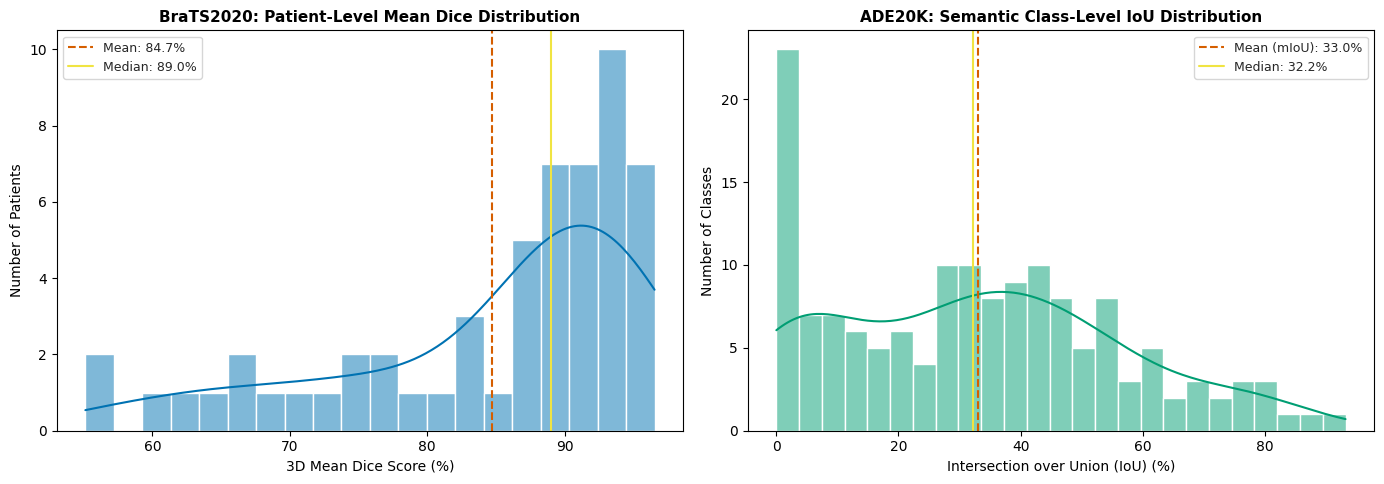

In [ ]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Define workspace parameters
E = "/content/drive/MyDrive/Optimizing VITs/code_v2/experiments"
brats_run = f"{E}/swin_unet-d2262_brats_h1_h2r0.75_s42"
ade_run = f"{E}/swin_unet-d2262_ade20k_h1_h2r0.75_s42"

# Load case evaluation data
with open(os.path.join(brats_run, "per_case.json"), "r") as f:
    brats_data = json.load(f)

with open(os.path.join(ade_run, "per_case.json"), "r") as f:
    ade_data = json.load(f)

# Extract metrics
# BraTS: compute mean 3D Dice per patient over standard evaluation regions (WT, TC, ET)
brats_scores = [
    np.mean([case["dice_WT"], case["dice_TC"], case["dice_ET"]]) * 100
    for case in brats_data.values()
]

# ADE20K: Extract IoU per semantic class from the dataset evaluation metadata
ade_scores = [iou * 100 for iou in ade_data["per_class_iou"] if iou is not None and not np.isnan(iou)]

# --- Create the double subplot distributions ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.set_theme(style="whitegrid")

# Left Panel: BraTS Patient-level Mean Dice Distribution
sns.histplot(brats_scores, bins=20, kde=True, ax=axes[0], color="#0072B2")
axes[0].set_title("BraTS2020: Patient-Level Mean Dice Distribution", fontsize=11, fontweight="bold")
axes[0].set_xlabel("3D Mean Dice Score (%)", fontsize=10)
axes[0].set_ylabel("Number of Patients", fontsize=10)
axes[0].axvline(np.mean(brats_scores), color="#D55E00", linestyle="--", linewidth=1.5, label=f"Mean: {np.mean(brats_scores):.1f}%")
axes[0].axvline(np.median(brats_scores), color="#F0E442", linestyle="-", linewidth=1.5, label=f"Median: {np.median(brats_scores):.1f}%")
axes[0].legend(fontsize=9)

# Right Panel: ADE20K Class-level IoU Distribution
sns.histplot(ade_scores, bins=25, kde=True, ax=axes[1], color="#009E73")
axes[1].set_title("ADE20K: Semantic Class-Level IoU Distribution", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Intersection over Union (IoU) (%)", fontsize=10)
axes[1].set_ylabel("Number of Classes", fontsize=10)
axes[1].axvline(np.mean(ade_scores), color="#D55E00", linestyle="--", linewidth=1.5, label=f"Mean (mIoU): {np.mean(ade_scores):.1f}%")
axes[1].axvline(np.median(ade_scores), color="#F0E442", linestyle="-", linewidth=1.5, label=f"Median: {np.median(ade_scores):.1f}%")
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.show()

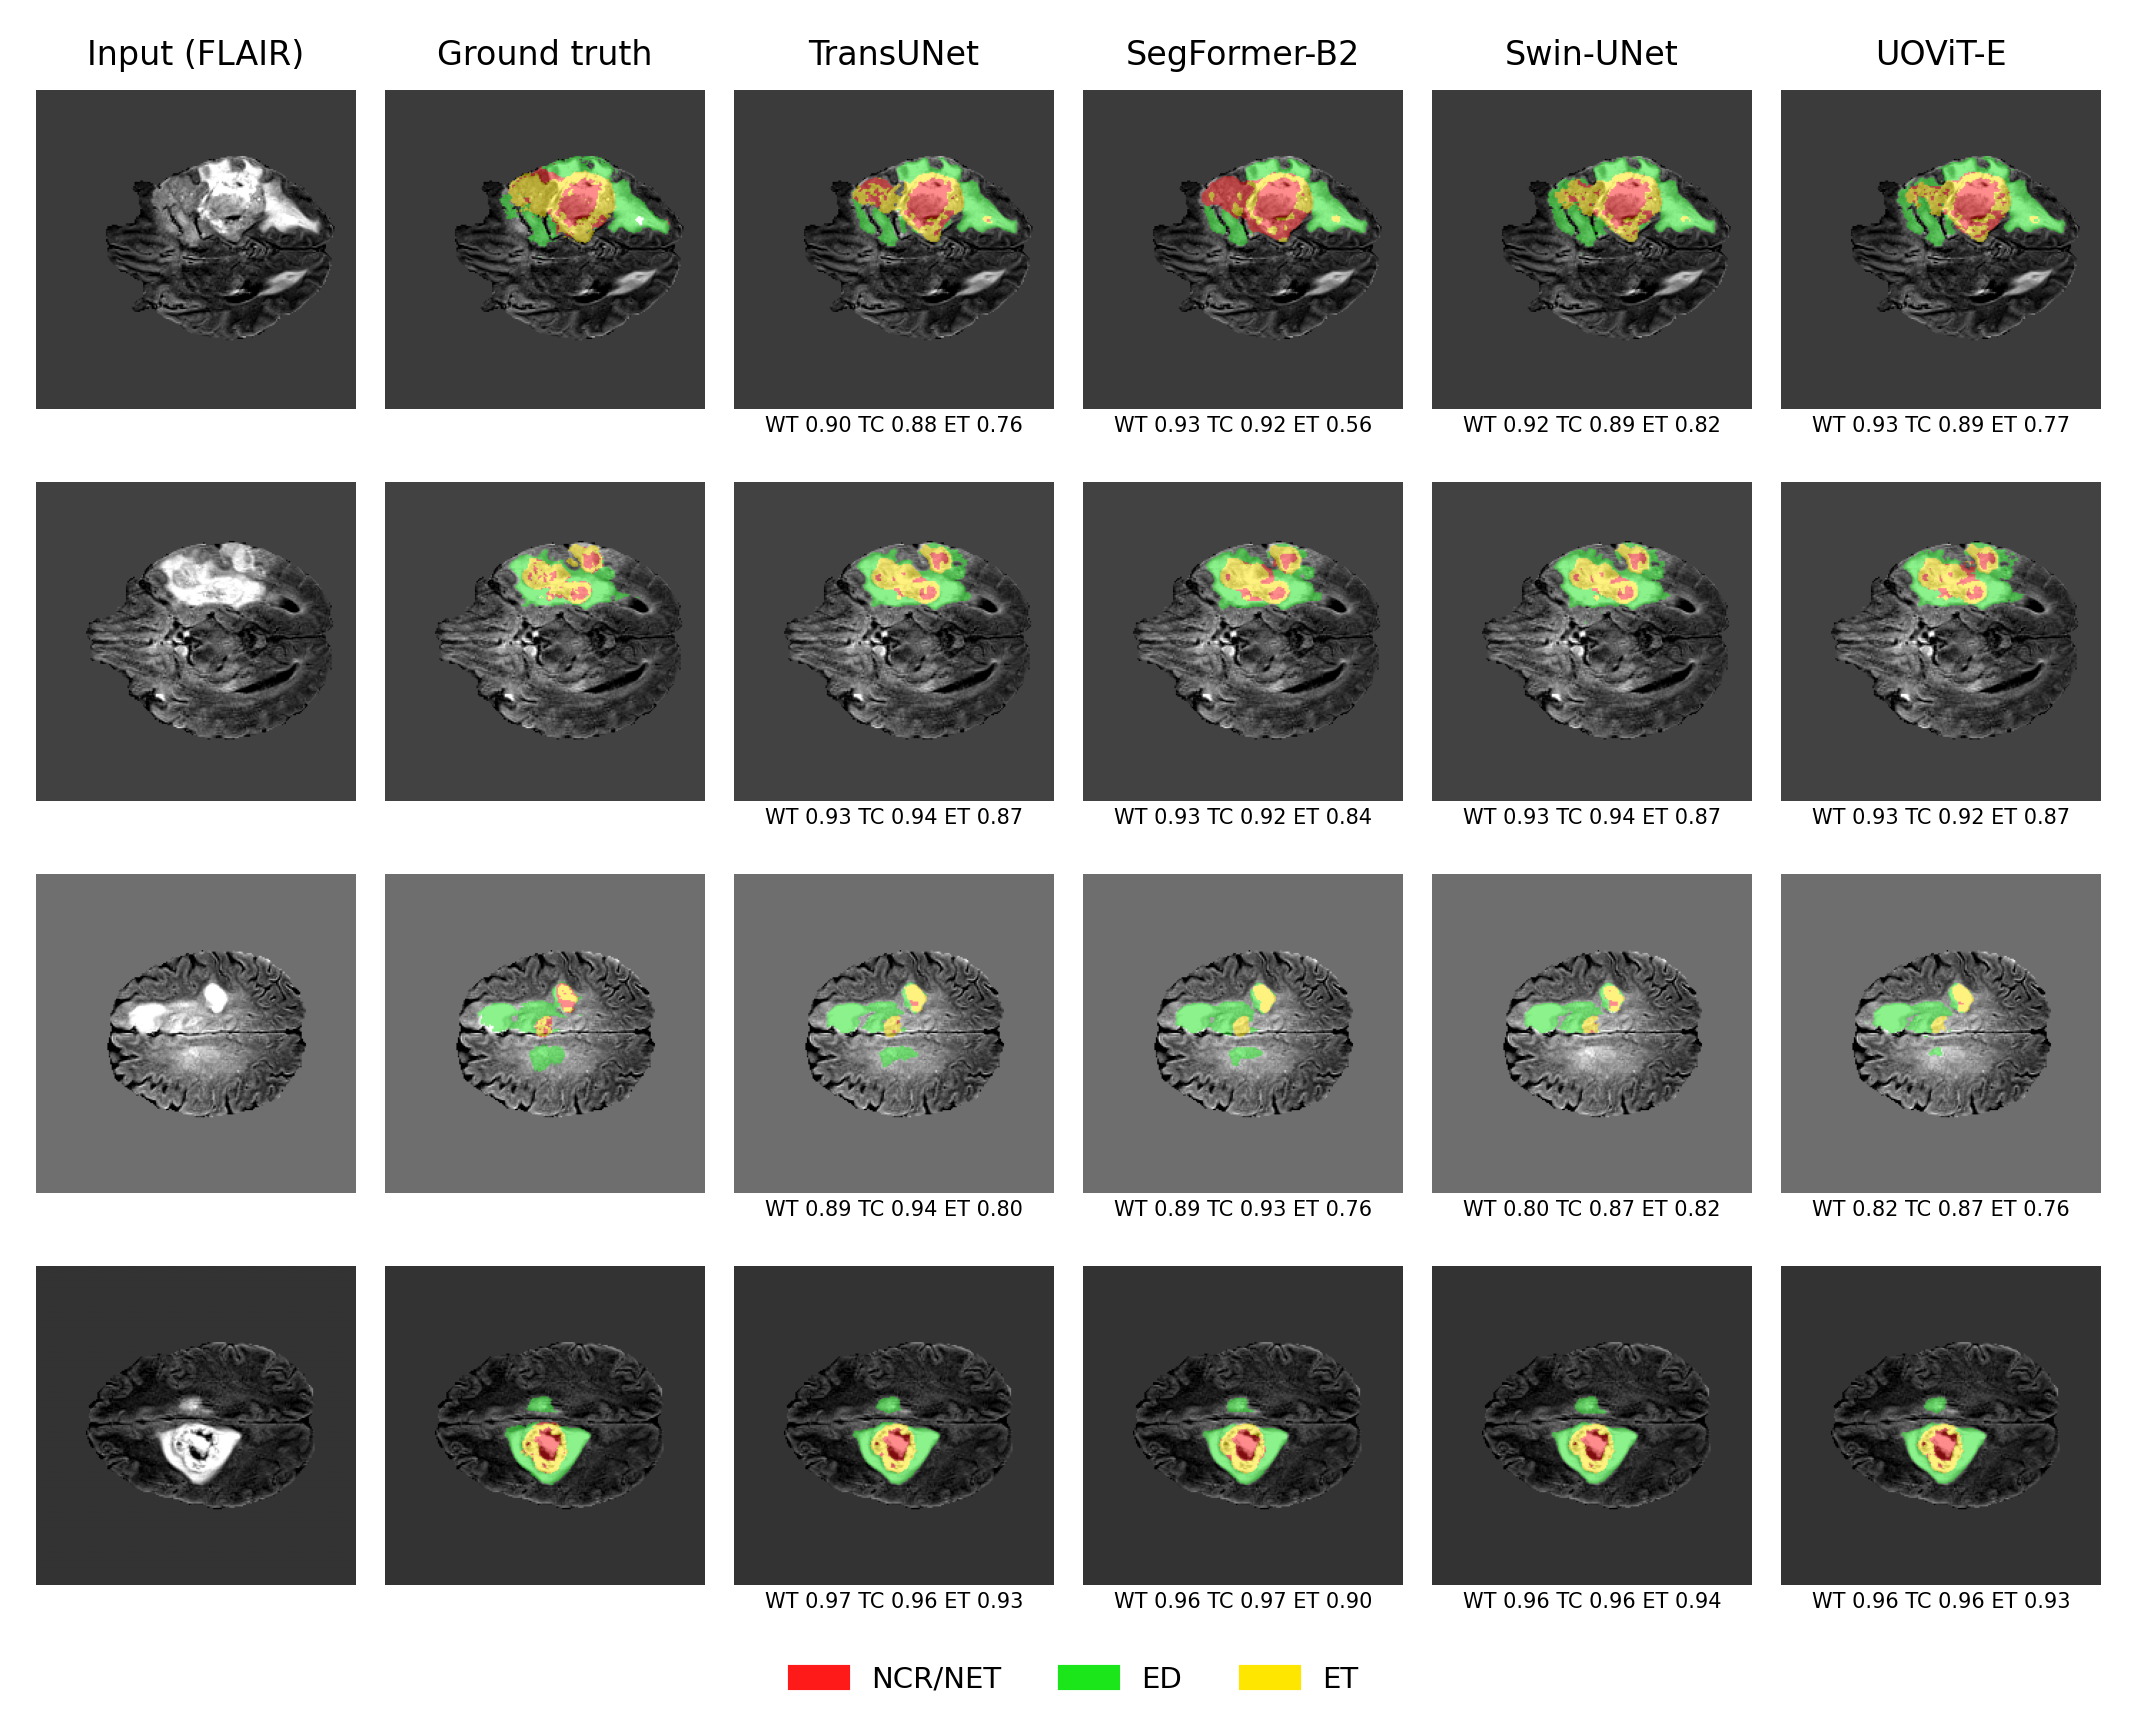

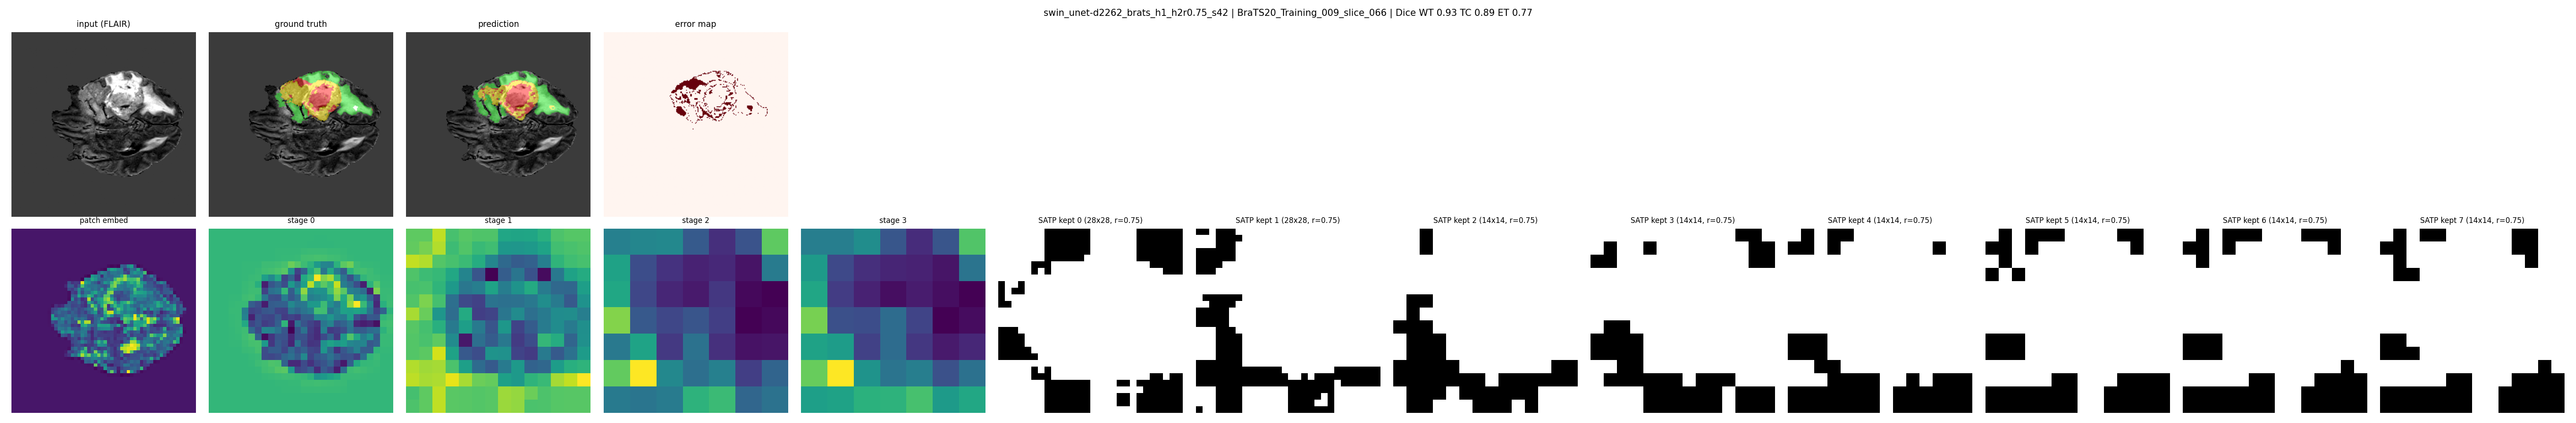

In [ ]:
from IPython.display import Image, display
E = "/content/drive/MyDrive/Optimizing VITs/code_v2/experiments"
display(Image(f"{E}/_analysis/figures/comparison_brats.png", width=1100))
import glob; display(Image(sorted(glob.glob(f"{E}/swin_unet-d2262_brats_h1_h2r0.75_s42/figures/case_*.png"))[0], width=1400))


=== Figure 3.1: Framework Overview ===


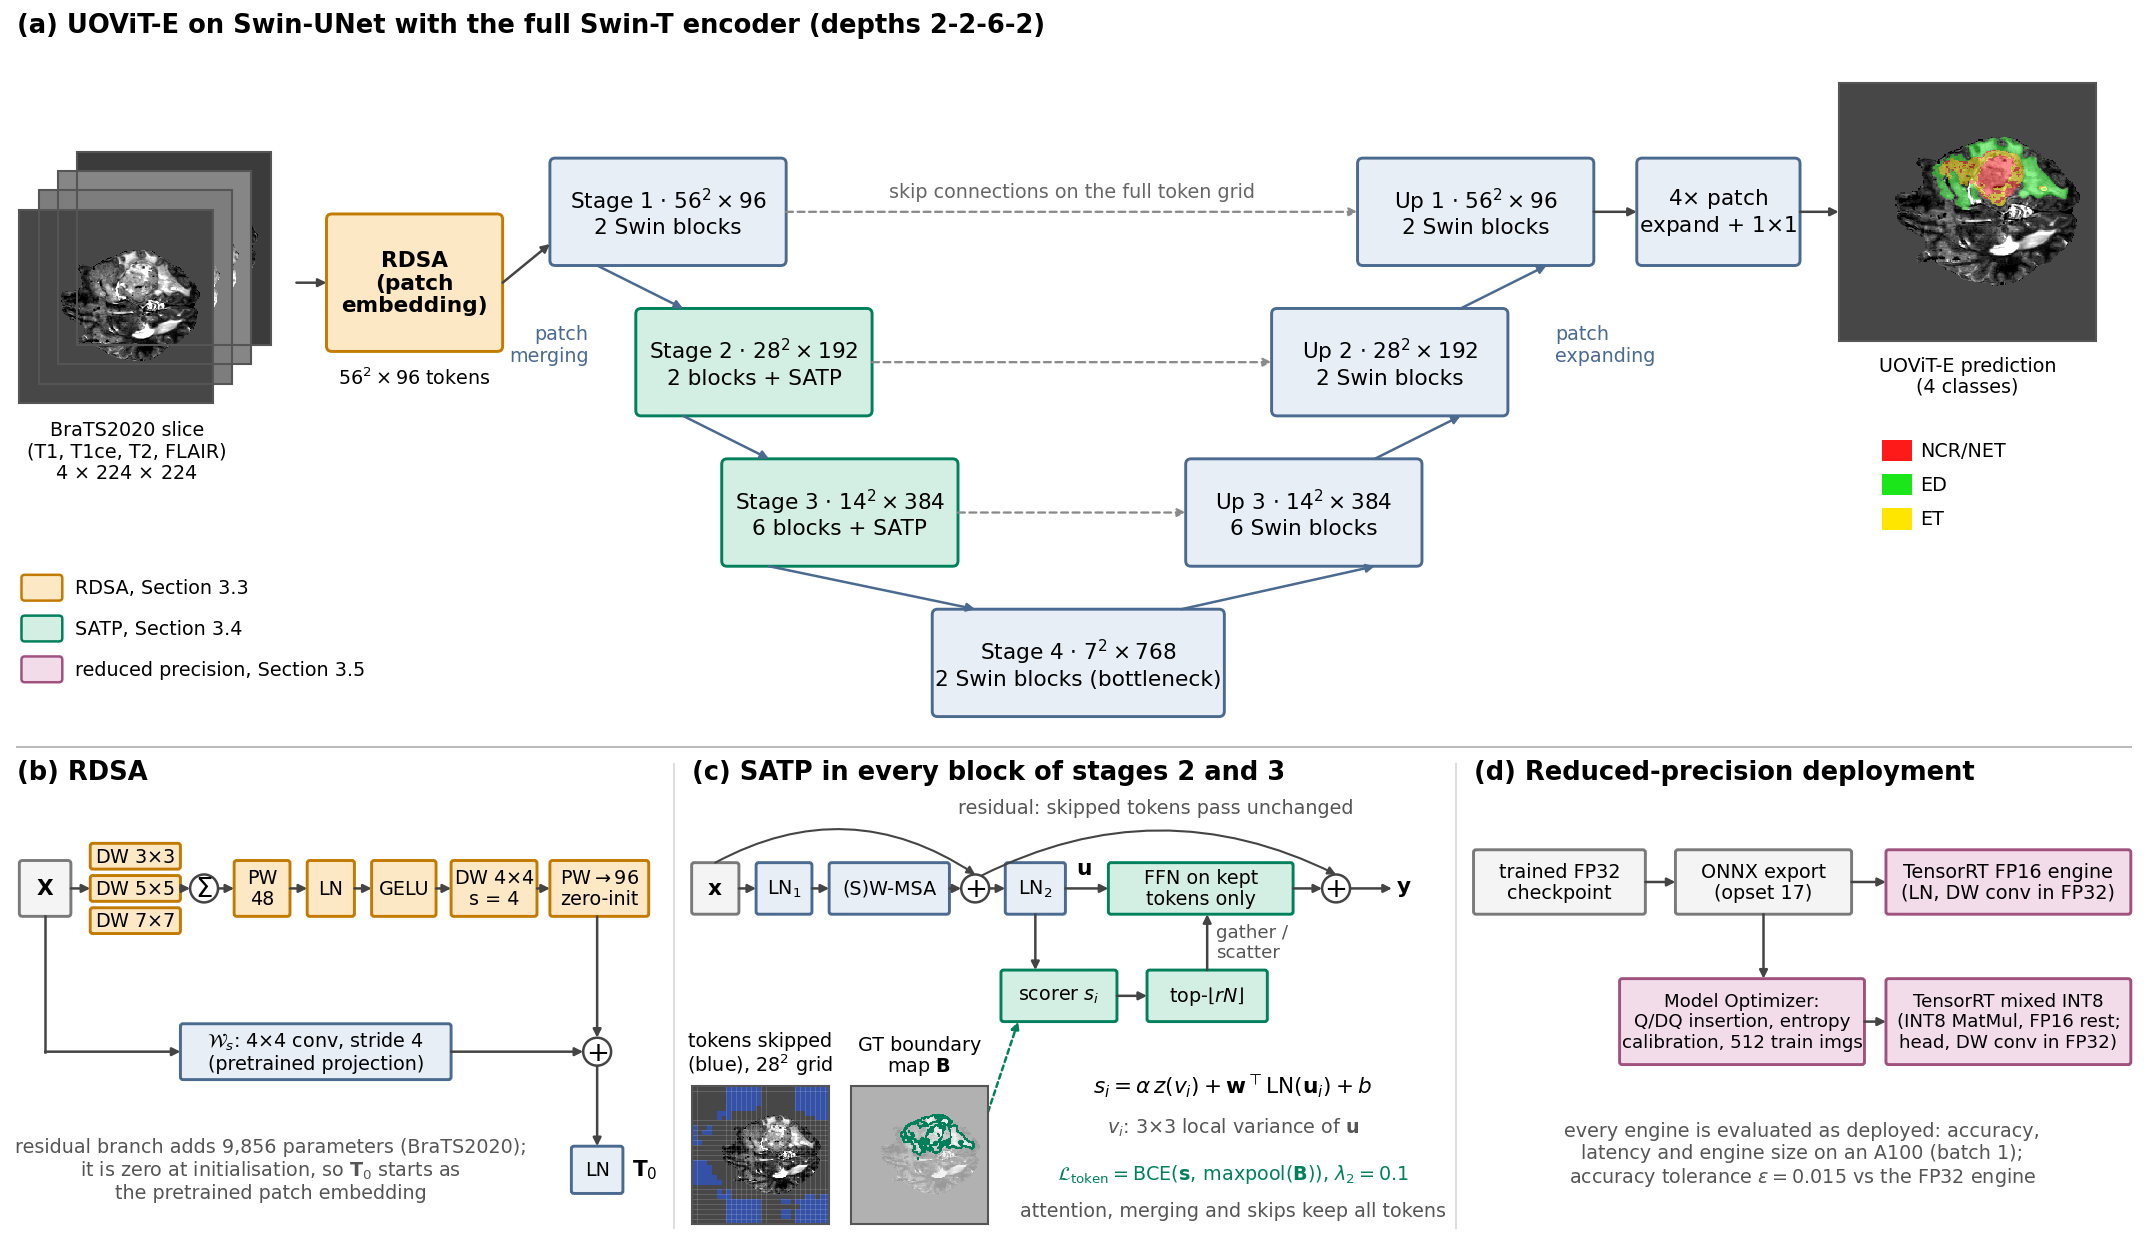


=== Figure 5.1: BraTS2020 Predictions ===


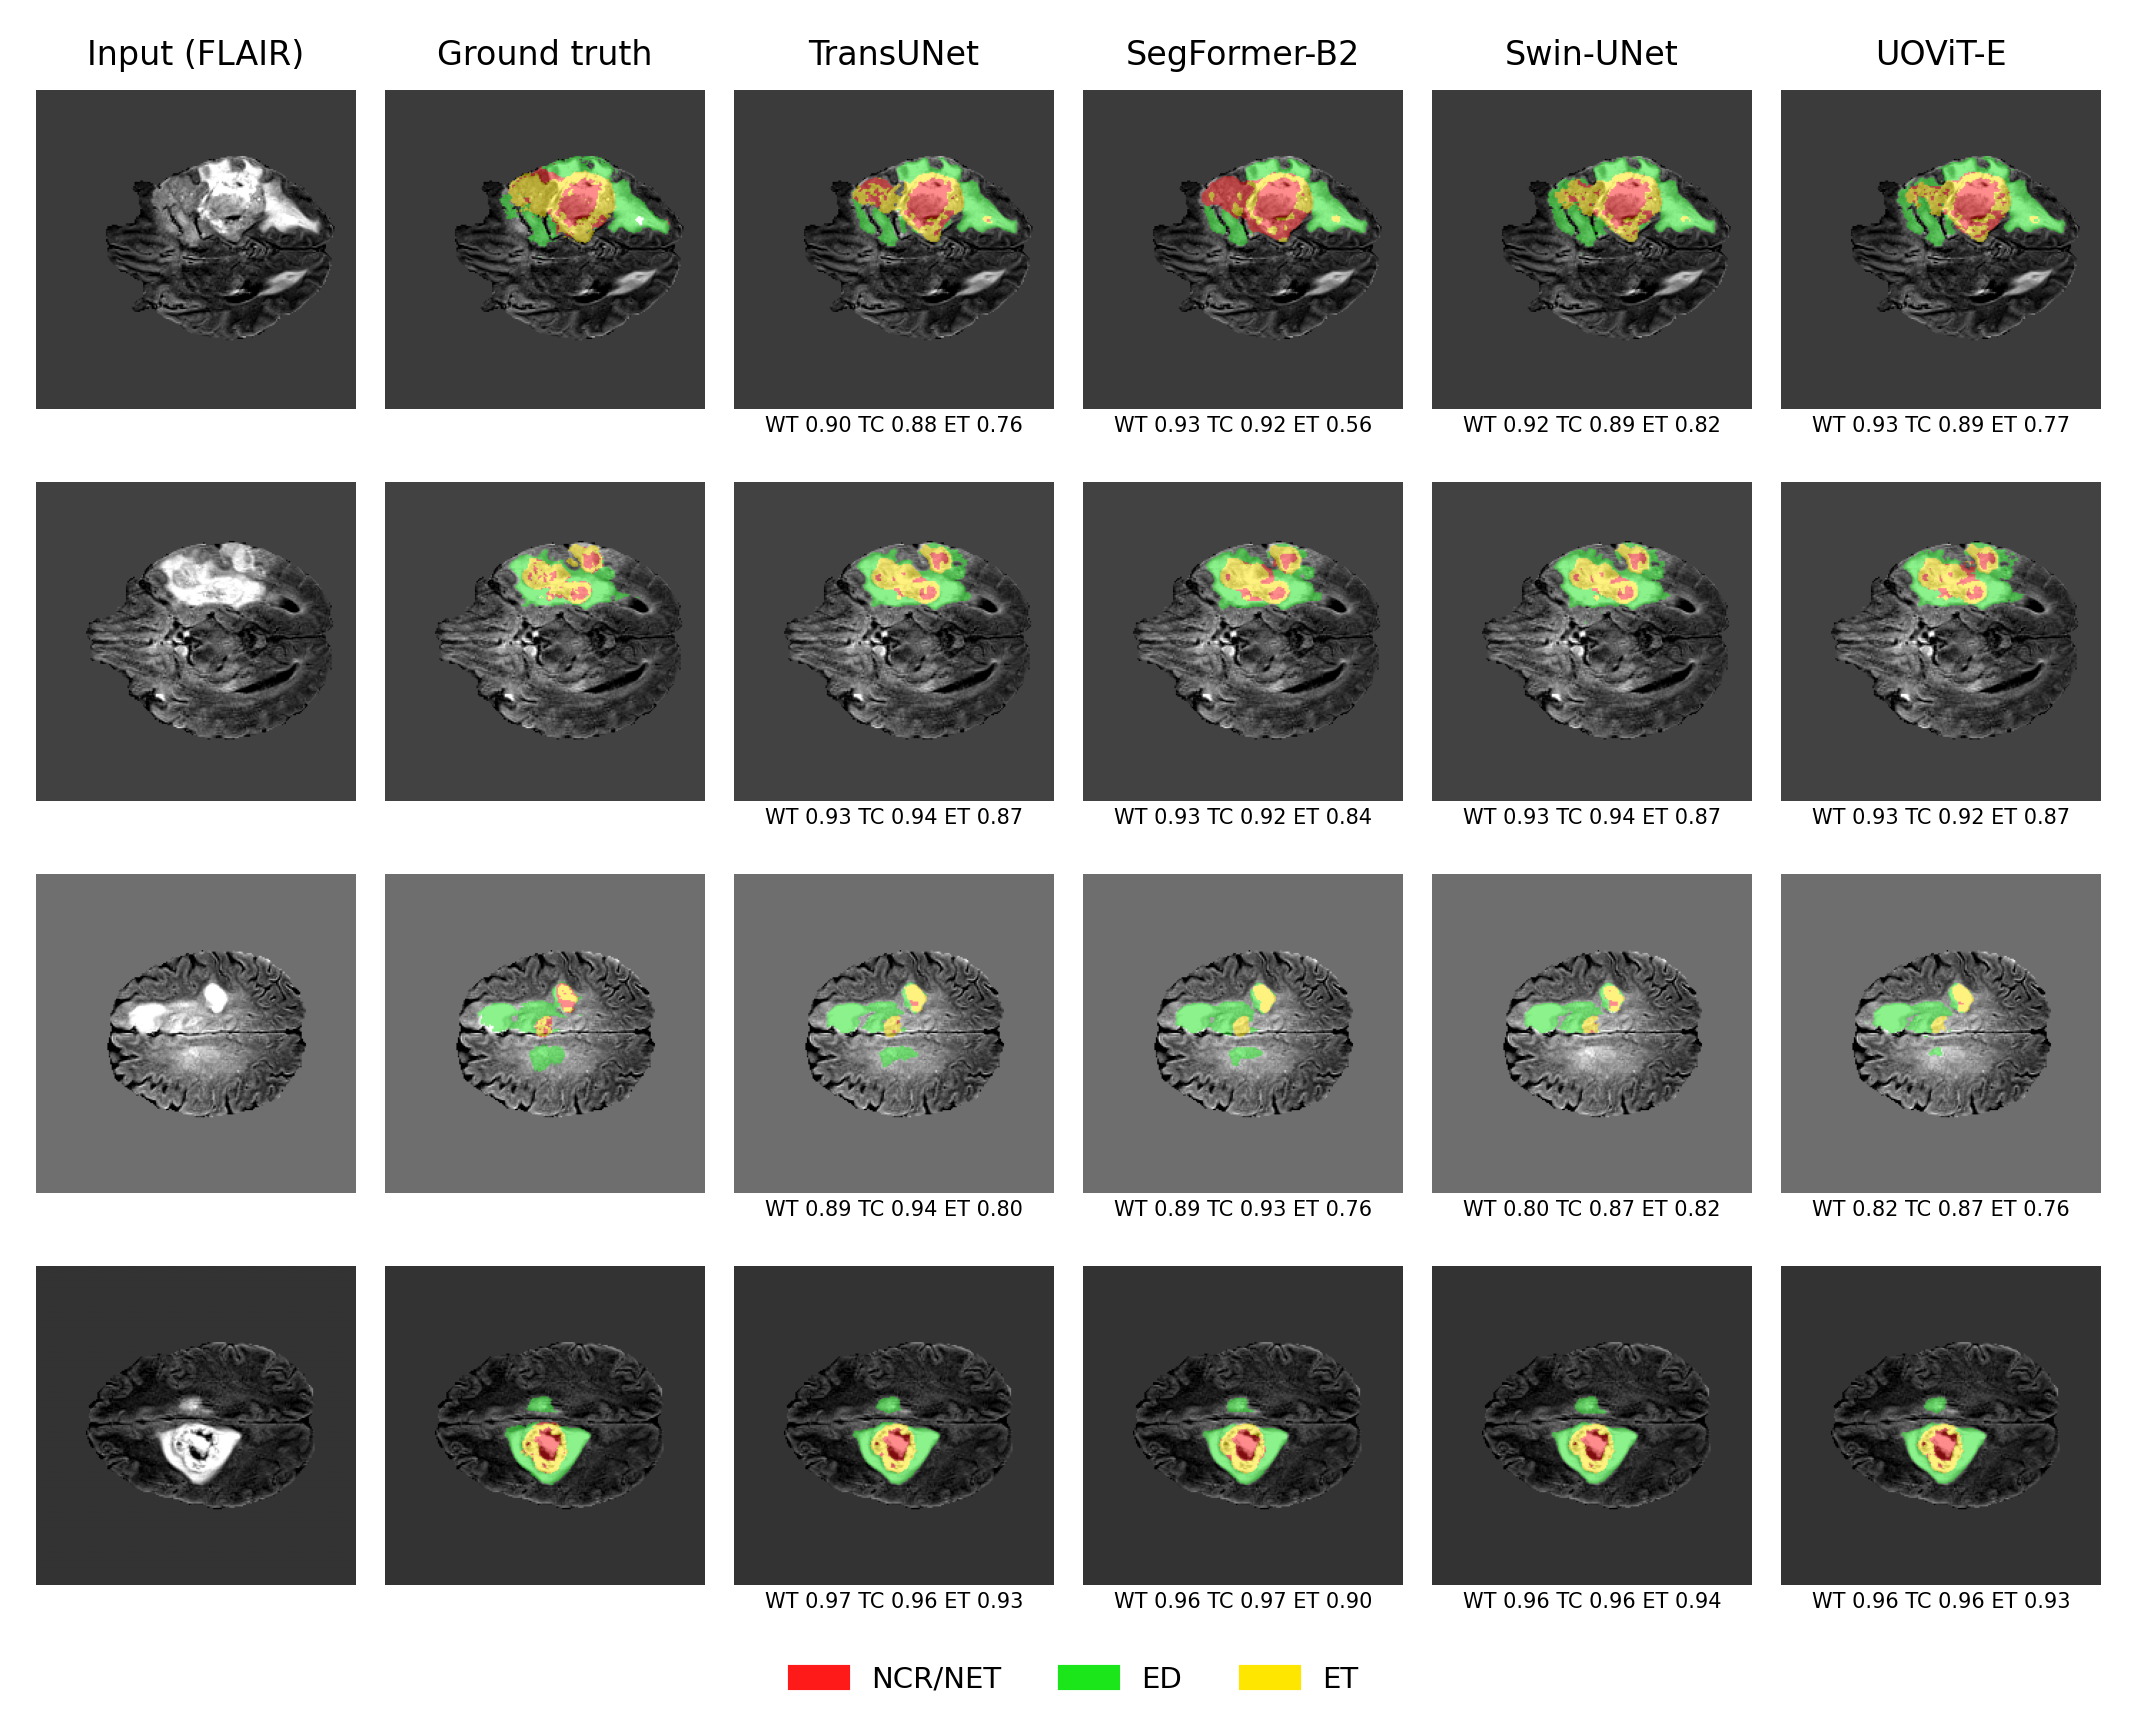


=== Figure 5.2: ADE20K Predictions ===


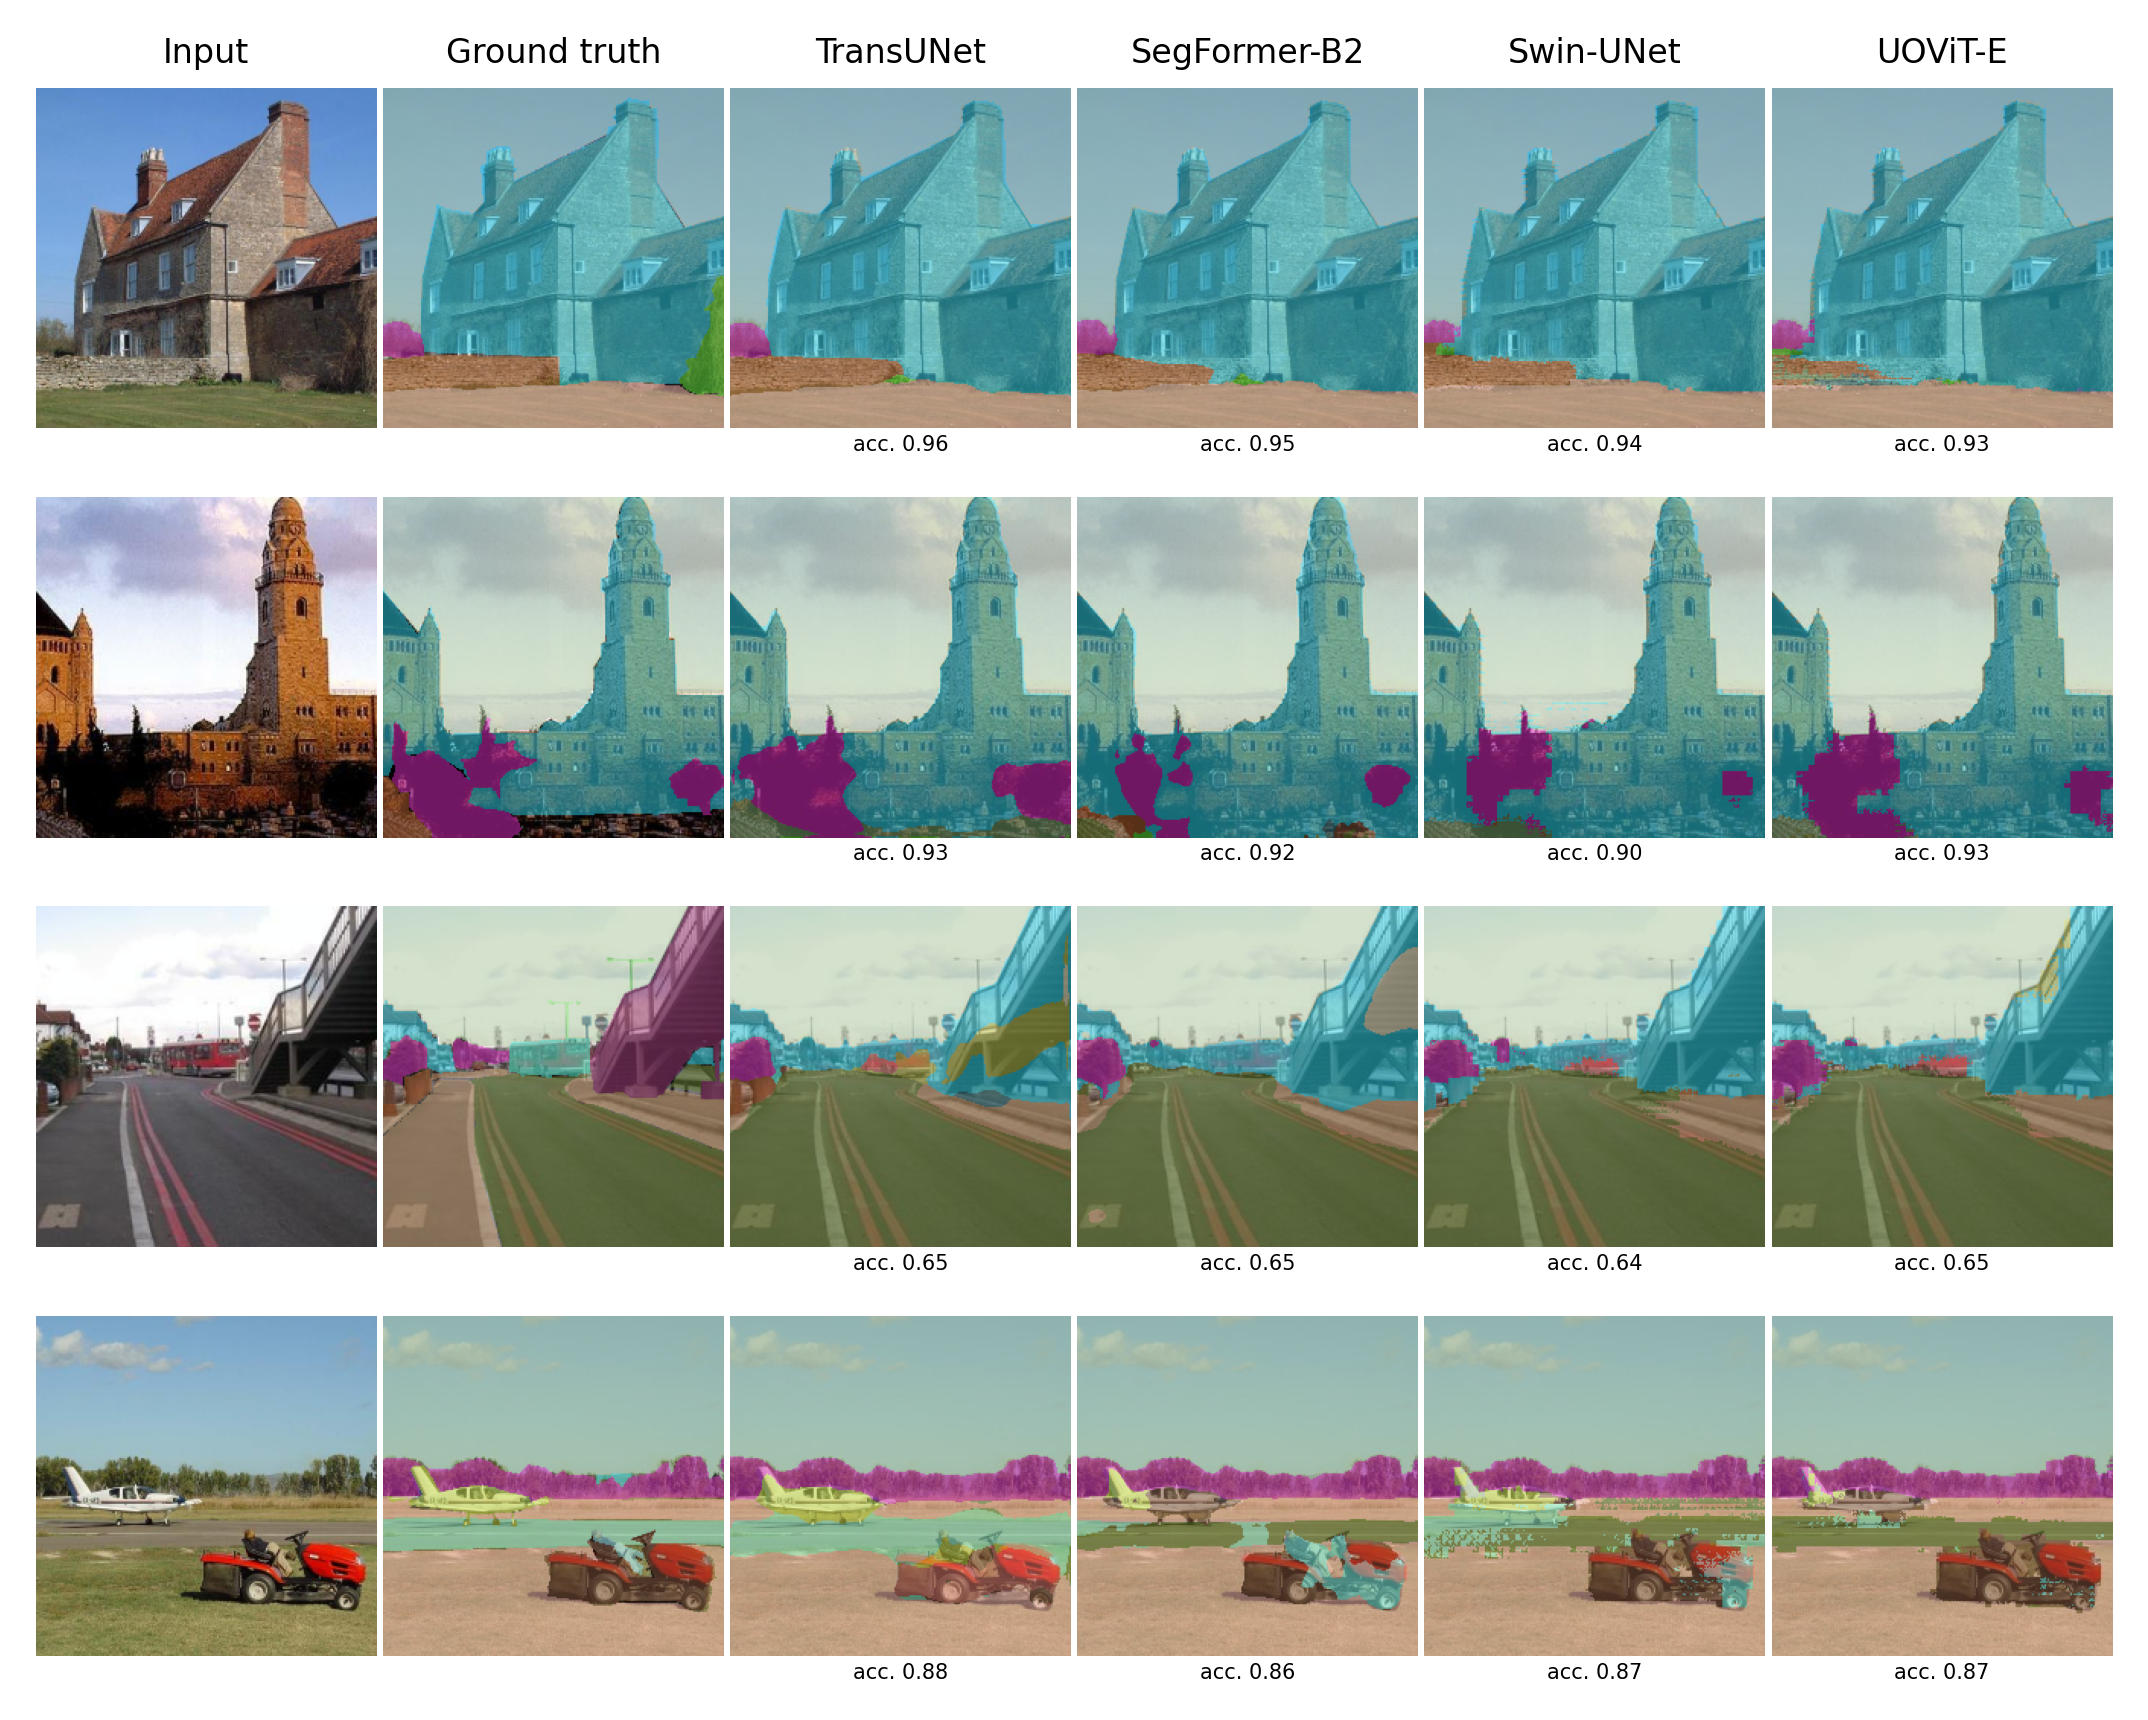


=== Figure 5.3: SATP Token Masks ===


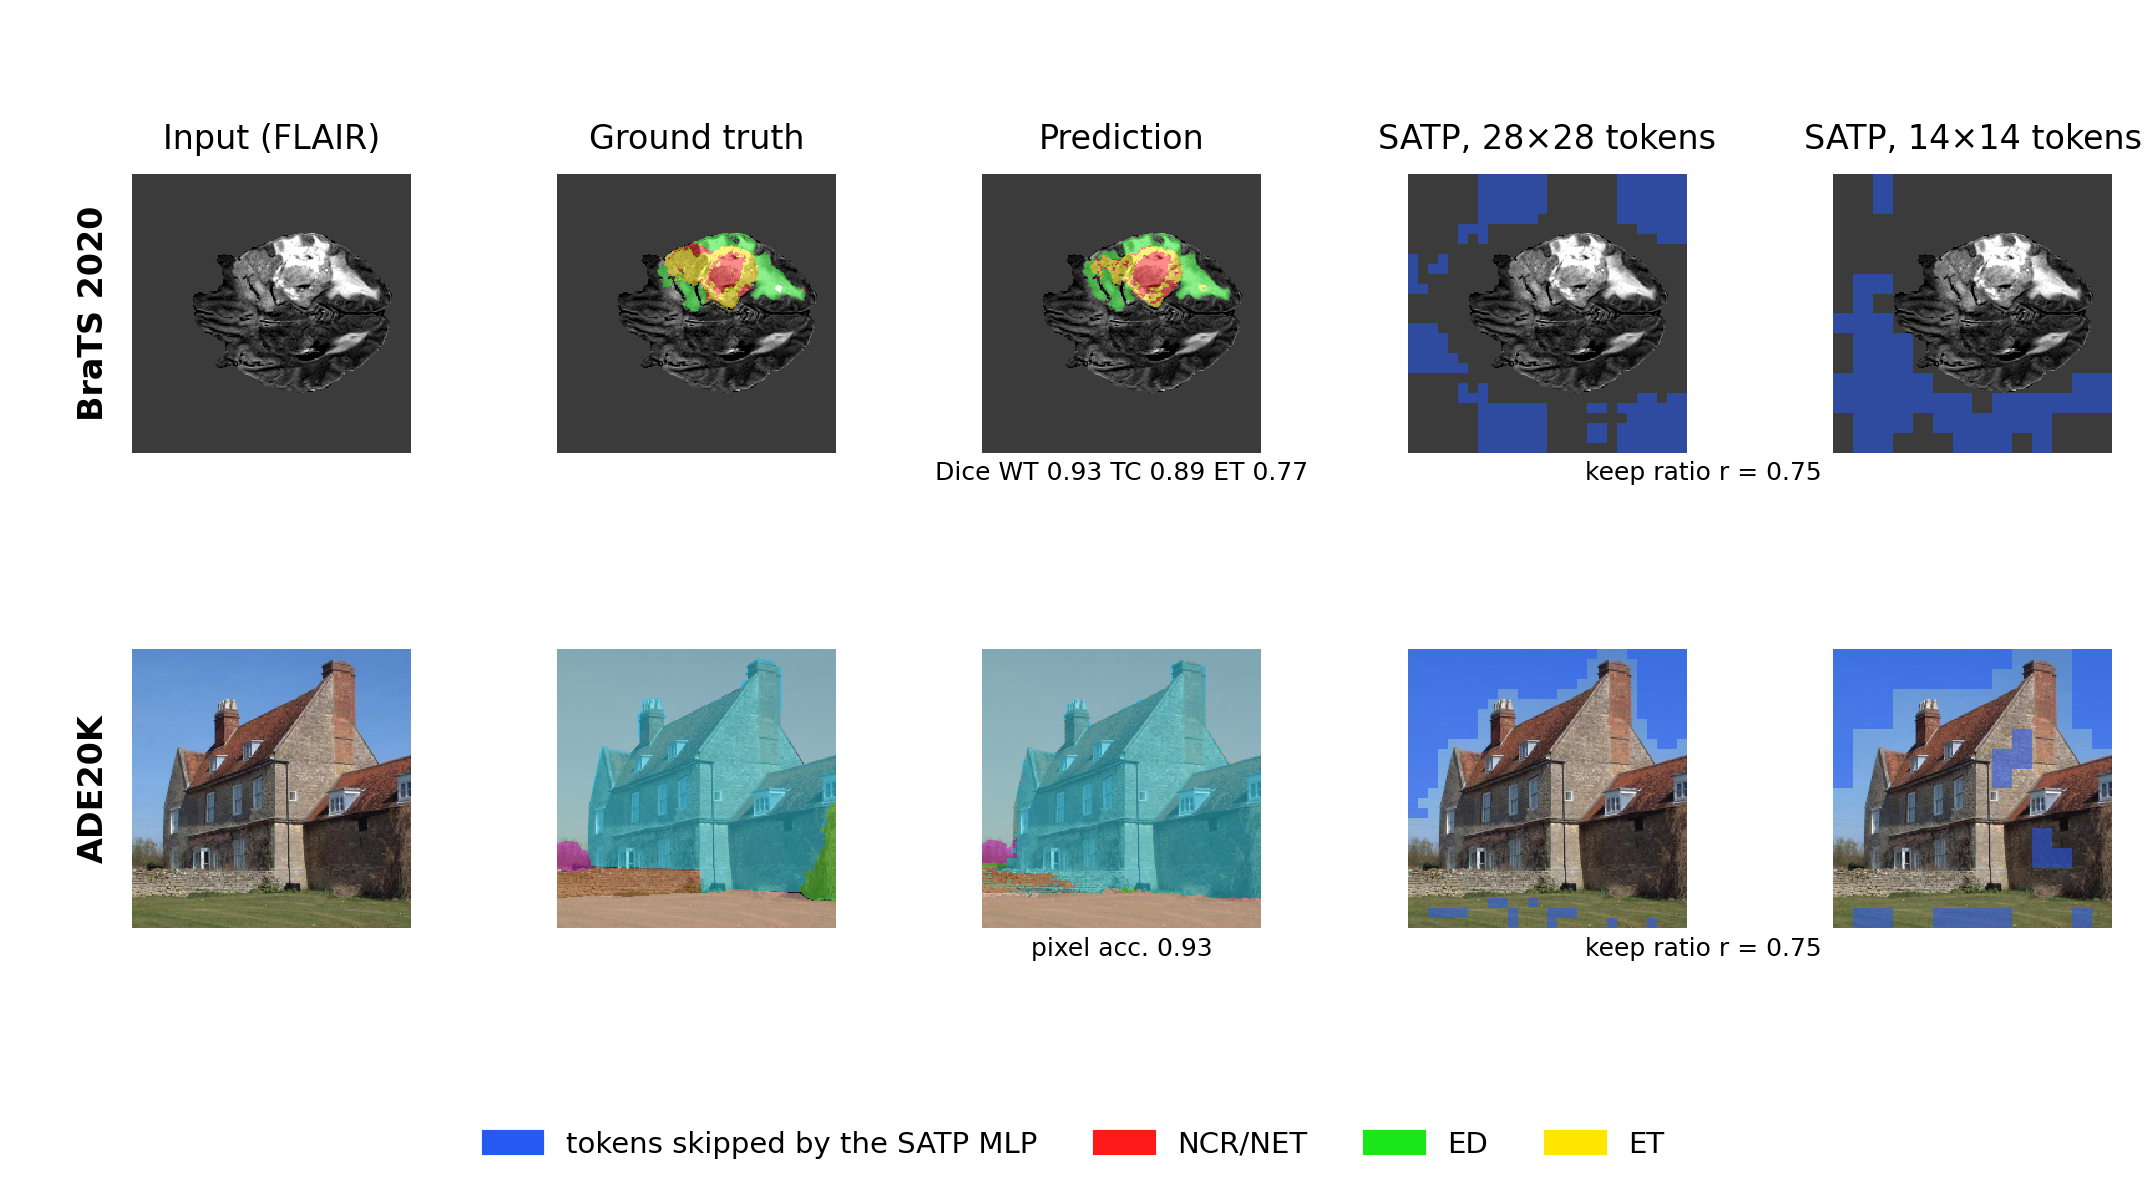


=== Figure 5.4: Accuracy-Latency Pareto ===


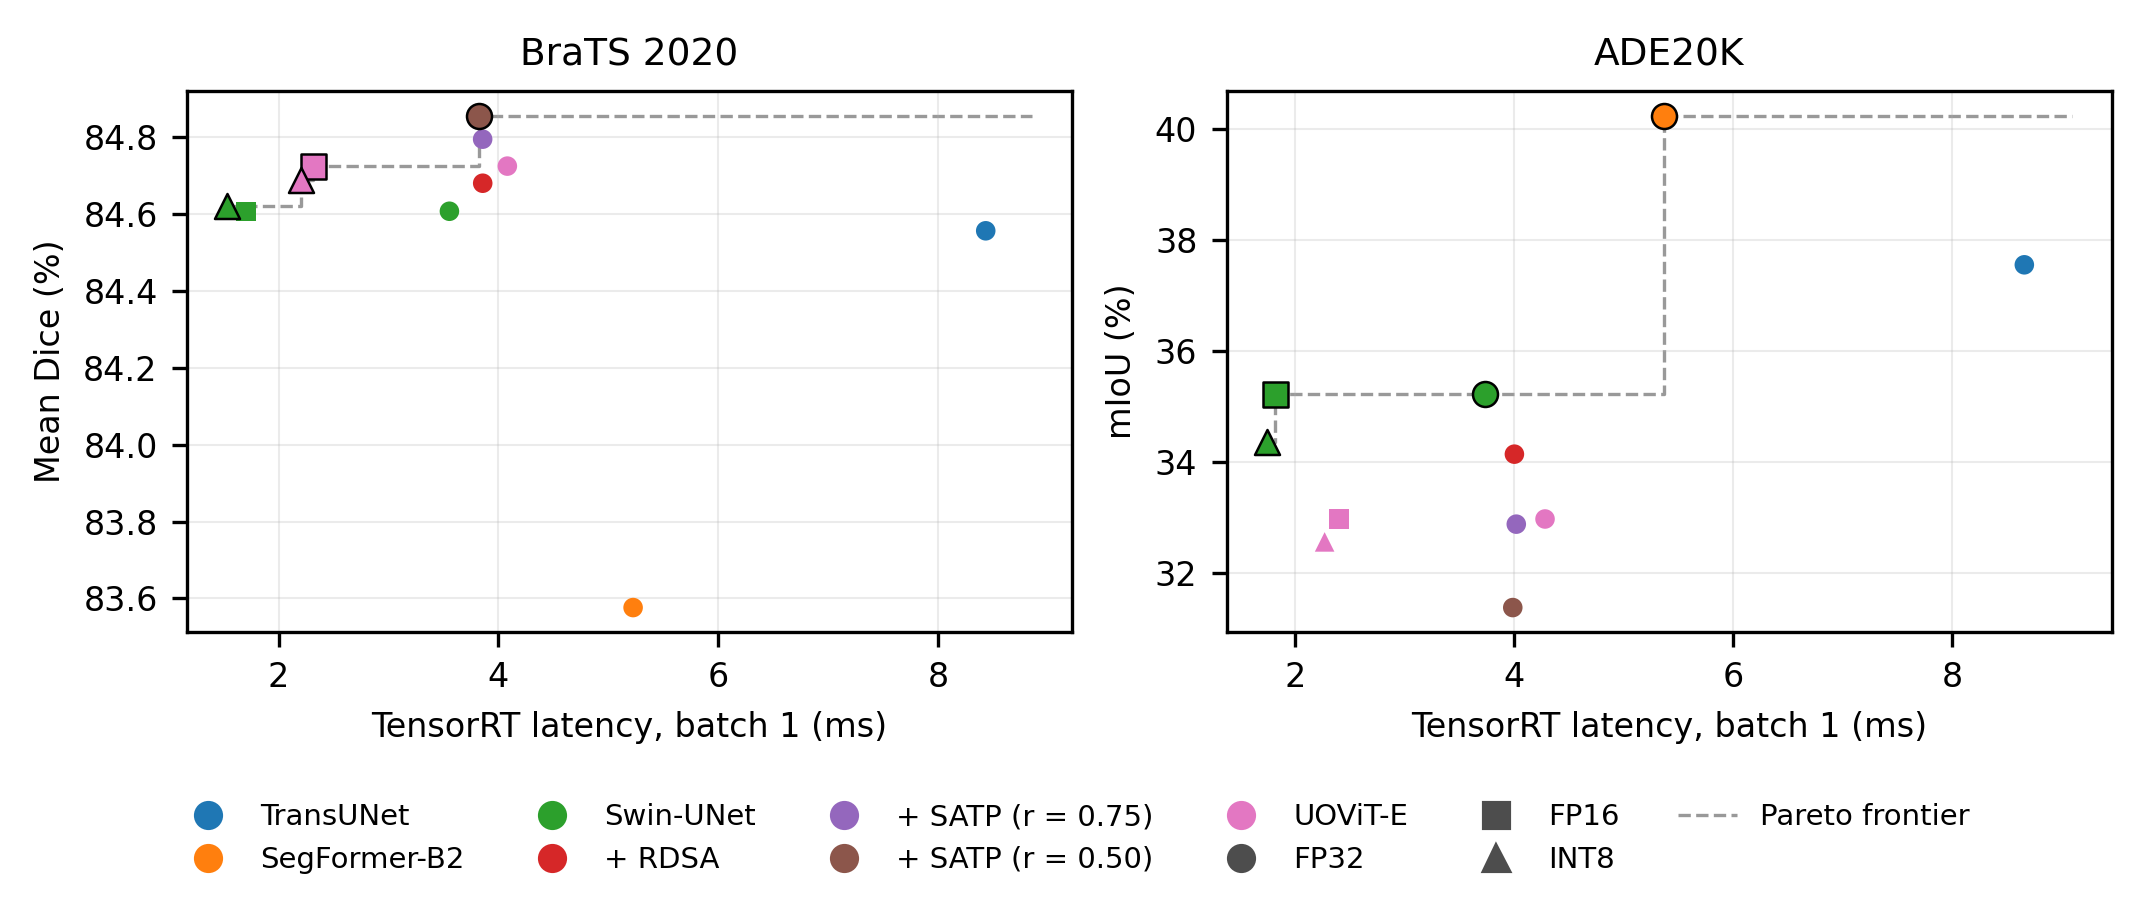


=== Figure 5.5: Accurravy-complexity Pareto ===


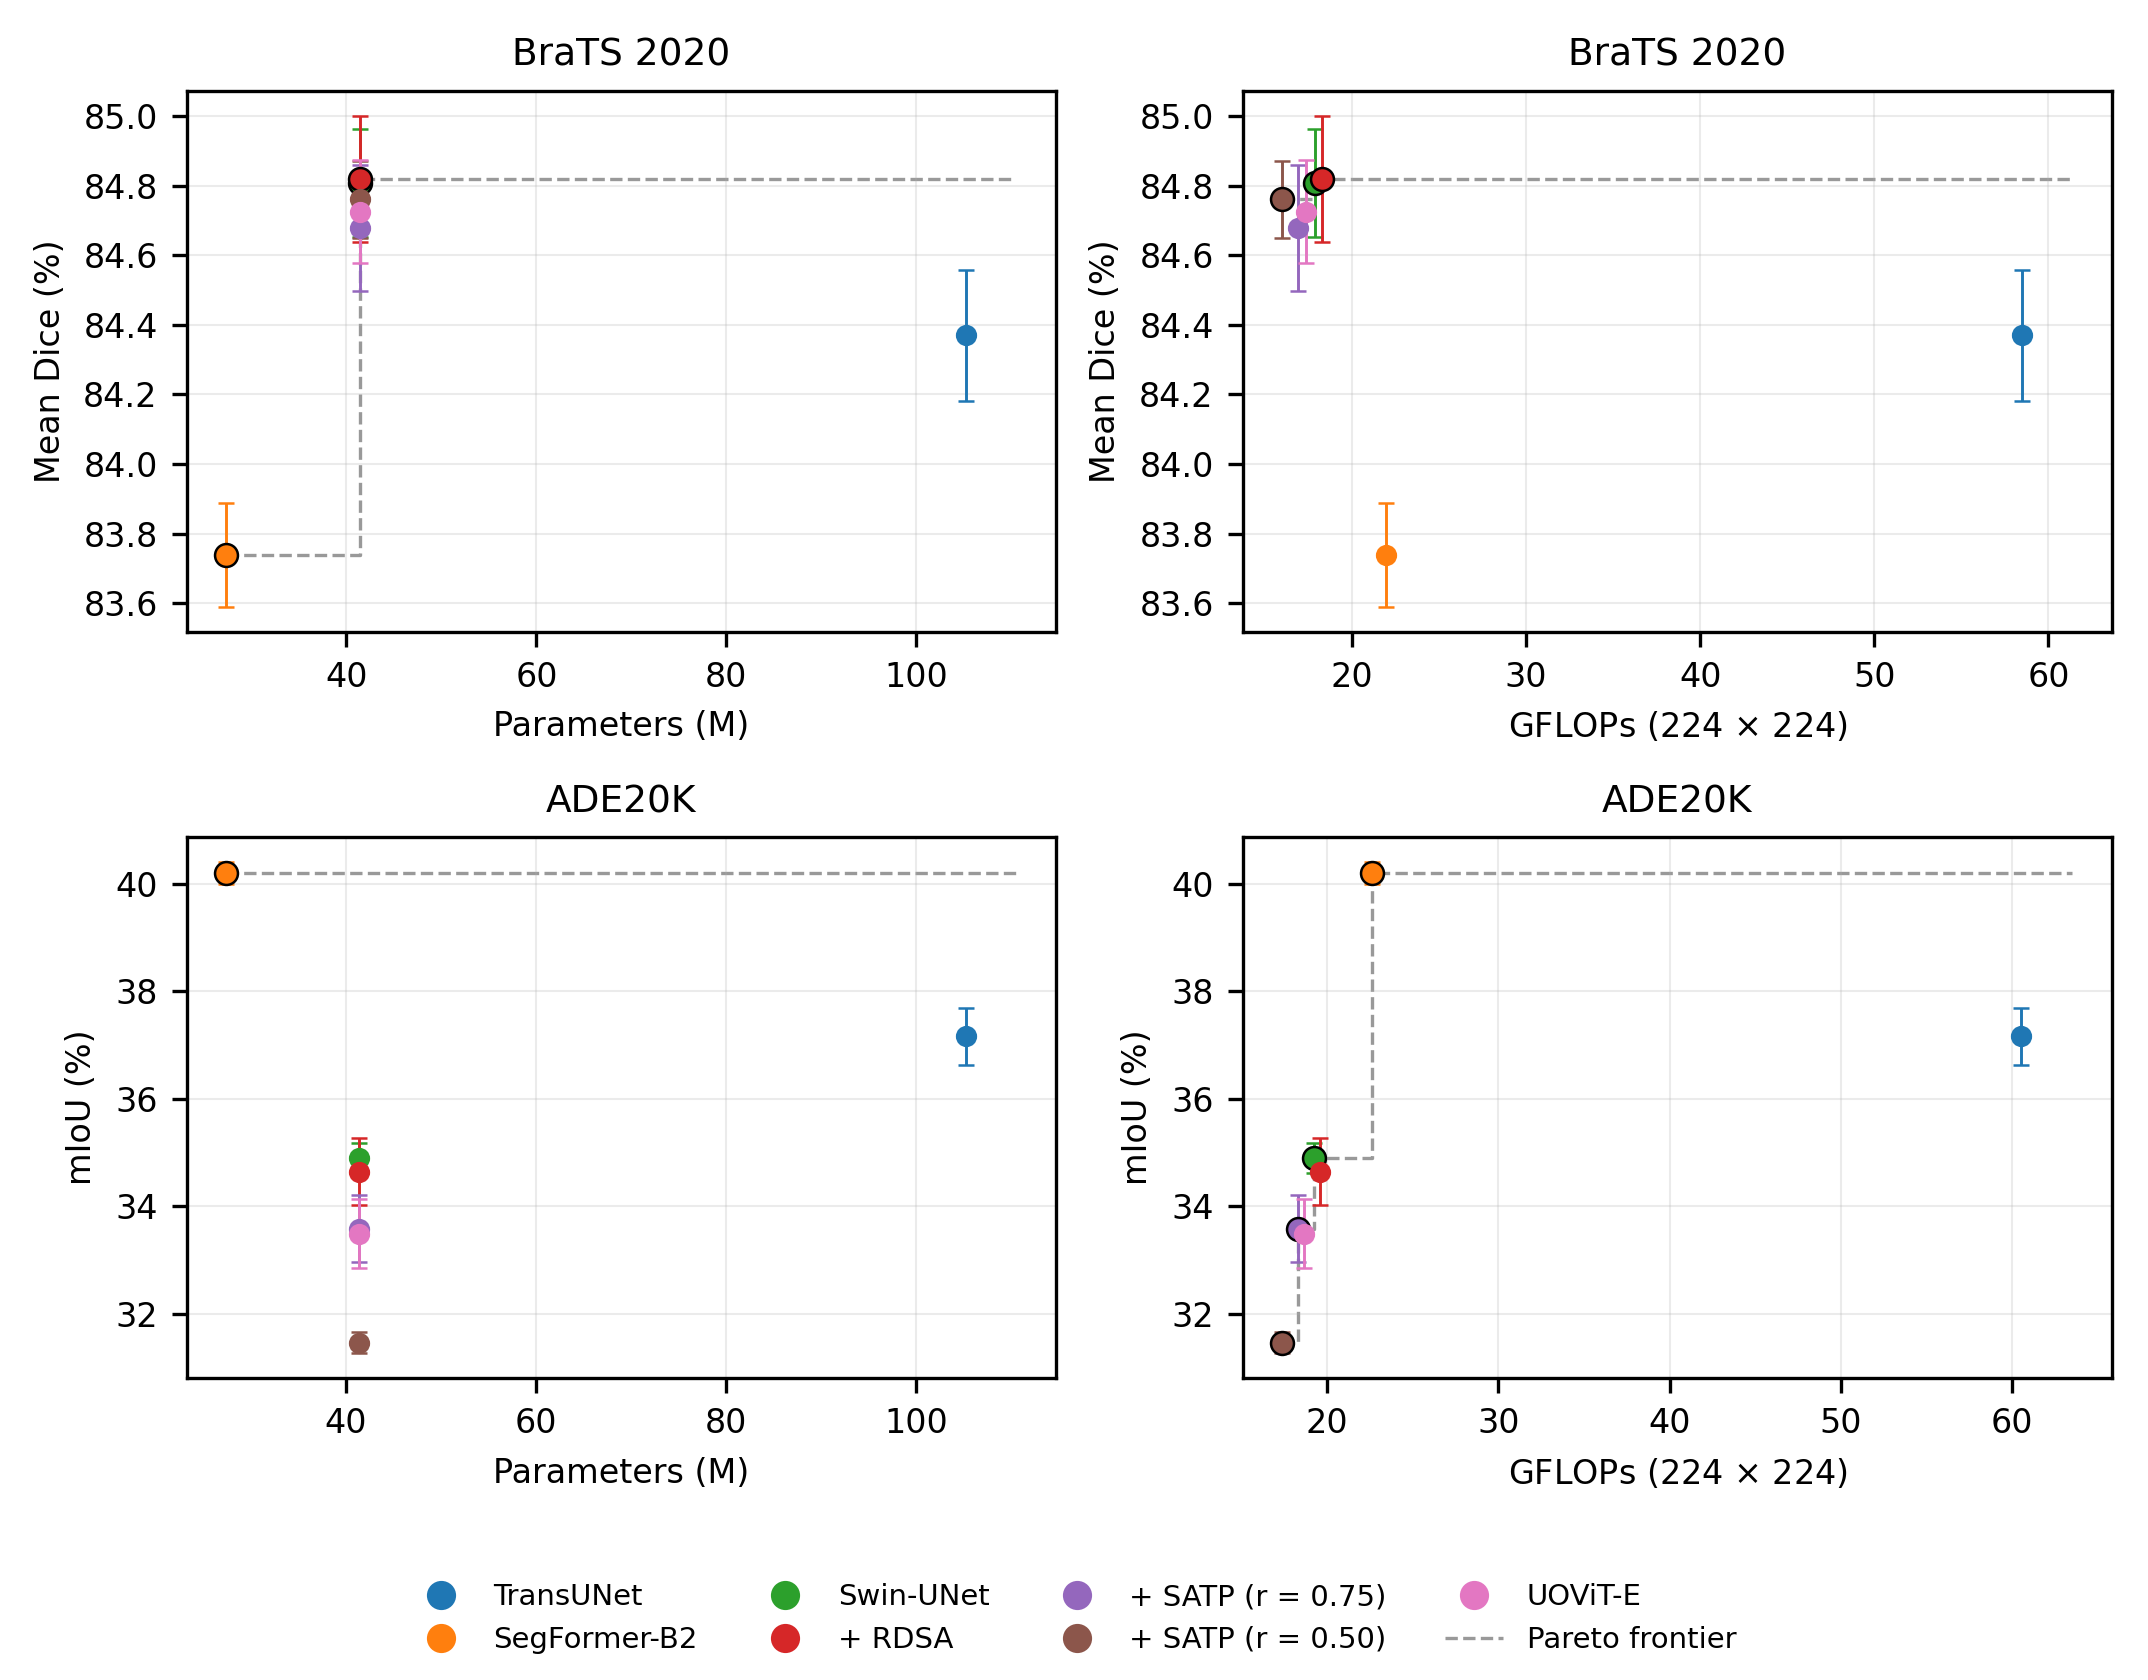


=== Figure 5.6: Training Curves ===


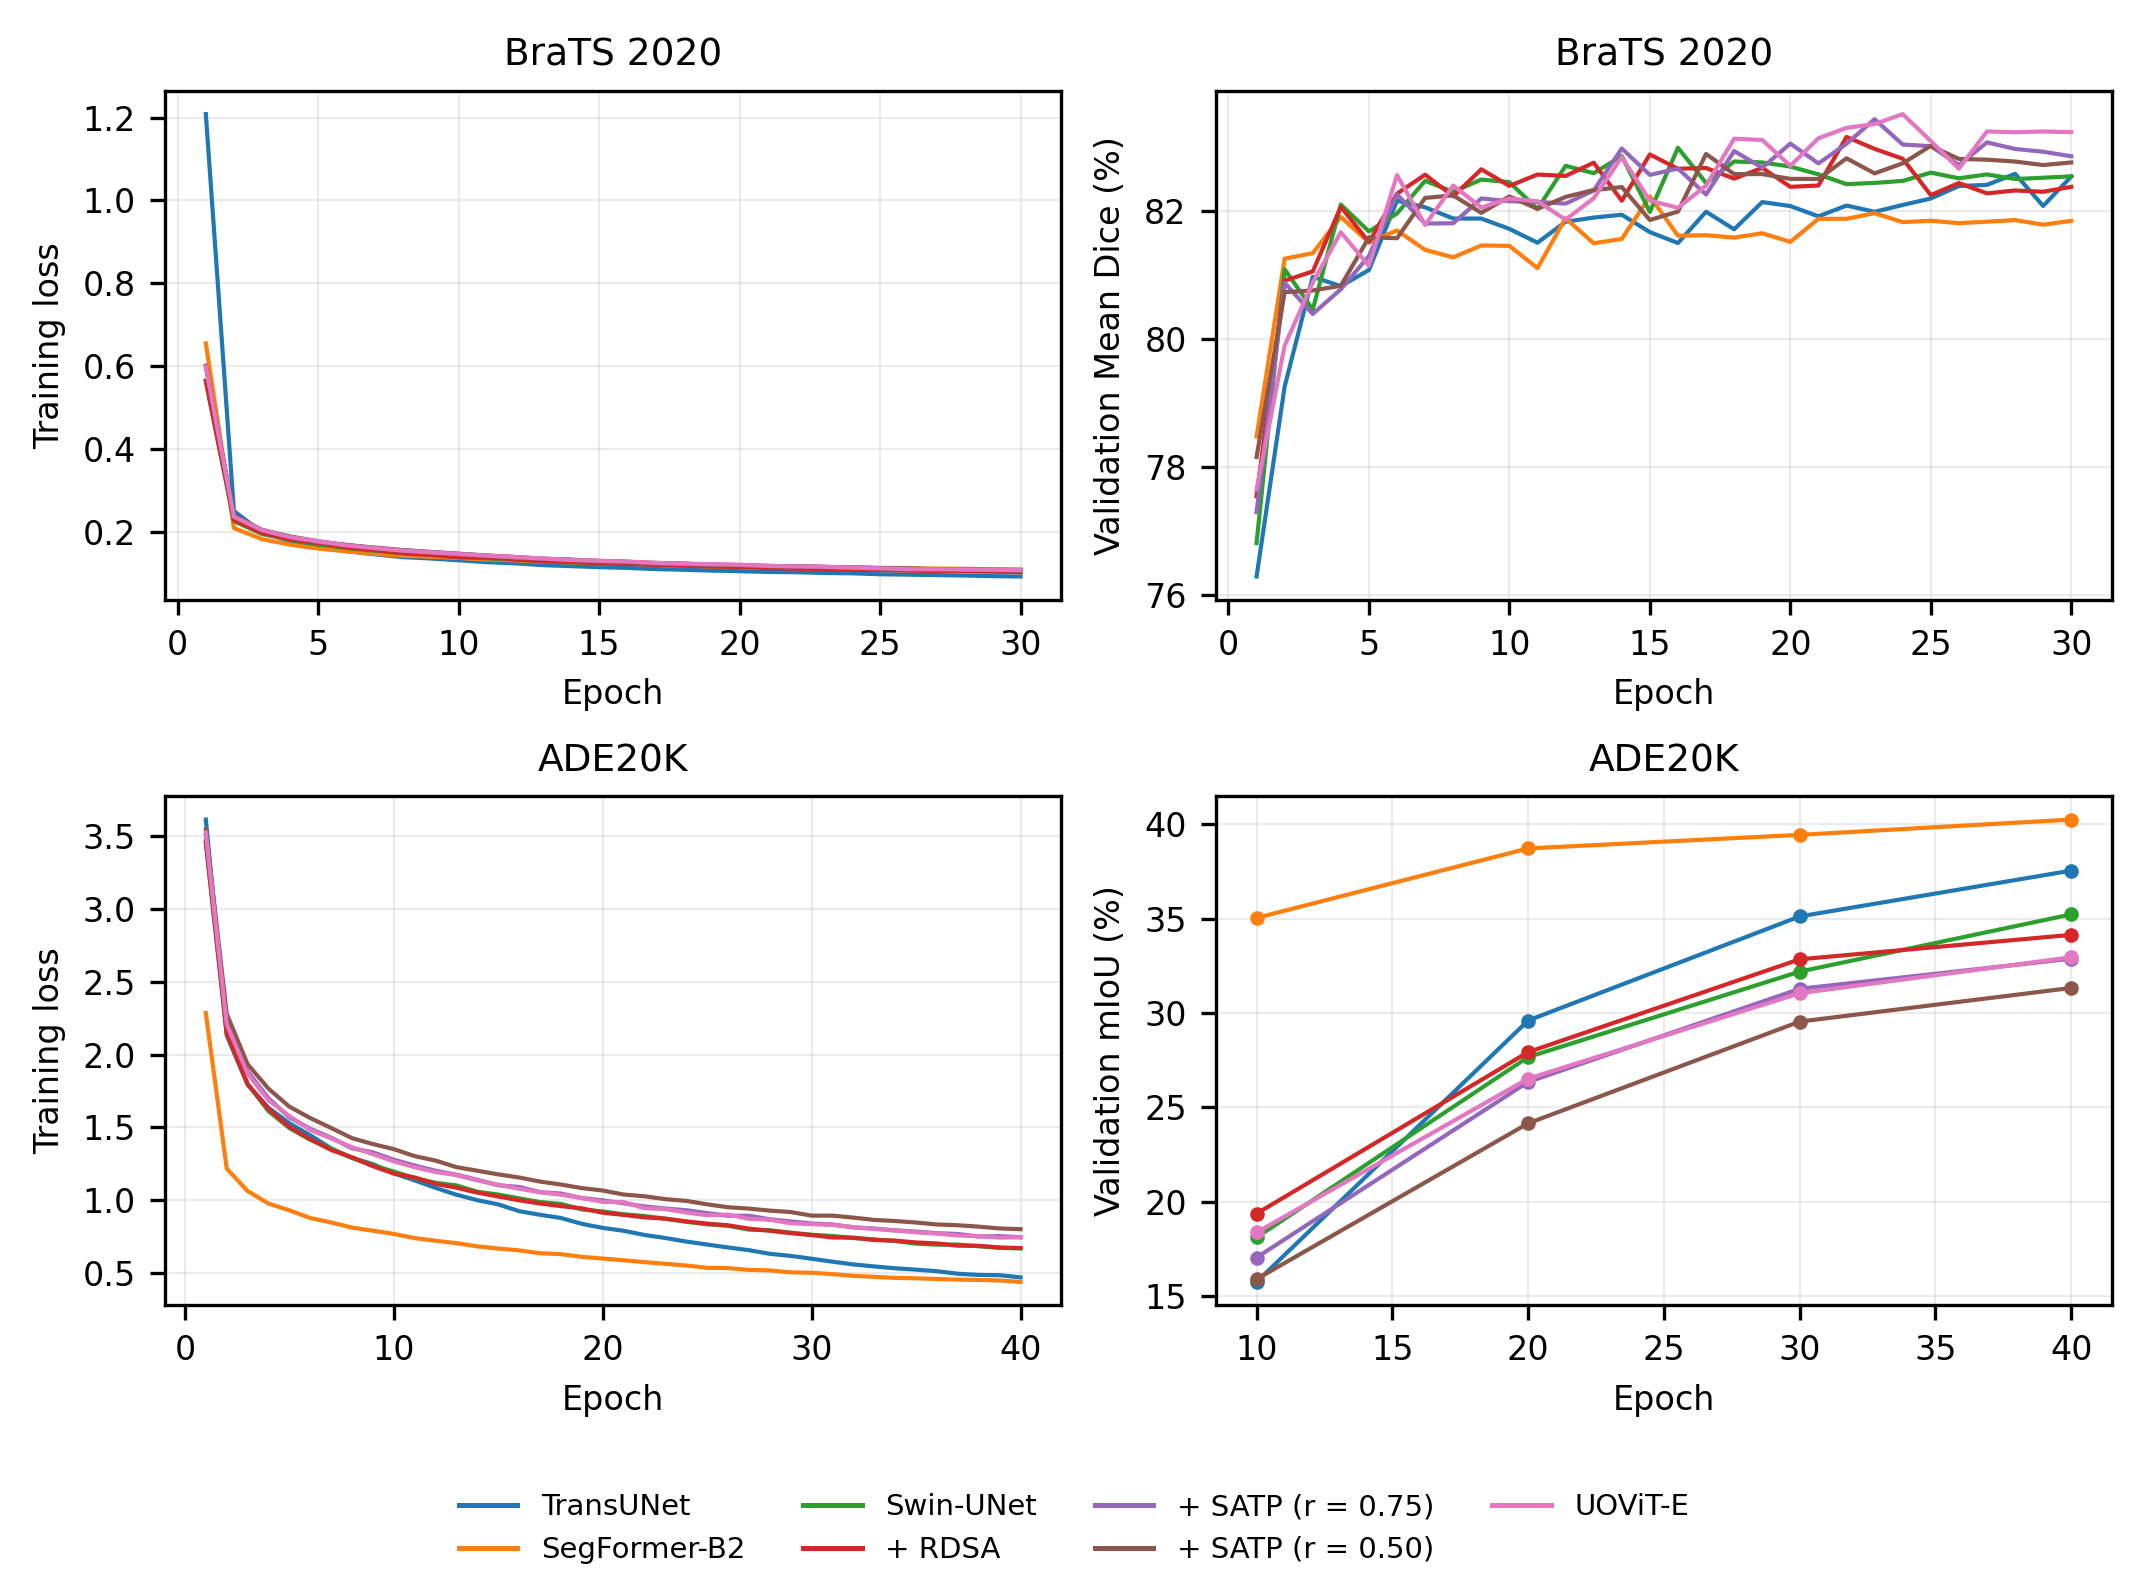

In [ ]:
from IPython.display import Image, display
import os

E = "/content/drive/MyDrive/Optimizing VITs/code_v2/experiments"
figs_dir = f"{E}/_analysis/figures"

all_figures = [
    ("uovite_overview.png", "Figure 3.1: Framework Overview"),
    ("comparison_brats.png", "Figure 5.1: BraTS2020 Predictions"),
    ("comparison_ade20k.png", "Figure 5.2: ADE20K Predictions"),
    ("paper_satp.png", "Figure 5.3: SATP Token Masks"),
    ("pareto.png", "Figure 5.4: Accuracy-Latency Pareto"),
    ("complexity.png","Figure 5.5: Accurravy-complexity Pareto"),
    ("training_curves.png", "Figure 5.6: Training Curves")
]

for filename, title in all_figures:
    path = os.path.join(figs_dir, filename)
    if os.path.exists(path):
        print(f"\n=== {title} ===")
        display(Image(path, width=950))
    else:
        print(f"Could not locate: {filename} at {path}")

In [ ]:
%cd "/content/drive/MyDrive/Optimizing VITs/code_v2"
!python evaluation/visualize.py --complexity
!python evaluation/visualize.py --curves

/content/drive/MyDrive/Optimizing VITs/code_v2
ade20k  + RDSA                34.64 +- 0.63 % (n=3)    41.4 M   19.59 GFLOPs
ade20k  + SATP (r = 0.50)     31.46 +- 0.20 % (n=3)    41.4 M   17.40 GFLOPs
ade20k  + SATP (r = 0.75)     33.58 +- 0.62 % (n=3)    41.4 M   18.32 GFLOPs
ade20k  SegFormer-B2          40.20 +- 0.20 % (n=3)    27.5 M   22.66 GFLOPs
ade20k  Swin-UNet             34.90 +- 0.28 % (n=3)    41.4 M   19.25 GFLOPs
ade20k  TransUNet             37.16 +- 0.53 % (n=3)   105.3 M   60.49 GFLOPs
ade20k  UOViT-E               33.49 +- 0.64 % (n=3)    41.4 M   18.67 GFLOPs
brats   + RDSA                84.82 +- 0.18 % (n=3)    41.4 M   18.30 GFLOPs
brats   + SATP (r = 0.50)     84.76 +- 0.11 % (n=3)    41.4 M   16.00 GFLOPs
brats   + SATP (r = 0.75)     84.68 +- 0.18 % (n=3)    41.4 M   16.92 GFLOPs
brats   SegFormer-B2          83.74 +- 0.15 % (n=3)    27.4 M   21.98 GFLOPs
brats   Swin-UNet             84.81 +- 0.15 % (n=3)    41.4 M   17.85 GFLOPs
brats   TransUNet            